**Environment and GPU Verification**

In [ ]:
import os
import platform
import torch

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

project_path = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"

print("Project folder exists:", os.path.isdir(project_path))

Python version: 3.13.16
PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4
Project folder exists: False


**Google Drive Reconnection**

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


**Project Directory Verification**

In [ ]:
import os

project_path = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"

print("Drive connected:", os.path.exists("/content/drive/MyDrive"))
print("Project folder exists:", os.path.isdir(project_path))

if os.path.isdir(project_path):
    print("Project folder is ready!")
else:
    print("Project folder was not found.")
    print("Available folders:")
    print(os.listdir("/content/drive/MyDrive")[:30])

Drive connected: True
Project folder exists: True
Project folder is ready!


**Dataset Metadata and Class Inspection**

In [ ]:
import json
import os
import urllib.request

# Project directories
project_path = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
metadata_path = os.path.join(project_path, "metadata")

os.makedirs(metadata_path, exist_ok=True)

def fetch_json(url):
    request = urllib.request.Request(
        url,
        headers={"User-Agent": "PlantDiseaseResearch/1.0"}
    )

    with urllib.request.urlopen(request, timeout=30) as response:
        return json.loads(response.read().decode("utf-8"))


# ==========================================
# 1. Inspect PlantVillage metadata
# ==========================================

print("=" * 60)
print("PLANTVILLAGE DATASET")
print("=" * 60)

pv_url = "https://huggingface.co/api/datasets/mohanty/PlantVillage"

pv_data = fetch_json(pv_url)

print("Dataset ID:", pv_data.get("id"))
print("License:", pv_data.get("cardData", {}).get("license"))

print("\nAvailable repository files:")

pv_files = [
    item.get("rfilename")
    for item in pv_data.get("siblings", [])
]

for filename in pv_files:
    print("-", filename)


# ==========================================
# 2. Inspect PlantDoc class folders
# ==========================================

print("\n" + "=" * 60)
print("PLANTDOC DATASET")
print("=" * 60)

github_base = (
    "https://api.github.com/repos/"
    "pratikkayal/PlantDoc-Dataset/contents"
)

plantdoc_classes = {}

for split in ["train", "test"]:

    print(f"\n{split.upper()} classes:")

    url = f"{github_base}/{split}"
    data = fetch_json(url)

    classes = sorted([
        item["name"]
        for item in data
        if item.get("type") == "dir"
    ])

    plantdoc_classes[split] = classes

    for class_name in classes:
        print("-", class_name)

    print("Number of classes:", len(classes))


# ==========================================
# 3. Save metadata inspection results
# ==========================================

metadata = {
    "plantvillage": {
        "dataset_id": pv_data.get("id"),
        "license": pv_data.get("cardData", {}).get("license"),
        "files": pv_files
    },
    "plantdoc": plantdoc_classes
}

output_file = os.path.join(
    metadata_path,
    "dataset_metadata_inspection.json"
)

with open(output_file, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4, ensure_ascii=False)

print("\n" + "=" * 60)
print("INSPECTION COMPLETED")
print("=" * 60)
print("Metadata saved to:", output_file)

PLANTVILLAGE DATASET
Dataset ID: mohanty/PlantVillage
License: cc-by-sa-3.0

Available repository files:
- .gitattributes
- README.md
- data.zip
- leaf_grouping/leaf-map.json
- plant_village.py
- splits/color_test.txt
- splits/color_train.txt
- splits/grayscale_test.txt
- splits/grayscale_train.txt
- splits/segmented_test.txt
- splits/segmented_train.txt

PLANTDOC DATASET

TRAIN classes:
- Apple Scab Leaf
- Apple leaf
- Apple rust leaf
- Bell_pepper leaf
- Bell_pepper leaf spot
- Blueberry leaf
- Cherry leaf
- Corn Gray leaf spot
- Corn leaf blight
- Corn rust leaf
- Peach leaf
- Potato leaf early blight
- Potato leaf late blight
- Raspberry leaf
- Soyabean leaf
- Squash Powdery mildew leaf
- Strawberry leaf
- Tomato Early blight leaf
- Tomato Septoria leaf spot
- Tomato leaf
- Tomato leaf bacterial spot
- Tomato leaf late blight
- Tomato leaf mosaic virus
- Tomato leaf yellow virus
- Tomato mold leaf
- Tomato two spotted spider mites leaf
- grape leaf
- grape leaf black rot
Number of 

**Extract PlantVillage Class Names**

In [ ]:
import ast
import json
import os
import urllib.request

project_path = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
metadata_path = os.path.join(project_path, "metadata")

url = "https://huggingface.co/datasets/mohanty/PlantVillage/resolve/main/plant_village.py"

request = urllib.request.Request(
    url,
    headers={"User-Agent": "PlantDiseaseResearch/1.0"}
)

with urllib.request.urlopen(request, timeout=30) as response:
    source_code = response.read().decode("utf-8")

# Parse the Python source code safely
tree = ast.parse(source_code)

plantvillage_classes = []

for node in tree.body:
    if isinstance(node, ast.Assign):
        for target in node.targets:
            if isinstance(target, ast.Name) and target.id == "_CLASS_NAMES":
                plantvillage_classes = ast.literal_eval(node.value)

print("=" * 60)
print("PLANTVILLAGE CLASS NAMES")
print("=" * 60)

for index, class_name in enumerate(plantvillage_classes):
    print(f"{index:02d} - {class_name}")

print("\nTotal classes:", len(plantvillage_classes))

# Save the extracted class names
output_file = os.path.join(
    metadata_path,
    "plantvillage_class_names.json"
)

with open(output_file, "w", encoding="utf-8") as file:
    json.dump(
        plantvillage_classes,
        file,
        indent=4,
        ensure_ascii=False
    )

print("\nClass names saved to:", output_file)

PLANTVILLAGE CLASS NAMES
00 - Apple___Apple_scab
01 - Apple___Black_rot
02 - Apple___Cedar_apple_rust
03 - Apple___healthy
04 - Blueberry___healthy
05 - Cherry_(including_sour)___Powdery_mildew
06 - Cherry_(including_sour)___healthy
07 - Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
08 - Corn_(maize)___Common_rust_
09 - Corn_(maize)___Northern_Leaf_Blight
10 - Corn_(maize)___healthy
11 - Grape___Black_rot
12 - Grape___Esca_(Black_Measles)
13 - Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 - Grape___healthy
15 - Orange___Haunglongbing_(Citrus_greening)
16 - Peach___Bacterial_spot
17 - Peach___healthy
18 - Pepper,_bell___Bacterial_spot
19 - Pepper,_bell___healthy
20 - Potato___Early_blight
21 - Potato___Late_blight
22 - Potato___healthy
23 - Raspberry___healthy
24 - Soybean___healthy
25 - Squash___Powdery_mildew
26 - Strawberry___Leaf_scorch
27 - Strawberry___healthy
28 - Tomato___Bacterial_spot
29 - Tomato___Early_blight
30 - Tomato___Late_blight
31 - Tomato___Leaf_Mold
32 - Tomato

**PlantDoc Class Distribution Inspection**

In [ ]:
import json
import os
import subprocess
from collections import defaultdict

project_path = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
metadata_path = os.path.join(project_path, "metadata")
temp_clone_path = "/content/PlantDoc-Dataset-Metadata"

# تنظيف أي محاولة سابقة
if os.path.exists(temp_clone_path):
    subprocess.run(["rm", "-rf", temp_clone_path])

try:
    print("Cloning repository structure (using sparse-checkout for speed)...")
    # نقوم بعمل clone بدون تحميل الملفات بالكامل لتسريع العملية
    subprocess.run([
        "git", "clone", "--depth", "1", "--no-checkout",
        "https://github.com/pratikkayal/PlantDoc-Dataset.git",
        temp_clone_path
    ], check=True)

    # تحديد المجلدات المطلوبة فقط (train و test)
    os.chdir(temp_clone_path)
    subprocess.run(["git", "sparse-checkout", "init", "--cone"], check=True)
    subprocess.run(["git", "sparse-checkout", "set", "train", "test"], check=True)
    subprocess.run(["git", "checkout"], check=True)

    # العودة للمجلد الرئيسي
    os.chdir("/content")

    distribution = defaultdict(lambda: {"train": 0, "test": 0})
    image_extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

    # حساب عدد الملفات لكل فئة محلياً
    for split in ["train", "test"]:
        split_dir = os.path.join(temp_clone_path, split)
        if not os.path.exists(split_dir):
            continue

        for class_name in os.listdir(split_dir):
            class_path = os.path.join(split_dir, class_name)
            if os.path.isdir(class_path):
                # حساب الصور داخل مجلد الفئة
                count = sum(
                    1 for f in os.listdir(class_path)
                    if f.lower().endswith(image_extensions)
                )
                distribution[class_name][split] = count

    # طباعة وحفظ النتائج
    print("\n" + "=" * 60)
    print("PLANTDOC DISTRIBUTION (Calculated locally from sparse clone)")
    print("=" * 60)
    for class_name, splits in sorted(distribution.items()):
        print(f"{class_name} -> Train: {splits['train']} | Test: {splits['test']}")

    # حفظ التوزيع في ملف JSON
    output_file = os.path.join(
        metadata_path,
        "plantdoc_class_distribution.json"
    )
    os.makedirs(metadata_path, exist_ok=True)
    with open(output_file, "w", encoding="utf-8") as file:
        json.dump(
            dict(distribution),
            file,
            indent=4,
            ensure_ascii=False
        )

    print("\n" + "=" * 60)
    print("DISTRIBUTION INSPECTION COMPLETED SUCCESSFULLY (No API required)")
    print("Saved to:", output_file)

    # تنظيف المجلد المؤقت بعد الانتهاء
    subprocess.run(["rm", "-rf", temp_clone_path])

except Exception as e:
    print("An error occurred during local metadata extraction:", e)
    # العودة لضمان أمان المسار الحالي في حال حدوث خطأ
    os.chdir("/content")

Cloning repository structure (using sparse-checkout for speed)...

PLANTDOC DISTRIBUTION (Calculated locally from sparse clone)
Apple Scab Leaf -> Train: 83 | Test: 10
Apple leaf -> Train: 82 | Test: 9
Apple rust leaf -> Train: 79 | Test: 10
Bell_pepper leaf -> Train: 53 | Test: 8
Bell_pepper leaf spot -> Train: 62 | Test: 9
Blueberry leaf -> Train: 106 | Test: 11
Cherry leaf -> Train: 47 | Test: 10
Corn Gray leaf spot -> Train: 64 | Test: 4
Corn leaf blight -> Train: 180 | Test: 12
Corn rust leaf -> Train: 106 | Test: 10
Peach leaf -> Train: 103 | Test: 9
Potato leaf early blight -> Train: 109 | Test: 8
Potato leaf late blight -> Train: 97 | Test: 8
Raspberry leaf -> Train: 112 | Test: 7
Soyabean leaf -> Train: 57 | Test: 8
Squash Powdery mildew leaf -> Train: 124 | Test: 6
Strawberry leaf -> Train: 88 | Test: 8
Tomato Early blight leaf -> Train: 79 | Test: 9
Tomato Septoria leaf spot -> Train: 140 | Test: 11
Tomato leaf -> Train: 55 | Test: 8
Tomato leaf bacterial spot -> Train: 101 

**PlantDoc Exact Duplicate Detection**

In [ ]:
import os
import hashlib
import json
import subprocess
from pathlib import Path
from collections import defaultdict

# تحديد المسار وتنزيل المستودع بالكامل محلياً لإجراء فحص التكرار بدقة
dataset_root = Path("/content/PlantDoc-Dataset")

if not dataset_root.exists():
    print("Cloning full PlantDoc repository for duplicate auditing...")
    subprocess.run([
        "git", "clone",
        "https://github.com/pratikkayal/PlantDoc-Dataset.git",
        str(dataset_root)
    ], check=True)
else:
    print("Dataset already exists locally at:", dataset_root)

image_extensions = {
    ".jpg", ".jpeg", ".png", ".webp", ".bmp"
}

hash_groups = defaultdict(list)

print("Calculating image hashes...")
for split in ["train", "test"]:
    split_path = dataset_root / split
    if not split_path.exists():
        continue

    for image_path in split_path.rglob("*"):
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in image_extensions:
            continue

        sha256 = hashlib.sha256()
        try:
            with open(image_path, "rb") as file:
                for chunk in iter(lambda: file.read(1024 * 1024), b""):
                    sha256.update(chunk)

            relative_path = str(image_path.relative_to(dataset_root))
            hash_groups[sha256.hexdigest()].append(relative_path)
        except Exception as e:
            print(f"Could not hash file {image_path}: {e}")

# Identify exact duplicates
duplicate_groups = {
    image_hash: paths
    for image_hash, paths in hash_groups.items()
    if len(paths) > 1
}

cross_split_duplicates = []

for image_hash, paths in duplicate_groups.items():
    splits = {
        path.split(os.sep)[0]
        for path in paths
    }
    if "train" in splits and "test" in splits:
        cross_split_duplicates.append({
            "sha256": image_hash,
            "files": paths
        })

print("\n" + "=" * 60)
print("DUPLICATE AUDIT RESULTS")
print("=" * 60)
print("Unique image hashes:", len(hash_groups))
print("Duplicate groups:", len(duplicate_groups))
print("Duplicates across train/test:", len(cross_split_duplicates))

for item in cross_split_duplicates:
    print("\nDuplicate group:")
    for path in item["files"]:
        print("-", path)

# Save results to Google Drive
project_path = Path("/content/drive/MyDrive/Plant_Disease_Few_Shot_Project")
output_path = project_path / "metadata" / "plantdoc_duplicate_audit.json"
os.makedirs(output_path.parent, exist_ok=True)

with open(output_path, "w", encoding="utf-8") as file:
    json.dump({
        "dataset_root": str(dataset_root),
        "unique_hashes": len(hash_groups),
        "duplicate_groups": duplicate_groups,
        "cross_split_duplicates": cross_split_duplicates
    }, file, indent=4, ensure_ascii=False)

print("\nAudit saved to:", output_path)

Cloning full PlantDoc repository for duplicate auditing...
Calculating image hashes...

DUPLICATE AUDIT RESULTS
Unique image hashes: 2566
Duplicate groups: 12
Duplicates across train/test: 11

Duplicate group:
- train/Potato leaf late blight/backus-056-potato-blight.jpg
- test/Potato leaf early blight/backus-056-potato-blight.jpg

Duplicate group:
- train/Corn Gray leaf spot/corn-gray-leaf-spot-f4.jpg
- test/Corn leaf blight/corn-gray-leaf-spot-f4.jpg

Duplicate group:
- train/Corn Gray leaf spot/2015070295153021.jpg
- test/Corn leaf blight/2015070295153021.jpg

Duplicate group:
- train/Tomato leaf yellow virus/tylcv-seminar-1-638.jpg
- test/Tomato leaf yellow virus/tylcv-seminar-1-638.jpg

Duplicate group:
- train/Corn leaf blight/IMG_42231.jpg
- test/Corn Gray leaf spot/IMG_42231.jpg

Duplicate group:
- train/Potato leaf early blight/5816740026_d42ef24413_Phytophthora-Infestans.jpg
- test/Potato leaf late blight/5816740026_d42ef24413_Phytophthora-Infestans.jpg

Duplicate group:
- tra

**Build Clean PlantDoc External Test Manifest**

In [ ]:
import os
import csv
import json
from pathlib import Path

# ==========================================
# 1. Locate project and dataset
# ==========================================

project_path = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

metadata_path = project_path / "metadata"

# Reuse the dataset path from the previous notebook cells
if "dataset_root" in globals():
    dataset_root = Path(dataset_root)
else:
    possible_roots = [
        Path("/content/PlantDoc-Dataset"),
        Path("/content/PlantDoc-Dataset-main"),
        Path("/content/PlantDoc-Dataset-master"),
        Path("/content/plantdoc"),
    ]

    dataset_root = next(
        (
            path for path in possible_roots
            if (path / "train").is_dir()
            and (path / "test").is_dir()
        ),
        None
    )

if dataset_root is None:
    raise FileNotFoundError("PlantDoc repository not found.")

print("PlantDoc:", dataset_root)


# ==========================================
# 2. Define the 14 selected classes
# ==========================================

class_mapping = {
    "Apple Scab Leaf":
        "Apple___Apple_scab",

    "Corn Gray leaf spot":
        "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",

    "Corn rust leaf":
        "Corn_(maize)___Common_rust_",

    "grape leaf black rot":
        "Grape___Black_rot",

    "Potato leaf early blight":
        "Potato___Early_blight",

    "Potato leaf late blight":
        "Potato___Late_blight",

    "Squash Powdery mildew leaf":
        "Squash___Powdery_mildew",

    "Tomato leaf bacterial spot":
        "Tomato___Bacterial_spot",

    "Tomato Early blight leaf":
        "Tomato___Early_blight",

    "Tomato leaf late blight":
        "Tomato___Late_blight",

    "Tomato mold leaf":
        "Tomato___Leaf_Mold",

    "Tomato Septoria leaf spot":
        "Tomato___Septoria_leaf_spot",

    "Tomato leaf yellow virus":
        "Tomato___Tomato_Yellow_Leaf_Curl_Virus",

    "Tomato leaf mosaic virus":
        "Tomato___Tomato_mosaic_virus",
}


# ==========================================
# 3. Load duplicate audit
# ==========================================

audit_file = metadata_path / "plantdoc_duplicate_audit.json"

with open(audit_file, "r", encoding="utf-8") as file:
    audit = json.load(file)

# Exclude test images whose exact duplicate is
# located in train under a different class name.

excluded_paths = {}

for group in audit["cross_split_duplicates"]:

    files = group["files"]

    train_files = [
        path for path in files
        if path.startswith("train/")
    ]

    test_files = [
        path for path in files
        if path.startswith("test/")
    ]

    for train_file in train_files:
        for test_file in test_files:

            train_class = Path(train_file).parts[1]
            test_class = Path(test_file).parts[1]

            if train_class != test_class:
                if test_class in class_mapping:
                    excluded_paths[test_file] = (
                        f"Exact duplicate in train with a "
                        f"different label: {train_class}"
                    )


# ==========================================
# 4. Build external test manifest
# ==========================================

image_extensions = {
    ".jpg", ".jpeg", ".png", ".webp", ".bmp"
}

manifest = []
excluded_records = []

test_path = dataset_root / "test"

for class_name, pv_class in class_mapping.items():

    class_folder = test_path / class_name

    if not class_folder.is_dir():
        print("WARNING: Missing class folder:", class_name)
        continue

    for image_path in sorted(class_folder.rglob("*")):

        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in image_extensions:
            continue

        relative_path = image_path.relative_to(
            dataset_root
        ).as_posix()

        if relative_path in excluded_paths:

            excluded_records.append({
                "image_path": relative_path,
                "plantdoc_class": class_name,
                "reason": excluded_paths[relative_path]
            })

            continue

        manifest.append({
            "image_path": relative_path,
            "plantdoc_class": class_name,
            "plantvillage_class": pv_class
        })


# ==========================================
# 5. Save manifest and exclusions
# ==========================================

manifest_file = (
    metadata_path / "plantdoc_external_test_manifest.csv"
)

with open(manifest_file, "w", newline="", encoding="utf-8") as file:

    writer = csv.DictWriter(
        file,
        fieldnames=[
            "image_path",
            "plantdoc_class",
            "plantvillage_class"
        ]
    )

    writer.writeheader()
    writer.writerows(manifest)


excluded_file = (
    metadata_path / "plantdoc_excluded_images.json"
)

with open(excluded_file, "w", encoding="utf-8") as file:
    json.dump(
        excluded_records,
        file,
        indent=4,
        ensure_ascii=False
    )


# ==========================================
# 6. Print final distribution
# ==========================================

print("\n" + "=" * 65)
print("CLEAN EXTERNAL TEST DISTRIBUTION")
print("=" * 65)

total = 0

for class_name in class_mapping:

    count = sum(
        1 for item in manifest
        if item["plantdoc_class"] == class_name
    )

    total += count

    print(f"{class_name}: {count}")

print("-" * 65)
print("Total evaluation images:", total)
print("Excluded ambiguous images:", len(excluded_records))

print("\nManifest saved to:", manifest_file)
print("Exclusion report saved to:", excluded_file)

PlantDoc: /content/PlantDoc-Dataset

CLEAN EXTERNAL TEST DISTRIBUTION
Apple Scab Leaf: 10
Corn Gray leaf spot: 3
Corn rust leaf: 10
grape leaf black rot: 8
Potato leaf early blight: 7
Potato leaf late blight: 5
Squash Powdery mildew leaf: 6
Tomato leaf bacterial spot: 8
Tomato Early blight leaf: 9
Tomato leaf late blight: 10
Tomato mold leaf: 6
Tomato Septoria leaf spot: 11
Tomato leaf yellow virus: 6
Tomato leaf mosaic virus: 10
-----------------------------------------------------------------
Total evaluation images: 109
Excluded ambiguous images: 6

Manifest saved to: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata/plantdoc_external_test_manifest.csv
Exclusion report saved to: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata/plantdoc_excluded_images.json


**PlantVillage Official Split Inspection**

In [ ]:
import os
import json
import csv
import urllib.request
from collections import Counter, defaultdict
from pathlib import PurePosixPath

# ==========================================
# 1. Project configuration
# ==========================================

project_path = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
metadata_path = os.path.join(project_path, "metadata")

os.makedirs(metadata_path, exist_ok=True)

base_url = (
    "https://huggingface.co/datasets/"
    "mohanty/PlantVillage/resolve/main"
)

# ==========================================
# 2. Define the 14 selected classes
# ==========================================

selected_classes = [
    "Apple___Apple_scab",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Grape___Black_rot",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Squash___Powdery_mildew",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus"
]

# ==========================================
# 3. Download official metadata files
# ==========================================

files_to_download = {
    "color_train.txt": "splits/color_train.txt",
    "color_test.txt": "splits/color_test.txt",
    "leaf-map.json": "leaf_grouping/leaf-map.json"
}

for filename, remote_path in files_to_download.items():

    output_path = os.path.join(metadata_path, filename)

    if not os.path.exists(output_path):

        url = f"{base_url}/{remote_path}"

        request = urllib.request.Request(
            url,
            headers={"User-Agent": "PlantDiseaseResearch/1.0"}
        )

        print("Downloading:", filename)

        with urllib.request.urlopen(request, timeout=120) as response:
            content = response.read()

        with open(output_path, "wb") as file:
            file.write(content)

    else:
        print("Already available:", filename)


# ==========================================
# 4. Load official split files and leaf map
# ==========================================

def load_split(filename):

    path = os.path.join(metadata_path, filename)

    with open(path, "r", encoding="utf-8") as file:
        return [
            line.strip()
            for line in file
            if line.strip()
        ]


train_paths = load_split("color_train.txt")
test_paths = load_split("color_test.txt")

with open(
    os.path.join(metadata_path, "leaf-map.json"),
    "r",
    encoding="utf-8"
) as file:
    leaf_map = json.load(file)


# ==========================================
# 5. Extract class and leaf identifiers
# ==========================================

def get_class_name(relative_path):

    parts = PurePosixPath(relative_path).parts

    if len(parts) < 4:
        return None

    if parts[0] != "raw" or parts[1] != "color":
        return None

    return parts[2]


def get_leaf_id(relative_path, class_name):

    filename = PurePosixPath(relative_path).name

    image_identifier = filename.replace(
        "_final_masked", ""
    )

    if "___" in image_identifier:
        image_identifier = image_identifier.split("___")[-1]

    image_identifier = image_identifier.split("copy")[0]

    for extension in [".jpg", ".JPG", ".png", ".PNG"]:
        image_identifier = image_identifier.replace(extension, "")

    image_identifier = image_identifier.strip()

    lookup_key = image_identifier.lower().strip()

    if lookup_key not in leaf_map:
        return f"fallback_{image_identifier}"

    suggestions = leaf_map[lookup_key]

    if len(suggestions) == 1:
        return suggestions[0]

    for suggestion in suggestions:

        if class_name in suggestion:
            return suggestion

    return f"fallback_{image_identifier}"


# ==========================================
# 6. Filter the official splits
# ==========================================

def filter_selected_classes(paths):

    records = []

    for relative_path in paths:

        class_name = get_class_name(relative_path)

        if class_name not in selected_classes:
            continue

        records.append({
            "image_path": relative_path,
            "class_name": class_name,
            "leaf_id": get_leaf_id(relative_path, class_name)
        })

    return records


train_records = filter_selected_classes(train_paths)
test_records = filter_selected_classes(test_paths)


# ==========================================
# 7. Print class distribution
# ==========================================

print("\n" + "=" * 65)
print("PLANTVILLAGE OFFICIAL SPLIT DISTRIBUTION")
print("=" * 65)

train_counts = Counter(
    record["class_name"] for record in train_records
)

test_counts = Counter(
    record["class_name"] for record in test_records
)

for class_name in selected_classes:

    print(
        f"{class_name}\n"
        f"  Train: {train_counts[class_name]} | "
        f"Test: {test_counts[class_name]}"
    )

print("\nTotal selected training images:", len(train_records))
print("Total selected test images:", len(test_records))


# ==========================================
# 8. Inspect leaf-group separation
# ==========================================

train_groups = defaultdict(set)
test_groups = defaultdict(set)

for record in train_records:
    train_groups[record["class_name"]].add(record["leaf_id"])

for record in test_records:
    test_groups[record["class_name"]].add(record["leaf_id"])


print("\n" + "=" * 65)
print("LEAF GROUP AUDIT")
print("=" * 65)

overlap_count = 0
unknown_train = 0
unknown_test = 0

for class_name in selected_classes:

    overlap = (
        train_groups[class_name]
        & test_groups[class_name]
    )

    # Fallback IDs are not verified leaf identities
    verified_overlap = {
        group for group in overlap
        if not str(group).startswith("fallback_")
    }

    train_fallback = sum(
        str(record["leaf_id"]).startswith("fallback_")
        for record in train_records
        if record["class_name"] == class_name
    )

    test_fallback = sum(
        str(record["leaf_id"]).startswith("fallback_")
        for record in test_records
        if record["class_name"] == class_name
    )

    overlap_count += len(verified_overlap)
    unknown_train += train_fallback
    unknown_test += test_fallback

    print(f"\n{class_name}")
    print("  Verified shared leaf groups:", len(verified_overlap))
    print("  Train fallback IDs:", train_fallback)
    print("  Test fallback IDs:", test_fallback)


print("\nVerified overlapping leaf groups:", overlap_count)
print("Train images with fallback IDs:", unknown_train)
print("Test images with fallback IDs:", unknown_test)


# ==========================================
# 9. Save filtered manifests
# ==========================================

for split_name, records in [
    ("train", train_records),
    ("test", test_records)
]:

    output_file = os.path.join(
        metadata_path,
        f"plantvillage_{split_name}_manifest.csv"
    )

    with open(
        output_file,
        "w",
        newline="",
        encoding="utf-8"
    ) as file:

        writer = csv.DictWriter(
            file,
            fieldnames=[
                "image_path",
                "class_name",
                "leaf_id"
            ]
        )

        writer.writeheader()
        writer.writerows(records)

    print("\nSaved:", output_file)


# ==========================================
# 10. Save audit summary
# ==========================================

summary = {
    "dataset": "PlantVillage",
    "configuration": "color",
    "official_train_total": len(train_paths),
    "official_test_total": len(test_paths),
    "selected_classes": selected_classes,
    "selected_train_images": len(train_records),
    "selected_test_images": len(test_records),
    "verified_overlapping_leaf_groups": overlap_count,
    "train_fallback_images": unknown_train,
    "test_fallback_images": unknown_test,
    "train_class_counts": dict(train_counts),
    "test_class_counts": dict(test_counts)
}

summary_file = os.path.join(
    metadata_path,
    "plantvillage_split_audit.json"
)

with open(summary_file, "w", encoding="utf-8") as file:
    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False
    )

print("\n" + "=" * 65)
print("INSPECTION COMPLETED")
print("=" * 65)
print("Audit summary:", summary_file)

Downloading: color_train.txt
Downloading: color_test.txt
Downloading: leaf-map.json

PLANTVILLAGE OFFICIAL SPLIT DISTRIBUTION
Apple___Apple_scab
  Train: 503 | Test: 127
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
  Train: 406 | Test: 107
Corn_(maize)___Common_rust_
  Train: 975 | Test: 217
Grape___Black_rot
  Train: 1012 | Test: 168
Potato___Early_blight
  Train: 836 | Test: 164
Potato___Late_blight
  Train: 788 | Test: 212
Squash___Powdery_mildew
  Train: 1457 | Test: 378
Tomato___Bacterial_spot
  Train: 1691 | Test: 436
Tomato___Early_blight
  Train: 785 | Test: 215
Tomato___Late_blight
  Train: 1534 | Test: 375
Tomato___Leaf_Mold
  Train: 780 | Test: 172
Tomato___Septoria_leaf_spot
  Train: 1434 | Test: 337
Tomato___Tomato_Yellow_Leaf_Curl_Virus
  Train: 4257 | Test: 1100
Tomato___Tomato_mosaic_virus
  Train: 307 | Test: 66

Total selected training images: 16765
Total selected test images: 4074

LEAF GROUP AUDIT

Apple___Apple_scab
  Verified shared leaf groups: 0
  Train fa

**PlantVillage Leaf Map Structure Diagnosis**

In [ ]:
import json
import os
from pathlib import PurePosixPath

metadata_path = (
    "/content/drive/MyDrive/"
    "Plant_Disease_Few_Shot_Project/metadata"
)

# Load leaf map
with open(
    os.path.join(metadata_path, "leaf-map.json"),
    "r",
    encoding="utf-8"
) as file:
    leaf_map = json.load(file)

# Load official train/test split samples
with open(
    os.path.join(metadata_path, "color_train.txt"),
    "r",
    encoding="utf-8"
) as file:
    train_paths = [line.strip() for line in file if line.strip()]

with open(
    os.path.join(metadata_path, "color_test.txt"),
    "r",
    encoding="utf-8"
) as file:
    test_paths = [line.strip() for line in file if line.strip()]


print("=" * 65)
print("1. LEAF MAP STRUCTURE")
print("=" * 65)

print("Object type:", type(leaf_map).__name__)
print("Number of keys:", len(leaf_map))

print("\nFirst 10 leaf-map entries:")

for index, (key, value) in enumerate(leaf_map.items()):
    if index == 10:
        break

    print("\nKey:", repr(key))
    print("Value:", repr(value))


# ==========================================
# 2. Inspect real split filenames
# ==========================================

print("\n" + "=" * 65)
print("2. OFFICIAL SPLIT PATH EXAMPLES")
print("=" * 65)

for path in train_paths[:10]:
    print("TRAIN:", repr(path))

for path in test_paths[:10]:
    print("TEST :", repr(path))


# ==========================================
# 3. Test filename matching
# ==========================================

def normalize_filename(filename):

    image_identifier = filename.replace(
        "_final_masked", ""
    )

    if "___" in image_identifier:
        image_identifier = image_identifier.split("___")[-1]

    image_identifier = image_identifier.split("copy")[0]

    for extension in [
        ".jpg", ".JPG", ".jpeg", ".JPEG",
        ".png", ".PNG"
    ]:
        image_identifier = image_identifier.replace(
            extension, ""
        )

    return image_identifier.strip().lower()


print("\n" + "=" * 65)
print("3. LEAF MAP MATCHING TEST")
print("=" * 65)

for path in train_paths[:20]:

    filename = PurePosixPath(path).name
    key = normalize_filename(filename)

    print("\nOriginal filename:", filename)
    print("Normalized key:", key)
    print("Key exists:", key in leaf_map)

    if key in leaf_map:
        print("Mapped value:", leaf_map[key])


# ==========================================
# 4. Count matching keys
# ==========================================

all_paths = train_paths + test_paths

matched = 0
not_matched = 0

for path in all_paths:

    filename = PurePosixPath(path).name
    key = normalize_filename(filename)

    if key in leaf_map:
        matched += 1
    else:
        not_matched += 1


print("\n" + "=" * 65)
print("4. MATCHING SUMMARY")
print("=" * 65)

print("Total split entries:", len(all_paths))
print("Matched leaf-map keys:", matched)
print("Unmatched entries:", not_matched)

print(
    "Matching percentage:",
    round(matched / len(all_paths) * 100, 2),
    "%"
)

1. LEAF MAP STRUCTURE
Object type: dict
Number of keys: 40328

First 10 leaf-map entries:

Key: 'rutg._hl 3733'
Value: ['Peach___healthy:::54.0']

Key: 'com.g_fl 8310'
Value: ['Tomato___Target_Spot:::243.0']

Key: 'rs_early.b 7557'
Value: ['Potato___Early_blight:::115.0']

Key: 'rs_early.b 7554'
Value: ['Potato___Early_blight:::115.0']

Key: 'uf.citrus_hlb_lab 1658'
Value: ['Orange___Haunglongbing_(Citrus_greening):::104.0']

Key: 'uf.citrus_hlb_lab 1659'
Value: ['Orange___Haunglongbing_(Citrus_greening):::104.0']

Key: 'uf.citrus_hlb_lab 1654'
Value: ['Orange___Haunglongbing_(Citrus_greening):::104.0']

Key: 'uf.citrus_hlb_lab 1655'
Value: ['Orange___Haunglongbing_(Citrus_greening):::104.0']

Key: 'uf.citrus_hlb_lab 1656'
Value: ['Orange___Haunglongbing_(Citrus_greening):::104.0']

Key: 'uf.citrus_hlb_lab 1657'
Value: ['Orange___Haunglongbing_(Citrus_greening):::104.0']

2. OFFICIAL SPLIT PATH EXAMPLES
TRAIN: 'raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_H

**PlantVillage Official Leaf Group Overlap Audit**

In [ ]:
import json
import os
from pathlib import PurePosixPath
from collections import defaultdict

metadata_path = (
    "/content/drive/MyDrive/"
    "Plant_Disease_Few_Shot_Project/metadata"
)

with open(os.path.join(metadata_path, "leaf-map.json"), "r", encoding="utf-8") as f:
    leaf_map = json.load(f)

with open(os.path.join(metadata_path, "color_train.txt"), "r", encoding="utf-8") as f:
    train_paths = [line.strip() for line in f if line.strip()]

with open(os.path.join(metadata_path, "color_test.txt"), "r", encoding="utf-8") as f:
    test_paths = [line.strip() for line in f if line.strip()]


def normalize_filename(filename):
    image_identifier = filename.replace("_final_masked", "")

    if "___" in image_identifier:
        image_identifier = image_identifier.split("___")[-1]

    image_identifier = image_identifier.split("copy")[0]

    for extension in [".jpg", ".JPG", ".jpeg", ".JPEG", ".png", ".PNG"]:
        image_identifier = image_identifier.replace(extension, "")

    return image_identifier.strip().lower()


def get_official_leaf_id(path):
    parts = PurePosixPath(path).parts

    if len(parts) < 4:
        return None, "invalid_path"

    class_name = parts[2]
    filename = parts[-1]
    key = normalize_filename(filename)

    suggestions = leaf_map.get(key)

    if not suggestions:
        return None, "unmatched"

    # Official logic: accept a single suggestion directly.
    if len(suggestions) == 1:
        return suggestions[0], "matched"

    # If multiple suggestions exist, select the one
    # corresponding to the image's class.
    for suggestion in suggestions:
        if class_name in suggestion:
            return suggestion, "matched"

    return None, "ambiguous"


def audit_split(paths):
    records = []
    status_counts = defaultdict(int)

    for path in paths:
        leaf_id, status = get_official_leaf_id(path)

        records.append({
            "path": path,
            "class_name": PurePosixPath(path).parts[2],
            "leaf_id": leaf_id,
            "status": status
        })

        status_counts[status] += 1

    return records, status_counts


train_records, train_status = audit_split(train_paths)
test_records, test_status = audit_split(test_paths)

train_groups = {
    record["leaf_id"]
    for record in train_records
    if record["leaf_id"] is not None
}

test_groups = {
    record["leaf_id"]
    for record in test_records
    if record["leaf_id"] is not None
}

shared_groups = train_groups.intersection(test_groups)

print("=" * 65)
print("PLANTVILLAGE OFFICIAL LEAF GROUP AUDIT")
print("=" * 65)

print("\nTRAINING SPLIT")
print("Total images:", len(train_records))
for status, count in sorted(train_status.items()):
    print(f"{status}: {count}")

print("\nTEST SPLIT")
print("Total images:", len(test_records))
for status, count in sorted(test_status.items()):
    print(f"{status}: {count}")

print("\nLEAF GROUP RESULTS")
print("Unique matched training groups:", len(train_groups))
print("Unique matched test groups:", len(test_groups))
print("Shared groups between train and test:", len(shared_groups))

if shared_groups:
    print("\nWARNING: Shared leaf groups were found!")

    for group in sorted(shared_groups)[:20]:
        print("SHARED:", group)
else:
    print("\nNo shared groups among images with verified leaf IDs.")

print("\nIMPORTANT")
print("Images without verified leaf IDs are NOT evidence of zero overlap.")
print("This audit only evaluates images with successfully matched leaf IDs.")

# Save detailed audit results
output = {
    "train_total": len(train_records),
    "test_total": len(test_records),
    "train_status": dict(train_status),
    "test_status": dict(test_status),
    "unique_train_groups": len(train_groups),
    "unique_test_groups": len(test_groups),
    "shared_group_count": len(shared_groups),
    "shared_groups": sorted(shared_groups),
    "unverified_train_images": sum(
        r["leaf_id"] is None for r in train_records
    ),
    "unverified_test_images": sum(
        r["leaf_id"] is None for r in test_records
    )
}

output_path = os.path.join(
    metadata_path,
    "plantvillage_leaf_group_audit_v2.json"
)

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(output, f, indent=4, ensure_ascii=False)

print("\nAudit saved to:")
print(output_path)

PLANTVILLAGE OFFICIAL LEAF GROUP AUDIT

TRAINING SPLIT
Total images: 43596
matched: 33078
unmatched: 10518

TEST SPLIT
Total images: 10709
matched: 8033
unmatched: 2676

LEAF GROUP RESULTS
Unique matched training groups: 6121
Unique matched test groups: 1472
Shared groups between train and test: 0

No shared groups among images with verified leaf IDs.

IMPORTANT
Images without verified leaf IDs are NOT evidence of zero overlap.
This audit only evaluates images with successfully matched leaf IDs.

Audit saved to:
/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata/plantvillage_leaf_group_audit_v2.json


**PlantVillage Cross-Class Leaf Group Verification**

In [ ]:
from collections import defaultdict

def extract_group_number(leaf_id):
    if leaf_id is None or ":::" not in leaf_id:
        return None

    return leaf_id.rsplit(":::", 1)[1].strip()


# 1. Check whether group numbers are associated with multiple classes
global_group_classes = defaultdict(set)

for suggestions in leaf_map.values():
    for suggestion in suggestions:
        if ":::" not in suggestion:
            continue

        class_name, group_number = suggestion.rsplit(":::", 1)
        global_group_classes[group_number.strip()].add(class_name.strip())


reused_numbers = {
    number: classes
    for number, classes in global_group_classes.items()
    if len(classes) > 1
}

print("=" * 65)
print("1. GLOBAL GROUP NUMBER VALIDATION")
print("=" * 65)

print("Unique group numbers:", len(global_group_classes))
print("Numbers associated with multiple classes:", len(reused_numbers))

for number, classes in list(reused_numbers.items())[:15]:
    print(f"\nGroup number: {number}")
    print("Classes:", sorted(classes))


# 2. Extract group numbers from train and test records
train_group_numbers = defaultdict(list)
test_group_numbers = defaultdict(list)

for record in train_records:
    number = extract_group_number(record["leaf_id"])

    if number is not None:
        train_group_numbers[number].append(record)

for record in test_records:
    number = extract_group_number(record["leaf_id"])

    if number is not None:
        test_group_numbers[number].append(record)


# 3. Compare group numbers, without class names
shared_numbers = (
    set(train_group_numbers.keys())
    & set(test_group_numbers.keys())
)

print("\n" + "=" * 65)
print("2. CROSS-SPLIT GROUP NUMBER COMPARISON")
print("=" * 65)

print("Unique training group numbers:", len(train_group_numbers))
print("Unique test group numbers:", len(test_group_numbers))
print("Shared group numbers:", len(shared_numbers))


# 4. Show examples if overlaps exist
if shared_numbers:
    print("\nSHARED GROUP EXAMPLES:")

    for number in sorted(shared_numbers)[:20]:
        print(f"\nGroup number: {number}")

        print("TRAIN:")
        for record in train_group_numbers[number][:3]:
            print(" ", record["class_name"], "|", record["path"])

        print("TEST:")
        for record in test_group_numbers[number][:3]:
            print(" ", record["class_name"], "|", record["path"])

else:
    print("\nNo shared group numbers were found.")


# 5. Save the additional audit
audit_v3 = {
    "unique_global_group_numbers": len(global_group_classes),
    "group_numbers_used_by_multiple_classes": len(reused_numbers),
    "shared_group_numbers_between_splits": len(shared_numbers),
    "shared_group_numbers": sorted(shared_numbers),
    "unverified_train_images": sum(
        record["leaf_id"] is None for record in train_records
    ),
    "unverified_test_images": sum(
        record["leaf_id"] is None for record in test_records
    )
}

output_path = os.path.join(
    metadata_path,
    "plantvillage_cross_class_group_audit_v3.json"
)

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(audit_v3, f, indent=4, ensure_ascii=False)

print("\nAudit saved to:")
print(output_path)

1. GLOBAL GROUP NUMBER VALIDATION
Unique group numbers: 1602
Numbers associated with multiple classes: 532

Group number: 54.0
Classes: ['Apple_Frogeye Spot', 'Apple___Apple_scab', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Soybean___healthy', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___healthy']

Group number: 243.0
Classes: ['App

**PlantVillage Selected 14 Classes - Final Split Audit**

In [ ]:
import json
import os
from collections import defaultdict

# The 14 harmonized PlantVillage classes
selected_classes = set(class_mapping.values())

# Filter the official split records
selected_train = [
    r for r in train_records
    if r["class_name"] in selected_classes
]

selected_test = [
    r for r in test_records
    if r["class_name"] in selected_classes
]

# Count verified and unverified images per class
class_report = defaultdict(lambda: {
    "train_total": 0,
    "train_matched": 0,
    "test_total": 0,
    "test_matched": 0
})

for record in selected_train:
    name = record["class_name"]
    class_report[name]["train_total"] += 1

    if record["leaf_id"] is not None:
        class_report[name]["train_matched"] += 1

for record in selected_test:
    name = record["class_name"]
    class_report[name]["test_total"] += 1

    if record["leaf_id"] is not None:
        class_report[name]["test_matched"] += 1


# Compare complete class-qualified leaf IDs
train_leaf_ids = {
    r["leaf_id"]
    for r in selected_train
    if r["leaf_id"] is not None
}

test_leaf_ids = {
    r["leaf_id"]
    for r in selected_test
    if r["leaf_id"] is not None
}

shared_leaf_ids = train_leaf_ids.intersection(test_leaf_ids)

print("=" * 75)
print("FINAL AUDIT: SELECTED 14 CLASSES")
print("=" * 75)

print("\nPER-CLASS MATCHING COVERAGE")

for class_name in sorted(selected_classes):
    stats = class_report[class_name]

    print(f"\n{class_name}")
    print(
        f"Train: {stats['train_matched']}/{stats['train_total']} "
        f"| Test: {stats['test_matched']}/{stats['test_total']}"
    )

print("\n" + "=" * 75)
print("OVERALL RESULTS")
print("=" * 75)

print("Selected training images:", len(selected_train))
print("Selected test images:", len(selected_test))

print(
    "Verified training images:",
    sum(r["leaf_id"] is not None for r in selected_train)
)

print(
    "Verified test images:",
    sum(r["leaf_id"] is not None for r in selected_test)
)

print("Shared complete leaf IDs:", len(shared_leaf_ids))

if shared_leaf_ids:
    print("\nWARNING: Shared complete leaf IDs found:")

    for leaf_id in sorted(shared_leaf_ids):
        print(leaf_id)
else:
    print("\nNo shared complete leaf IDs were detected.")


# Save final selected-class audit
final_audit = {
    "selected_class_count": len(selected_classes),
    "selected_train_images": len(selected_train),
    "selected_test_images": len(selected_test),
    "verified_train_images": sum(
        r["leaf_id"] is not None for r in selected_train
    ),
    "verified_test_images": sum(
        r["leaf_id"] is not None for r in selected_test
    ),
    "shared_complete_leaf_ids": len(shared_leaf_ids),
    "shared_leaf_id_examples": sorted(shared_leaf_ids),
    "per_class": dict(class_report)
}

output_path = os.path.join(
    metadata_path,
    "plantvillage_selected_14_final_audit.json"
)

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(final_audit, f, indent=4, ensure_ascii=False)

print("\nSaved to:")
print(output_path)

FINAL AUDIT: SELECTED 14 CLASSES

PER-CLASS MATCHING COVERAGE

Apple___Apple_scab
Train: 503/503 | Test: 127/127

Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Train: 0/406 | Test: 0/107

Corn_(maize)___Common_rust_
Train: 0/975 | Test: 0/217

Grape___Black_rot
Train: 1012/1012 | Test: 168/168

Potato___Early_blight
Train: 836/836 | Test: 164/164

Potato___Late_blight
Train: 788/788 | Test: 212/212

Squash___Powdery_mildew
Train: 0/1457 | Test: 0/378

Tomato___Bacterial_spot
Train: 1691/1691 | Test: 436/436

Tomato___Early_blight
Train: 784/785 | Test: 215/215

Tomato___Late_blight
Train: 748/1534 | Test: 172/375

Tomato___Leaf_Mold
Train: 780/780 | Test: 172/172

Tomato___Septoria_leaf_spot
Train: 816/1434 | Test: 184/337

Tomato___Tomato_Yellow_Leaf_Curl_Virus
Train: 2170/4257 | Test: 568/1100

Tomato___Tomato_mosaic_virus
Train: 0/307 | Test: 0/66

OVERALL RESULTS
Selected training images: 16765
Selected test images: 4074
Verified training images: 10128
Verified test images: 24

**PlantVillage Selected Classes - Leaf Group Identity Check**

In [ ]:
from collections import defaultdict
import json
import os

selected_classes = {
    "Apple___Apple_scab",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Grape___Black_rot",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Squash___Powdery_mildew",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Tomato_mosaic_virus"
}

def get_group_number(leaf_id):
    if leaf_id is None or ":::" not in leaf_id:
        return None
    return leaf_id.rsplit(":::", 1)[1].strip()


# Build global group-number-to-class mapping
global_number_classes = defaultdict(set)

for suggestions in leaf_map.values():
    for suggestion in suggestions:
        if ":::" in suggestion:
            class_name, number = suggestion.rsplit(":::", 1)
            global_number_classes[number.strip()].add(class_name.strip())


reused_numbers = {
    number: classes
    for number, classes in global_number_classes.items()
    if len(classes) > 1
}

print("=" * 65)
print("1. GLOBAL GROUP NUMBER UNIQUENESS")
print("=" * 65)

print("Total unique group numbers:", len(global_number_classes))
print("Numbers appearing in multiple classes:", len(reused_numbers))

for number, classes in list(reused_numbers.items())[:15]:
    print("\nGroup number:", number)
    print("Classes:", sorted(classes))


# Filter records to the selected 14 classes
selected_train = [
    r for r in train_records
    if r["class_name"] in selected_classes
]

selected_test = [
    r for r in test_records
    if r["class_name"] in selected_classes
]


# Compare group numbers
train_numbers = defaultdict(list)
test_numbers = defaultdict(list)

for record in selected_train:
    number = get_group_number(record["leaf_id"])
    if number is not None:
        train_numbers[number].append(record)

for record in selected_test:
    number = get_group_number(record["leaf_id"])
    if number is not None:
        test_numbers[number].append(record)


shared_numbers = set(train_numbers) & set(test_numbers)

print("\n" + "=" * 65)
print("2. SELECTED 14 CLASSES: GROUP NUMBER COMPARISON")
print("=" * 65)

print("Verified training images:", sum(map(len, train_numbers.values())))
print("Verified test images:", sum(map(len, test_numbers.values())))
print("Shared group numbers:", len(shared_numbers))

for number in sorted(shared_numbers)[:20]:
    print("\nSHARED GROUP NUMBER:", number)

    print("TRAIN:")
    for record in train_numbers[number][:3]:
        print(record["class_name"], "|", record["path"])

    print("TEST:")
    for record in test_numbers[number][:3]:
        print(record["class_name"], "|", record["path"])


# Save the result
result = {
    "global_unique_group_numbers": len(global_number_classes),
    "numbers_reused_across_classes": len(reused_numbers),
    "shared_group_numbers_selected_classes": len(shared_numbers),
    "shared_group_numbers": sorted(shared_numbers),
    "verified_train_images": sum(map(len, train_numbers.values())),
    "verified_test_images": sum(map(len, test_numbers.values()))
}

output_path = os.path.join(
    metadata_path,
    "plantvillage_selected_group_identity_check.json"
)

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(result, f, indent=4, ensure_ascii=False)

print("\nSaved to:", output_path)

1. GLOBAL GROUP NUMBER UNIQUENESS
Total unique group numbers: 1602
Numbers appearing in multiple classes: 532

Group number: 54.0
Classes: ['Apple_Frogeye Spot', 'Apple___Apple_scab', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Soybean___healthy', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___healthy']

Group number: 243.0
Classes: ['

**### Audit Unmatched PlantVillage Images Across Official Splits**

In [ ]:

# ============================================================
# Audit Unmatched PlantVillage Images Across Official Splits
# ============================================================

import pandas as pd
import json
from pathlib import PurePosixPath
from collections import Counter
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)
META_DIR = PROJECT_DIR / "metadata"

train_file = META_DIR / "plantvillage_train_manifest.csv"
test_file = META_DIR / "plantvillage_test_manifest.csv"

train_df = pd.read_csv(train_file)
test_df = pd.read_csv(test_file)

# Detect the image path column
possible_path_columns = [
    "image_path", "path", "file_path", "filename"
]

path_col = next(
    (c for c in possible_path_columns
     if c in train_df.columns and c in test_df.columns),
    None
)

if path_col is None:
    raise ValueError(
        "Could not detect the image path column. "
        f"Train columns: {list(train_df.columns)}"
    )

if "leaf_id" not in train_df.columns or "leaf_id" not in test_df.columns:
    raise ValueError("The leaf_id column is missing from a manifest.")

# Normalize paths and extract basenames
def normalize_path(value):
    return str(value).replace("\\", "/").strip()

train_df["_normalized_path"] = train_df[path_col].apply(normalize_path)
test_df["_normalized_path"] = test_df[path_col].apply(normalize_path)

train_df["_basename"] = train_df["_normalized_path"].apply(
    lambda x: PurePosixPath(x).name.lower()
)
test_df["_basename"] = test_df["_normalized_path"].apply(
    lambda x: PurePosixPath(x).name.lower()
)

# Identify unmatched rows
train_unmatched = train_df[
    train_df["leaf_id"].isna()
    | (train_df["leaf_id"].astype(str).str.strip() == "")
]

test_unmatched = test_df[
    test_df["leaf_id"].isna()
    | (test_df["leaf_id"].astype(str).str.strip() == "")
]

# 1. Exact path overlap
train_paths = set(train_df["_normalized_path"])
test_paths = set(test_df["_normalized_path"])
shared_paths = train_paths.intersection(test_paths)

# 2. Shared basenames among unmatched images
train_unmatched_names = set(train_unmatched["_basename"])
test_unmatched_names = set(test_unmatched["_basename"])
shared_unmatched_names = (
    train_unmatched_names.intersection(test_unmatched_names)
)

# 3. Shared basenames across all train/test images
shared_all_names = (
    set(train_df["_basename"]).intersection(set(test_df["_basename"]))
)

# Collect examples for manual inspection
unmatched_examples = []

for basename in sorted(shared_unmatched_names):
    train_rows = train_unmatched[
        train_unmatched["_basename"] == basename
    ]
    test_rows = test_unmatched[
        test_unmatched["_basename"] == basename
    ]

    for _, tr in train_rows.iterrows():
        for _, te in test_rows.iterrows():
            unmatched_examples.append({
                "basename": basename,
                "train_path": tr[path_col],
                "train_label": tr.get("label", None),
                "test_path": te[path_col],
                "test_label": te.get("label", None)
            })

print("=" * 65)
print("PLANTVILLAGE UNMATCHED IMAGE AUDIT")
print("=" * 65)

print(f"Train images: {len(train_df):,}")
print(f"Test images: {len(test_df):,}")
print(f"Unmatched train images: {len(train_unmatched):,}")
print(f"Unmatched test images: {len(test_unmatched):,}")

print("\n--- PATH CHECK ---")
print(f"Exact shared paths: {len(shared_paths):,}")

print("\n--- BASENAME CHECK ---")
print(f"Shared basenames across all splits: {len(shared_all_names):,}")
print(f"Shared basenames among unmatched images: {len(shared_unmatched_names):,}")
print(f"Unmatched train/test basename pairs: {len(unmatched_examples):,}")

print("\n--- EXAMPLES OF UNMATCHED MATCHING NAMES ---")
for item in unmatched_examples[:30]:
    print(json.dumps(item, ensure_ascii=False))

# Save audit
audit = {
    "train_images": int(len(train_df)),
    "test_images": int(len(test_df)),
    "unmatched_train": int(len(train_unmatched)),
    "unmatched_test": int(len(test_unmatched)),
    "exact_shared_paths": int(len(shared_paths)),
    "shared_basenames_all_splits": int(len(shared_all_names)),
    "shared_basenames_unmatched": int(len(shared_unmatched_names)),
    "unmatched_matching_name_pairs": unmatched_examples
}

output_file = META_DIR / "plantvillage_unmatched_filename_audit.json"

with open(output_file, "w", encoding="utf-8") as f:
    json.dump(audit, f, ensure_ascii=False, indent=2)

print("\nAudit saved to:")
print(output_file)


PLANTVILLAGE UNMATCHED IMAGE AUDIT
Train images: 16,765
Test images: 4,074
Unmatched train images: 0
Unmatched test images: 0

--- PATH CHECK ---
Exact shared paths: 0

--- BASENAME CHECK ---
Shared basenames across all splits: 0
Shared basenames among unmatched images: 0
Unmatched train/test basename pairs: 0

--- EXAMPLES OF UNMATCHED MATCHING NAMES ---

Audit saved to:
/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata/plantvillage_unmatched_filename_audit.json


**### Inspect PlantVillage Leaf ID Values**

In [ ]:

# ============================================================
# Inspect PlantVillage Leaf ID Values
# ============================================================

import pandas as pd
from pathlib import Path

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

train_df = pd.read_csv(META_DIR / "plantvillage_train_manifest.csv")
test_df = pd.read_csv(META_DIR / "plantvillage_test_manifest.csv")

for split_name, df in [
    ("TRAIN", train_df),
    ("TEST", test_df)
]:
    print("\n" + "=" * 60)
    print(f"{split_name} LEAF ID INSPECTION")
    print("=" * 60)

    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    print("\nMissing leaf_id values:")
    print(df["leaf_id"].isna().sum())

    print("\nUnique leaf_id values:")
    print(df["leaf_id"].nunique())

    print("\nFirst 15 leaf_id values:")
    print(df["leaf_id"].head(15).to_string(index=False))

    print("\nLast 15 leaf_id values:")
    print(df["leaf_id"].tail(15).to_string(index=False))

    print("\nMost frequent leaf_id values:")
    print(df["leaf_id"].value_counts().head(10).to_string())



TRAIN LEAF ID INSPECTION
Rows: 16765
Columns: ['image_path', 'class_name', 'leaf_id']

Missing leaf_id values:
0

Unique leaf_id values:
9069

First 15 leaf_id values:
Potato___Late_blight:::178.0
Potato___Late_blight:::178.0
Potato___Late_blight:::178.0
Potato___Late_blight:::178.0
Potato___Late_blight:::242.0
Potato___Late_blight:::242.0
Potato___Late_blight:::242.0
Potato___Late_blight:::242.0
 Potato___Late_blight:::42.0
 Potato___Late_blight:::42.0
 Potato___Late_blight:::42.0
 Potato___Late_blight:::42.0
Potato___Late_blight:::161.0
Potato___Late_blight:::161.0
Potato___Late_blight:::161.0

Last 15 leaf_id values:
         fallback_GHLB2 Leaf 8875
         fallback_GHLB2 Leaf 8683
         fallback_GHLB2 Leaf 9027
         fallback_GHLB2 Leaf 8608
   fallback_GHLB Leaf 23.3 Day 12
         fallback_GHLB2ES Leaf 69
     fallback_GHLB Leaf 3.1 Day 1
           fallback_GHLB2 Leaf 81
fallback_GHLB_PS Leaf 46.2 Day 18
        fallback_GHLB2 Leaf 116.2
         fallback_GHLB2 Leaf 90

**### Separate Official Leaf IDs From Fallback IDs**

In [ ]:

# ============================================================
# Separate Official Leaf IDs From Fallback IDs
# ============================================================

import pandas as pd
import json
from pathlib import Path

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

train_df = pd.read_csv(META_DIR / "plantvillage_train_manifest.csv")
test_df = pd.read_csv(META_DIR / "plantvillage_test_manifest.csv")

# Normalize whitespace before classification
for df in [train_df, test_df]:
    df["leaf_id_clean"] = (
        df["leaf_id"].astype(str).str.strip()
    )

    df["is_fallback"] = (
        df["leaf_id_clean"].str.startswith("fallback_")
    )

    df["is_official_id"] = ~df["is_fallback"]

# Overall statistics
print("=" * 65)
print("OFFICIAL LEAF ID VS FALLBACK AUDIT")
print("=" * 65)

for name, df in [("TRAIN", train_df), ("TEST", test_df)]:
    official = df[df["is_official_id"]]
    fallback = df[df["is_fallback"]]

    print(f"\n{name}")
    print("-" * 40)
    print("Total images:", len(df))
    print("Official-ID images:", len(official))
    print("Fallback images:", len(fallback))
    print("Unique official IDs:", official["leaf_id_clean"].nunique())
    print("Unique fallback IDs:", fallback["leaf_id_clean"].nunique())

# Per-class statistics
train_stats = train_df.groupby("class_name").agg(
    total_train=("leaf_id_clean", "size"),
    official_train=("is_official_id", "sum"),
    fallback_train=("is_fallback", "sum")
)

test_stats = test_df.groupby("class_name").agg(
    total_test=("leaf_id_clean", "size"),
    official_test=("is_official_id", "sum"),
    fallback_test=("is_fallback", "sum")
)

class_stats = train_stats.join(test_stats, how="outer").fillna(0)

print("\n" + "=" * 65)
print("PER-CLASS COVERAGE")
print("=" * 65)
print(class_stats.to_string())

# Compare only official IDs
train_official_ids = set(
    train_df.loc[train_df["is_official_id"], "leaf_id_clean"]
)

test_official_ids = set(
    test_df.loc[test_df["is_official_id"], "leaf_id_clean"]
)

shared_official_ids = train_official_ids.intersection(
    test_official_ids
)

# Check fallback IDs separately; they are not trusted group IDs
train_fallback_ids = set(
    train_df.loc[train_df["is_fallback"], "leaf_id_clean"]
)

test_fallback_ids = set(
    test_df.loc[test_df["is_fallback"], "leaf_id_clean"]
)

shared_fallback_ids = train_fallback_ids.intersection(
    test_fallback_ids
)

print("\n" + "=" * 65)
print("SPLIT OVERLAP CHECK")
print("=" * 65)
print("Shared official IDs:", len(shared_official_ids))
print("Shared fallback strings:", len(shared_fallback_ids))

print("\nExamples of shared official IDs:")
for x in sorted(shared_official_ids)[:20]:
    print(x)

print("\nExamples of shared fallback strings:")
for x in sorted(shared_fallback_ids)[:20]:
    print(x)

# Save results
report = {
    "train_total": int(len(train_df)),
    "test_total": int(len(test_df)),
    "train_official_images": int(train_df["is_official_id"].sum()),
    "train_fallback_images": int(train_df["is_fallback"].sum()),
    "test_official_images": int(test_df["is_official_id"].sum()),
    "test_fallback_images": int(test_df["is_fallback"].sum()),
    "shared_official_ids": sorted(shared_official_ids),
    "shared_fallback_strings": sorted(shared_fallback_ids),
    "per_class": class_stats.astype(int).to_dict(orient="index")
}

output_file = META_DIR / "plantvillage_official_fallback_audit.json"

with open(output_file, "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print("\nAudit saved to:")
print(output_file)


OFFICIAL LEAF ID VS FALLBACK AUDIT

TRAIN
----------------------------------------
Total images: 16765
Official-ID images: 10128
Fallback images: 6637
Unique official IDs: 2491
Unique fallback IDs: 6578

TEST
----------------------------------------
Total images: 4074
Official-ID images: 2418
Fallback images: 1656
Unique official IDs: 597
Unique fallback IDs: 1654

PER-CLASS COVERAGE
                                                    total_train  official_train  fallback_train  total_test  official_test  fallback_test
class_name                                                                                                                               
Apple___Apple_scab                                          503             503               0         127            127              0
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot          406               0             406         107              0            107
Corn_(maize)___Common_rust_                                 9

**### Inspect Shared Fallback IDs Across PlantVillage Splits**

In [ ]:

# ============================================================
# Inspect Shared Fallback IDs Across PlantVillage Splits
# ============================================================

import pandas as pd
import json
from pathlib import Path

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

train_df = pd.read_csv(META_DIR / "plantvillage_train_manifest.csv")
test_df = pd.read_csv(META_DIR / "plantvillage_test_manifest.csv")

# Clean fallback strings
for df in [train_df, test_df]:
    df["leaf_id_clean"] = df["leaf_id"].astype(str).str.strip()

    df["is_fallback"] = df["leaf_id_clean"].str.startswith(
        "fallback_"
    )

train_fallback = train_df[train_df["is_fallback"]]
test_fallback = test_df[test_df["is_fallback"]]

shared_fallback_ids = sorted(
    set(train_fallback["leaf_id_clean"])
    & set(test_fallback["leaf_id_clean"])
)

results = []

print("=" * 75)
print("SHARED FALLBACK ID INVESTIGATION")
print("=" * 75)
print("Shared fallback IDs:", len(shared_fallback_ids))

for fallback_id in shared_fallback_ids:
    train_rows = train_fallback[
        train_fallback["leaf_id_clean"] == fallback_id
    ]

    test_rows = test_fallback[
        test_fallback["leaf_id_clean"] == fallback_id
    ]

    print("\n" + "-" * 75)
    print("FALLBACK ID:", fallback_id)

    print("\nTRAIN:")
    for _, row in train_rows.iterrows():
        print("  Class:", row["class_name"])
        print("  Path :", row["image_path"])

    print("\nTEST:")
    for _, row in test_rows.iterrows():
        print("  Class:", row["class_name"])
        print("  Path :", row["image_path"])

    results.append({
        "fallback_id": fallback_id,
        "train": [
            {
                "class_name": row["class_name"],
                "image_path": row["image_path"]
            }
            for _, row in train_rows.iterrows()
        ],
        "test": [
            {
                "class_name": row["class_name"],
                "image_path": row["image_path"]
            }
            for _, row in test_rows.iterrows()
        ]
    })

output_file = META_DIR / "plantvillage_shared_fallback_details.json"

with open(output_file, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print("\n" + "=" * 75)
print("Detailed report saved to:")
print(output_file)


SHARED FALLBACK ID INVESTIGATION
Shared fallback IDs: 28

---------------------------------------------------------------------------
FALLBACK ID: fallback_GHLB2 Leaf 8999

TRAIN:
  Class: Tomato___Late_blight
  Path : raw/color/Tomato___Late_blight/e5d707cd-077c-43af-bda9-6138e516ff51___GHLB2 Leaf 8999.JPG

TEST:
  Class: Tomato___Late_blight
  Path : raw/color/Tomato___Late_blight/5f21282c-e2ef-4c4a-ace1-b5701fe7effc___GHLB2 Leaf 8999.JPG

---------------------------------------------------------------------------
FALLBACK ID: fallback_GHLB_PS Leaf 23.7 Day 13

TRAIN:
  Class: Tomato___Late_blight
  Path : raw/color/Tomato___Late_blight/48c55974-9fe9-4f4b-94f7-c8cd127d1e05___GHLB_PS Leaf 23.7 Day 13.jpg

TEST:
  Class: Tomato___Late_blight
  Path : raw/color/Tomato___Late_blight/bd4f09bd-ee85-4ab1-bce0-8cde3fdd7f1b___GHLB_PS Leaf 23.7 Day 13.jpg

---------------------------------------------------------------------------
FALLBACK ID: fallback_GHLB_PS Leaf 24 Day 16

TRAIN:
  Class: T

**### Estimate Conservative PlantVillage Test Exclusions**

In [ ]:

# ============================================================
# Estimate Conservative PlantVillage Test Exclusions
# ============================================================

import pandas as pd
from pathlib import Path

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

train_df = pd.read_csv(META_DIR / "plantvillage_train_manifest.csv")
test_df = pd.read_csv(META_DIR / "plantvillage_test_manifest.csv")

for df in [train_df, test_df]:
    df["leaf_id_clean"] = df["leaf_id"].astype(str).str.strip()
    df["is_fallback"] = df["leaf_id_clean"].str.startswith("fallback_")

# Find fallback groups present in both splits
train_fallback_ids = set(
    train_df.loc[train_df["is_fallback"], "leaf_id_clean"]
)

test_fallback_ids = set(
    test_df.loc[test_df["is_fallback"], "leaf_id_clean"]
)

shared_fallback_ids = train_fallback_ids.intersection(
    test_fallback_ids
)

# Identify test images belonging to shared fallback groups
proposed_exclusions = test_df[
    test_df["leaf_id_clean"].isin(shared_fallback_ids)
].copy()

remaining_test = test_df[
    ~test_df["leaf_id_clean"].isin(shared_fallback_ids)
].copy()

print("=" * 70)
print("CONSERVATIVE TEST EXCLUSION REPORT")
print("=" * 70)

print("Shared fallback groups:", len(shared_fallback_ids))
print("Training images in shared groups:",
      train_df["leaf_id_clean"].isin(shared_fallback_ids).sum())

print("Test images proposed for exclusion:", len(proposed_exclusions))
print("Test images remaining:", len(remaining_test))

print("\n--- EXCLUDED TEST IMAGES PER CLASS ---")
print(
    proposed_exclusions.groupby("class_name").size().to_string()
)

print("\n--- REMAINING TEST IMAGES PER CLASS ---")
print(
    remaining_test.groupby("class_name").size().to_string()
)

print("\n--- FINAL TEST CLASS COUNTS ---")
print(
    remaining_test.groupby("class_name").size().to_string()
)

print("\nOriginal test size:", len(test_df))
print("Proposed test size:", len(remaining_test))
print("No files have been modified.")


CONSERVATIVE TEST EXCLUSION REPORT
Shared fallback groups: 28
Training images in shared groups: 31
Test images proposed for exclusion: 28
Test images remaining: 4046

--- EXCLUDED TEST IMAGES PER CLASS ---
class_name
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot    19
Squash___Powdery_mildew                                6
Tomato___Late_blight                                   3

--- REMAINING TEST IMAGES PER CLASS ---
class_name
Apple___Apple_scab                                     127
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      88
Corn_(maize)___Common_rust_                            217
Grape___Black_rot                                      168
Potato___Early_blight                                  164
Potato___Late_blight                                   212
Squash___Powdery_mildew                                372
Tomato___Bacterial_spot                                436
Tomato___Early_blight                                  215
Tomato___Late_blight         

**Create Leakage-Conservative PlantVillage Test Manifest**

In [ ]:
import pandas as pd
from pathlib import Path
import json

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

test_df = pd.read_csv(
    META_DIR / "plantvillage_test_manifest.csv"
)

# Identify fallback leaf IDs
train_df["leaf_id_clean"] = train_df["leaf_id"].astype(str).str.strip()
test_df["leaf_id_clean"] = test_df["leaf_id"].astype(str).str.strip()

train_fallback = train_df[
    train_df["leaf_id_clean"].str.startswith("fallback_")
]

test_fallback = test_df[
    test_df["leaf_id_clean"].str.startswith("fallback_")
]

# Find fallback groups shared by training and testing
shared_fallback_ids = set(
    train_fallback["leaf_id_clean"]
).intersection(
    set(test_fallback["leaf_id_clean"])
)

# Remove only test images belonging to shared fallback groups
clean_test_df = test_df[
    ~test_df["leaf_id_clean"].isin(shared_fallback_ids)
].copy()

# Remove temporary column
clean_test_df.drop(
    columns=["leaf_id_clean"],
    inplace=True
)

# Save clean manifest
output_path = META_DIR / "plantvillage_test_manifest_clean.csv"

clean_test_df.to_csv(output_path, index=False)

# Save exclusion record
exclusion_report = {
    "original_test_images": int(len(test_df)),
    "excluded_test_images": int(len(test_df) - len(clean_test_df)),
    "remaining_test_images": int(len(clean_test_df)),
    "shared_fallback_groups": len(shared_fallback_ids),
    "policy": (
        "Conservatively excluded test images whose fallback leaf IDs "
        "were shared with the training split."
    )
}

with open(
    META_DIR / "plantvillage_test_exclusion_report.json",
    "w"
) as f:
    json.dump(exclusion_report, f, indent=4)

print("Clean test manifest created successfully.")
print("Original test images:", len(test_df))
print("Excluded images:", len(test_df) - len(clean_test_df))
print("Remaining test images:", len(clean_test_df))
print("Saved to:", output_path)

Clean test manifest created successfully.
Original test images: 4074
Excluded images: 28
Remaining test images: 4046
Saved to: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata/plantvillage_test_manifest_clean.csv


**Validate Final PlantVillage Dataset Splits**

In [ ]:
import pandas as pd
from pathlib import Path

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

# Load the final manifests
train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

test_df = pd.read_csv(
    META_DIR / "plantvillage_test_manifest_clean.csv"
)

print("=" * 65)
print("1. FILE AND DATASET INFORMATION")
print("=" * 65)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))

print("\nTraining columns:", train_df.columns.tolist())
print("Testing columns:", test_df.columns.tolist())

# Check required columns
required_columns = {"class_name", "leaf_id"}

for name, df in [("Training", train_df), ("Testing", test_df)]:
    missing_columns = required_columns - set(df.columns)

    if missing_columns:
        raise ValueError(
            f"{name} manifest is missing columns: {missing_columns}"
        )

# Check class consistency
train_classes = set(train_df["class_name"].dropna())
test_classes = set(test_df["class_name"].dropna())

print("\n" + "=" * 65)
print("2. CLASS CONSISTENCY")
print("=" * 65)

print("Training classes:", len(train_classes))
print("Testing classes:", len(test_classes))
print("Same classes:", train_classes == test_classes)

if train_classes != test_classes:
    print("Classes only in training:", sorted(train_classes - test_classes))
    print("Classes only in testing:", sorted(test_classes - train_classes))

# Check missing metadata values
print("\n" + "=" * 65)
print("3. MISSING METADATA")
print("=" * 65)

print("Missing training class names:", train_df["class_name"].isna().sum())
print("Missing testing class names:", test_df["class_name"].isna().sum())
print("Missing training paths:", train_df["image_path"].isna().sum()
      if "image_path" in train_df.columns else "No image_path column")
print("Missing testing paths:", test_df["image_path"].isna().sum()
      if "image_path" in test_df.columns else "No image_path column")

# Check shared fallback IDs
print("\n" + "=" * 65)
print("4. FALLBACK GROUP LEAKAGE CHECK")
print("=" * 65)

train_ids = train_df["leaf_id"].astype(str).str.strip()
test_ids = test_df["leaf_id"].astype(str).str.strip()

train_fallback = set(
    train_ids[train_ids.str.startswith("fallback_")]
)

test_fallback = set(
    test_ids[test_ids.str.startswith("fallback_")]
)

shared_fallback = train_fallback.intersection(test_fallback)

print("Shared fallback IDs:", len(shared_fallback))

# Check shared complete official IDs
train_official = set(
    train_ids[~train_ids.str.startswith("fallback_")]
)

test_official = set(
    test_ids[~test_ids.str.startswith("fallback_")]
)

shared_official = train_official.intersection(test_official)

print("Shared complete official leaf IDs:", len(shared_official))

# Show class distribution
print("\n" + "=" * 65)
print("5. FINAL CLASS DISTRIBUTION")
print("=" * 65)

distribution = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).fillna(0).astype(int)

print(distribution.to_string())

# Summary
print("\n" + "=" * 65)
print("6. VALIDATION SUMMARY")
print("=" * 65)

checks = {
    "Training manifest is not empty": len(train_df) > 0,
    "Testing manifest is not empty": len(test_df) > 0,
    "Exactly 14 training classes": len(train_classes) == 14,
    "Exactly 14 testing classes": len(test_classes) == 14,
    "Same classes in both splits": train_classes == test_classes,
    "No shared fallback IDs": len(shared_fallback) == 0,
    "No shared complete official IDs": len(shared_official) == 0,
    "No missing class names": (
        train_df["class_name"].notna().all()
        and test_df["class_name"].notna().all()
    )
}

for check, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} - {check}")

print("\nAll checks passed:", all(checks.values()))

1. FILE AND DATASET INFORMATION
Training images: 16765
Testing images: 4046

Training columns: ['image_path', 'class_name', 'leaf_id']
Testing columns: ['image_path', 'class_name', 'leaf_id']

2. CLASS CONSISTENCY
Training classes: 14
Testing classes: 14
Same classes: True

3. MISSING METADATA
Missing training class names: 0
Missing testing class names: 0
Missing training paths: 0
Missing testing paths: 0

4. FALLBACK GROUP LEAKAGE CHECK
Shared fallback IDs: 0
Shared complete official leaf IDs: 0

5. FINAL CLASS DISTRIBUTION
                                                    Train  Test
class_name                                                     
Apple___Apple_scab                                    503   127
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot    406    88
Corn_(maize)___Common_rust_                           975   217
Grape___Black_rot                                    1012   168
Potato___Early_blight                                 836   164
Potato___Late_blight 

**Verify PlantVillage Image Files**

In [ ]:
from pathlib import Path
import pandas as pd

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

test_df = pd.read_csv(
    META_DIR / "plantvillage_test_manifest_clean.csv"
)

# Inspect sample paths
print("=" * 65)
print("SAMPLE IMAGE PATHS")
print("=" * 65)

for path in train_df["image_path"].head(5):
    print(path)

# Check whether paths exist as stored
train_existing = train_df["image_path"].apply(
    lambda p: Path(str(p)).is_file()
)

test_existing = test_df["image_path"].apply(
    lambda p: Path(str(p)).is_file()
)

print("\n" + "=" * 65)
print("DIRECT PATH EXISTENCE CHECK")
print("=" * 65)

print(
    f"Training images found: {train_existing.sum()} / {len(train_df)}"
)

print(
    f"Testing images found: {test_existing.sum()} / {len(test_df)}"
)

# Inspect common possible dataset locations
possible_roots = [
    Path("/content/PlantVillage-Dataset"),
    Path("/content/PlantVillage"),
    Path("/content"),
    Path("/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"),
]

print("\n" + "=" * 65)
print("POSSIBLE DATASET ROOTS")
print("=" * 65)

for root in possible_roots:
    print(f"{root} -> Exists: {root.exists()}")

# Check paths relative to possible roots
print("\n" + "=" * 65)
print("PATH CHECK UNDER POSSIBLE ROOTS")
print("=" * 65)

sample_paths = train_df["image_path"].head(3).tolist()

for root in possible_roots:
    found = sum((root / str(p)).is_file() for p in sample_paths)
    print(f"{root}: {found}/{len(sample_paths)} sample images found")

SAMPLE IMAGE PATHS
raw/color/Potato___Late_blight/d7fdf2fa-8a55-4ff5-86a2-ca73c5883e93___RS_LB 4665.JPG
raw/color/Potato___Late_blight/64fd9d16-28df-4dd7-9bb5-973bbd9ac6db___RS_LB 4654.JPG
raw/color/Potato___Late_blight/72e10017-f8a6-4813-8036-0cde4dad6057___RS_LB 4666.JPG
raw/color/Potato___Late_blight/cf979c44-abfa-4ed3-865e-ee0c204ba9f0___RS_LB 4662.JPG
raw/color/Potato___Late_blight/38d82b6e-16ec-4ac6-b42f-29ff524b4e43___RS_LB 5269.JPG

DIRECT PATH EXISTENCE CHECK
Training images found: 0 / 16765
Testing images found: 0 / 4046

POSSIBLE DATASET ROOTS
/content/PlantVillage-Dataset -> Exists: False
/content/PlantVillage -> Exists: False
/content -> Exists: True
/content/drive/MyDrive/Plant_Disease_Few_Shot_Project -> Exists: True

PATH CHECK UNDER POSSIBLE ROOTS
/content/PlantVillage-Dataset: 0/3 sample images found
/content/PlantVillage: 0/3 sample images found
/content: 0/3 sample images found
/content/drive/MyDrive/Plant_Disease_Few_Shot_Project: 0/3 sample images found


**Inspect PlantVillage Storage Before Download**

In [ ]:
import shutil
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

print("=" * 65)
print("PROJECT FOLDER CONTENTS")
print("=" * 65)

for item in PROJECT_DIR.iterdir():
    if item.is_file():
        size_mb = item.stat().st_size / (1024 ** 2)
        print(f"FILE  | {item.name} | {size_mb:.2f} MB")
    else:
        print(f"DIR   | {item.name}")

print("\n" + "=" * 65)
print("AVAILABLE STORAGE")
print("=" * 65)

for path in ["/content", "/content/drive"]:
    usage = shutil.disk_usage(path)

    print(f"\nLocation: {path}")
    print(f"Total: {usage.total / (1024**3):.2f} GB")
    print(f"Used: {usage.used / (1024**3):.2f} GB")
    print(f"Free: {usage.free / (1024**3):.2f} GB")

print("\n" + "=" * 65)
print("POSSIBLE EXISTING DATASET ARCHIVES")
print("=" * 65)

for root in [Path("/content"), PROJECT_DIR]:
    for pattern in ["*PlantVillage*.zip", "data.zip"]:
        for file in root.glob(pattern):
            print(file, f"| {file.stat().st_size / (1024**3):.2f} GB")

PROJECT FOLDER CONTENTS
DIR   | metadata

AVAILABLE STORAGE

Location: /content
Total: 112.64 GB
Used: 1.95 GB
Free: 110.67 GB

Location: /content/drive
Total: 15.00 GB
Used: 0.37 GB
Free: 14.63 GB

POSSIBLE EXISTING DATASET ARCHIVES


**Download PlantVillage Dataset Archive**

In [ ]:
# Install Hugging Face download library
!pip -q install huggingface_hub

from huggingface_hub import hf_hub_download
from pathlib import Path

DOWNLOAD_DIR = Path("/content/plantvillage_download")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

print("Downloading PlantVillage dataset archive...")

archive_path = hf_hub_download(
    repo_id="mohanty/PlantVillage",
    filename="data.zip",
    repo_type="dataset",
    local_dir=str(DOWNLOAD_DIR)
)

archive_path = Path(archive_path)

print("\nDownload completed successfully.")
print("Archive path:", archive_path)
print(f"Archive size: {archive_path.stat().st_size / (1024**3):.2f} GB")

data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]


Download completed successfully.
Archive path: /content/plantvillage_download/data.zip
Archive size: 2.03 GB


**Inspect PlantVillage Archive Contents**

In [ ]:
import zipfile
from pathlib import Path

ARCHIVE_PATH = Path("/content/plantvillage_download/data.zip")

with zipfile.ZipFile(ARCHIVE_PATH, "r") as zip_ref:

    files = zip_ref.namelist()

    print("=" * 65)
    print("ARCHIVE INFORMATION")
    print("=" * 65)

    print("Total entries:", len(files))

    print("\nFirst 30 entries:")
    for item in files[:30]:
        print(item)

    print("\n" + "=" * 65)
    print("TOP-LEVEL FOLDERS")
    print("=" * 65)

    top_folders = sorted({
        item.split("/")[0]
        for item in files
        if "/" in item
    })

    for folder in top_folders:
        print(folder)

    print("\n" + "=" * 65)
    print("COLOR DATA CHECK")
    print("=" * 65)

    color_files = [
        item for item in files
        if item.startswith("raw/color/")
        and item.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Color images found:", len(color_files))

    print("\nFirst 10 color images:")
    for item in color_files[:10]:
        print(item)

ARCHIVE INFORMATION
Total entries: 163034

First 30 entries:
raw/
raw/color/
raw/color/Raspberry___healthy/
raw/color/Raspberry___healthy/6c2e049f-38c9-42c5-864f-613e6e12d59e___Mary_HL 6318.JPG
raw/color/Raspberry___healthy/d1387960-14d6-4654-ad5c-b92afa86ff6a___Mary_HL 9262.JPG
raw/color/Raspberry___healthy/fafac0a9-e5ba-420d-9dbe-034942f845b9___Mary_HL 9201.JPG
raw/color/Raspberry___healthy/a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL 9155.JPG
raw/color/Raspberry___healthy/fe1c1683-06cc-49c5-b86a-a41fb36f058b___Mary_HL 6249.JPG
raw/color/Raspberry___healthy/e621e3c3-842a-4489-b931-89f05c254cbe___Mary_HL 9347.JPG
raw/color/Raspberry___healthy/b8a96dea-8442-4855-9fdf-c29c9d4eca5a___Mary_HL 6398.JPG
raw/color/Raspberry___healthy/42428dcc-fefc-46dd-b209-150fbeaf4862___Mary_HL 6397.JPG
raw/color/Raspberry___healthy/076d909d-cfca-47ce-a8d1-479bb77c4bab___Mary_HL 6294.JPG
raw/color/Raspberry___healthy/27ef7a65-771c-4eab-9169-03a5fa121c71___Mary_HL 9195.JPG
raw/color/Raspberry___healthy/89

**Extract PlantVillage Color Images**

In [ ]:
import zipfile
from pathlib import Path
from tqdm.auto import tqdm

ARCHIVE_PATH = Path("/content/plantvillage_download/data.zip")

DATASET_DIR = Path("/content/plantvillage_dataset")
DATASET_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ARCHIVE_PATH, "r") as zip_ref:

    color_members = [
        item for item in zip_ref.infolist()
        if item.filename.startswith("raw/color/")
    ]

    print("Items to extract:", len(color_members))
    print("Extracting color images...")

    for item in tqdm(color_members):
        zip_ref.extract(item, DATASET_DIR)

print("\nExtraction completed.")

COLOR_DIR = DATASET_DIR / "raw" / "color"

print("Color dataset directory:", COLOR_DIR)
print("Directory exists:", COLOR_DIR.exists())

image_extensions = {".jpg", ".jpeg", ".png"}

image_count = sum(
    1 for path in COLOR_DIR.rglob("*")
    if path.is_file() and path.suffix.lower() in image_extensions
)

print("Extracted color images:", image_count)

Items to extract: 54344
Extracting color images...


  0%|          | 0/54344 [00:00<?, ?it/s]


Extraction completed.
Color dataset directory: /content/plantvillage_dataset/raw/color
Directory exists: True
Extracted color images: 54305


**Validate Extracted PlantVillage Images**

In [ ]:
from pathlib import Path
from PIL import Image
import pandas as pd
from tqdm.auto import tqdm

DATASET_DIR = Path("/content/plantvillage_dataset")

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

# Load final manifests
train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

test_df = pd.read_csv(
    META_DIR / "plantvillage_test_manifest_clean.csv"
)

all_paths = (
    train_df["image_path"].tolist()
    + test_df["image_path"].tolist()
)

missing_images = []
corrupted_images = []

print("=" * 65)
print("CHECKING ALL TRAINING AND TESTING IMAGES")
print("=" * 65)

for relative_path in tqdm(all_paths):

    image_path = DATASET_DIR / relative_path

    # Check file existence
    if not image_path.is_file():
        missing_images.append(relative_path)
        continue

    # Check whether the image can be opened and verified
    try:
        with Image.open(image_path) as img:
            img.verify()

    except Exception:
        corrupted_images.append(relative_path)

print("\n" + "=" * 65)
print("IMAGE VALIDATION RESULTS")
print("=" * 65)

print("Total manifest images:", len(all_paths))
print("Missing images:", len(missing_images))
print("Corrupted images:", len(corrupted_images))
print("Valid images:", len(all_paths) - len(missing_images) - len(corrupted_images))

if missing_images:
    print("\nFirst missing paths:")
    for path in missing_images[:10]:
        print(path)

if corrupted_images:
    print("\nFirst corrupted paths:")
    for path in corrupted_images[:10]:
        print(path)

print("\nAll images valid:", len(missing_images) == 0 and len(corrupted_images) == 0)

CHECKING ALL TRAINING AND TESTING IMAGES


  0%|          | 0/20811 [00:00<?, ?it/s]


IMAGE VALIDATION RESULTS
Total manifest images: 20811
Missing images: 0
Corrupted images: 0
Valid images: 20811

All images valid: True


**Load and Test Frozen DINOv2-Small Encoder**

In [ ]:
# تثبيت وتحديث المكتبات المتعارضة دفعة واحدة لضمان التوافق التام وحل مشكلة pip
!pip uninstall -y -q huggingface_hub transformers datasets
!pip install -q transformers huggingface_hub datasets

import torch
import transformers
from transformers import AutoImageProcessor, AutoModel
from PIL import Image
import pandas as pd
from pathlib import Path

# Project paths
META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

DATASET_DIR = Path("/content/plantvillage_dataset")

# Load one training image
train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

sample_path = DATASET_DIR / train_df.iloc[0]["image_path"]
sample_image = Image.open(sample_path).convert("RGB")

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Model identifier
MODEL_NAME = "facebook/dinov2-small"

print("Loading DINOv2-Small...")

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

model = AutoModel.from_pretrained(MODEL_NAME)
model = model.to(device)

# Freeze all model parameters
model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

# Process one image
inputs = processor(
    images=sample_image,
    return_tensors="pt"
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# Extract CLS embedding
with torch.inference_mode():
    outputs = model(**inputs)
    embedding = outputs.last_hidden_state[:, 0, :]

print("\n" + "=" * 60)
print("DINOv2 TEST RESULTS")
print("=" * 60)

print("Transformers version:", transformers.__version__)
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Not available")
print("Model:", MODEL_NAME)
print("Sample image:", sample_path.name)
print("Image tensor shape:", inputs["pixel_values"].shape)
print("Embedding shape:", embedding.shape)
print("Embedding dimension:", embedding.shape[-1])
print("Model in evaluation mode:", not model.training)
print("All parameters frozen:", all(not p.requires_grad for p in model.parameters()))
print("Embedding contains NaN:", torch.isnan(embedding).any().item())
print("Embedding contains Inf:", torch.isinf(embedding).any().item())

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
Loading DINOv2-Small...


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]


DINOv2 TEST RESULTS
Transformers version: 5.23.0
Device: cuda
GPU: Tesla T4
Model: facebook/dinov2-small
Sample image: d7fdf2fa-8a55-4ff5-86a2-ca73c5883e93___RS_LB 4665.JPG
Image tensor shape: torch.Size([1, 3, 224, 224])
Embedding shape: torch.Size([1, 384])
Embedding dimension: 384
Model in evaluation mode: True
All parameters frozen: True
Embedding contains NaN: False
Embedding contains Inf: False


**Extract and Save DINOv2-Small Embeddings**

In [ ]:

import json
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# ============================================================
# 1. PROJECT PATHS AND SETTINGS
# ============================================================

DATASET_DIR = Path("/content/plantvillage_dataset")

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

FEATURE_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/features/dinov2_small"
)

FEATURE_DIR.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 64
NUM_WORKERS = 2
EMBEDDING_DIM = 384

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the final manifests
train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

test_df = pd.read_csv(
    META_DIR / "plantvillage_test_manifest_clean.csv"
)

# Use one consistent class-to-index mapping
class_names = sorted(train_df["class_name"].unique())

class_to_idx = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

assert set(class_names) == set(test_df["class_name"].unique())

# Verify the loaded DINOv2 model
model = model.to(device)
model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print("=" * 65)
print("DINOv2 FEATURE EXTRACTION CONFIGURATION")
print("=" * 65)

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("Model: facebook/dinov2-small")
print("Embedding dimension:", EMBEDDING_DIM)
print("Batch size:", BATCH_SIZE)
print("Training images:", len(train_df))
print("Testing images:", len(test_df))
print("Number of classes:", len(class_names))

# ============================================================
# 2. DATASET CLASS
# ============================================================

class PlantVillageEmbeddingDataset(Dataset):

    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = DATASET_DIR / row["image_path"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        label = class_to_idx[row["class_name"]]

        return image, label, index


# ============================================================
# 3. BATCH COLLATION
# ============================================================

def collate_images(batch):

    images, labels, indices = zip(*batch)

    processed = processor(
        images=list(images),
        return_tensors="pt"
    )

    return (
        processed["pixel_values"],
        torch.tensor(labels, dtype=torch.long),
        torch.tensor(indices, dtype=torch.long)
    )


# ============================================================
# 4. FEATURE EXTRACTION FUNCTION
# ============================================================

def extract_embeddings(dataframe, split_name):

    dataset = PlantVillageEmbeddingDataset(dataframe)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        collate_fn=collate_images
    )

    output_path = FEATURE_DIR / f"{split_name}_embeddings.npy"

    embeddings = np.lib.format.open_memmap(
        output_path,
        mode="w+",
        dtype=np.float32,
        shape=(len(dataset), EMBEDDING_DIM)
    )

    print(f"\nExtracting {split_name} embeddings...")

    with torch.inference_mode():

        for pixel_values, labels, indices in tqdm(loader):

            pixel_values = pixel_values.to(
                device,
                non_blocking=True
            )

            outputs = model(pixel_values=pixel_values)

            batch_embeddings = (
                outputs.last_hidden_state[:, 0, :]
                .float()
                .cpu()
                .numpy()
            )

            indices = indices.numpy()

            embeddings[indices] = batch_embeddings

    embeddings.flush()
    del embeddings

    # Save labels in exactly the same manifest order
    labels_array = np.array(
        [
            class_to_idx[name]
            for name in dataframe["class_name"]
        ],
        dtype=np.int64
    )

    np.save(
        FEATURE_DIR / f"{split_name}_labels.npy",
        labels_array
    )

    print(f"{split_name} extraction completed.")
    print("Embeddings saved:", output_path)

    return output_path


# ============================================================
# 5. EXTRACT TRAINING AND TESTING FEATURES
# ============================================================

train_output = extract_embeddings(
    train_df,
    "train"
)

test_output = extract_embeddings(
    test_df,
    "test"
)

# ============================================================
# 6. SAVE CLASS MAPPING
# ============================================================

with open(FEATURE_DIR / "class_names.json", "w") as file:
    json.dump(class_names, file, indent=4)

# Save extraction configuration
config = {
    "model": "facebook/dinov2-small",
    "embedding_method": "CLS token",
    "embedding_dimension": EMBEDDING_DIM,
    "batch_size": BATCH_SIZE,
    "normalized": False,
    "training_images": len(train_df),
    "testing_images": len(test_df),
    "number_of_classes": len(class_names),
    "class_to_idx": class_to_idx
}

with open(FEATURE_DIR / "extraction_config.json", "w") as file:
    json.dump(config, file, indent=4)

# ============================================================
# 7. VERIFY SAVED EMBEDDINGS
# ============================================================

train_embeddings = np.load(
    FEATURE_DIR / "train_embeddings.npy",
    mmap_mode="r"
)

test_embeddings = np.load(
    FEATURE_DIR / "test_embeddings.npy",
    mmap_mode="r"
)

train_labels = np.load(
    FEATURE_DIR / "train_labels.npy"
)

test_labels = np.load(
    FEATURE_DIR / "test_labels.npy"
)

print("\n" + "=" * 65)
print("FINAL EMBEDDING VALIDATION")
print("=" * 65)

print("Training embeddings shape:", train_embeddings.shape)
print("Testing embeddings shape:", test_embeddings.shape)

print("Training labels shape:", train_labels.shape)
print("Testing labels shape:", test_labels.shape)

print("Training NaN:", np.isnan(train_embeddings).any())
print("Testing NaN:", np.isnan(test_embeddings).any())

print("Training Inf:", np.isinf(train_embeddings).any())
print("Testing Inf:", np.isinf(test_embeddings).any())

print("Training dtype:", train_embeddings.dtype)
print("Testing dtype:", test_embeddings.dtype)

print("\nAll feature files saved in:")
print(FEATURE_DIR)


DINOv2 FEATURE EXTRACTION CONFIGURATION
Device: cuda
GPU: Tesla T4
Model: facebook/dinov2-small
Embedding dimension: 384
Batch size: 64
Training images: 16765
Testing images: 4046
Number of classes: 14

Extracting train embeddings...


  0%|          | 0/262 [00:00<?, ?it/s]

train extraction completed.
Embeddings saved: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/features/dinov2_small/train_embeddings.npy

Extracting test embeddings...


  0%|          | 0/64 [00:00<?, ?it/s]

test extraction completed.
Embeddings saved: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/features/dinov2_small/test_embeddings.npy

FINAL EMBEDDING VALIDATION
Training embeddings shape: (16765, 384)
Testing embeddings shape: (4046, 384)
Training labels shape: (16765,)
Testing labels shape: (4046,)
Training NaN: False
Testing NaN: False
Training Inf: False
Testing Inf: False
Training dtype: float32
Testing dtype: float32

All feature files saved in:
/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/features/dinov2_small


**Audit PlantVillage Training Leaf Groups**

In [ ]:
import pandas as pd
from pathlib import Path

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

# Group images by class and leaf identity
train_df["leaf_group"] = (
    train_df["class_name"].astype(str)
    + "|||"
    + train_df["leaf_id"].astype(str)
)

group_sizes = (
    train_df.groupby(["class_name", "leaf_group"])
    .size()
    .reset_index(name="image_count")
)

print("=" * 65)
print("TRAINING LEAF GROUP AUDIT")
print("=" * 65)

print("Total training images:", len(train_df))
print("Unique leaf groups:", len(group_sizes))
print("Groups with one image:", (group_sizes["image_count"] == 1).sum())
print("Groups with multiple images:", (group_sizes["image_count"] > 1).sum())
print("Largest group size:", group_sizes["image_count"].max())

print("\n" + "=" * 65)
print("LEAF GROUP DISTRIBUTION PER CLASS")
print("=" * 65)

class_audit = (
    group_sizes.groupby("class_name")
    .agg(
        images=("image_count", "sum"),
        unique_groups=("leaf_group", "count"),
        largest_group=("image_count", "max")
    )
)

print(class_audit.to_string())

print("\n" + "=" * 65)
print("GROUP SIZE FREQUENCY")
print("=" * 65)

print(
    group_sizes["image_count"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\n" + "=" * 65)
print("SAMPLE MULTI-IMAGE GROUPS")
print("=" * 65)

print(
    group_sizes[group_sizes["image_count"] > 1]
    .sort_values("image_count", ascending=False)
    .head(15)
    .to_string(index=False)
)

TRAINING LEAF GROUP AUDIT
Total training images: 16765
Unique leaf groups: 9069
Groups with one image: 6528
Groups with multiple images: 2541
Largest group size: 15

LEAF GROUP DISTRIBUTION PER CLASS
                                                    images  unique_groups  largest_group
class_name                                                                              
Apple___Apple_scab                                     503             84             15
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     406            360              4
Corn_(maize)___Common_rust_                            975            975              1
Grape___Black_rot                                     1012            253              4
Potato___Early_blight                                  836            209              4
Potato___Late_blight                                   788            197              4
Squash___Powdery_mildew                               1457           1449              3

**Create Group-Aware Training and Validation Splits**

In [ ]:
import pandas as pd
import numpy as np
import json

from pathlib import Path

# --------------------------------------------------
# 1. Paths and configuration
# --------------------------------------------------

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

VALIDATION_RATIO = 0.20
RANDOM_SEED = 42

# --------------------------------------------------
# 2. Create leaf group identifiers
# --------------------------------------------------

train_df["leaf_group"] = (
    train_df["class_name"].astype(str)
    + "|||"
    + train_df["leaf_id"].astype(str)
)

rng = np.random.default_rng(RANDOM_SEED)

training_indices = []
validation_indices = []

# --------------------------------------------------
# 3. Split groups independently per class
# --------------------------------------------------

for class_name, class_df in train_df.groupby("class_name"):

    unique_groups = class_df["leaf_group"].unique().copy()

    rng.shuffle(unique_groups)

    number_of_validation_groups = max(
        1,
        int(round(len(unique_groups) * VALIDATION_RATIO))
    )

    validation_groups = set(
        unique_groups[:number_of_validation_groups]
    )

    validation_mask = class_df["leaf_group"].isin(
        validation_groups
    )

    validation_indices.extend(
        class_df.index[validation_mask].tolist()
    )

    training_indices.extend(
        class_df.index[~validation_mask].tolist()
    )

# --------------------------------------------------
# 4. Create the two manifests
# --------------------------------------------------

training_pool = train_df.loc[training_indices].copy()
validation_df = train_df.loc[validation_indices].copy()

# --------------------------------------------------
# 5. Verify group separation
# --------------------------------------------------

training_groups = set(training_pool["leaf_group"])
validation_groups = set(validation_df["leaf_group"])

shared_groups = training_groups.intersection(validation_groups)

# --------------------------------------------------
# 6. Save manifests
# --------------------------------------------------

training_pool.drop(
    columns=["leaf_group"]
).to_csv(
    META_DIR / "plantvillage_training_pool_manifest.csv",
    index=False
)

validation_df.drop(
    columns=["leaf_group"]
).to_csv(
    META_DIR / "plantvillage_validation_manifest.csv",
    index=False
)

# --------------------------------------------------
# 7. Generate class distribution report
# --------------------------------------------------

distribution = pd.DataFrame({
    "Training_Pool": training_pool["class_name"].value_counts(),
    "Validation": validation_df["class_name"].value_counts()
}).fillna(0).astype(int)

print("=" * 65)
print("GROUP-AWARE TRAINING / VALIDATION SPLIT")
print("=" * 65)

print("Original training images:", len(train_df))
print("Training pool images:", len(training_pool))
print("Validation images:", len(validation_df))

print("\nOriginal unique groups:", train_df["leaf_group"].nunique())
print("Training pool groups:", len(training_groups))
print("Validation groups:", len(validation_groups))
print("Shared groups:", len(shared_groups))

print("\n" + "=" * 65)
print("CLASS DISTRIBUTION")
print("=" * 65)

print(distribution.to_string())

# --------------------------------------------------
# 8. Save split configuration
# --------------------------------------------------

split_config = {
    "random_seed": RANDOM_SEED,
    "validation_ratio": VALIDATION_RATIO,
    "split_strategy": "Group-aware, stratified by class",
    "group_identifier": "class_name + leaf_id",
    "original_training_images": len(train_df),
    "training_pool_images": len(training_pool),
    "validation_images": len(validation_df),
    "shared_groups": len(shared_groups)
}

with open(
    META_DIR / "training_validation_split_config.json",
    "w"
) as file:
    json.dump(split_config, file, indent=4)

print("\nShared groups check:", len(shared_groups) == 0)
print("Training and validation manifests saved.")

GROUP-AWARE TRAINING / VALIDATION SPLIT
Original training images: 16765
Training pool images: 13378
Validation images: 3387

Original unique groups: 9069
Training pool groups: 7255
Validation groups: 1814
Shared groups: 0

CLASS DISTRIBUTION
                                                    Training_Pool  Validation
class_name                                                                   
Tomato___Tomato_Yellow_Leaf_Curl_Virus                       3368         889
Tomato___Bacterial_spot                                      1351         340
Tomato___Late_blight                                         1236         298
Squash___Powdery_mildew                                      1167         290
Tomato___Septoria_leaf_spot                                  1147         287
Grape___Black_rot                                             808         204
Corn_(maize)___Common_rust_                                   780         195
Potato___Early_blight                                   

**### Create Few-Shot Support Sets**

In [ ]:

import pandas as pd
import numpy as np
import json

from pathlib import Path

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

META_DIR = PROJECT_DIR / "metadata"

SUPPORT_DIR = META_DIR / "few_shot_support_sets"
SUPPORT_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Load original training manifest
# --------------------------------------------------

original_train = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

# Preserve the original row index.
# This index corresponds to the saved DINOv2 embeddings.
original_train["embedding_index"] = np.arange(
    len(original_train)
)

# Load the training pool
training_pool = pd.read_csv(
    META_DIR / "plantvillage_training_pool_manifest.csv"
)

# Recover original embedding indices using image paths
path_to_index = dict(
    zip(
        original_train["image_path"],
        original_train["embedding_index"]
    )
)

training_pool["embedding_index"] = (
    training_pool["image_path"].map(path_to_index)
)

assert training_pool["embedding_index"].notna().all(), (
    "Some images could not be mapped to their embeddings."
)

training_pool["embedding_index"] = (
    training_pool["embedding_index"].astype(int)
)

# --------------------------------------------------
# 3. Experiment configuration
# --------------------------------------------------

SHOT_COUNTS = [1, 5, 10]
RANDOM_SEEDS = [42, 123, 2026]

# Build group identifiers
training_pool["leaf_group"] = (
    training_pool["class_name"].astype(str)
    + "|||"
    + training_pool["leaf_id"].astype(str)
)

class_names = sorted(
    training_pool["class_name"].unique()
)

print("=" * 65)
print("FEW-SHOT SUPPORT SET GENERATION")
print("=" * 65)

print("Training pool images:", len(training_pool))
print("Number of classes:", len(class_names))
print("Shot configurations:", SHOT_COUNTS)
print("Random seeds:", RANDOM_SEEDS)

# --------------------------------------------------
# 4. Generate support sets
# --------------------------------------------------

summary = []

for seed in RANDOM_SEEDS:

    rng = np.random.default_rng(seed)

    # Store up to 10 selected images per class.
    selected_per_class = {}

    for class_name in class_names:

        class_df = training_pool[
            training_pool["class_name"] == class_name
        ]

        # Collect images belonging to each leaf group.
        groups = []

        for group_id, group_df in class_df.groupby(
            "leaf_group",
            sort=True
        ):

            groups.append(group_df)

        # Ensure enough distinct groups are available.
        assert len(groups) >= max(SHOT_COUNTS), (
            f"Not enough distinct groups for {class_name}"
        )

        # Randomly select distinct groups.
        group_order = rng.permutation(len(groups))

        selected_images = []

        for group_index in group_order[:max(SHOT_COUNTS)]:

            group_df = groups[group_index]

            # Select only one image from this group.
            selected_row_index = rng.integers(
                0, len(group_df)
            )

            selected_row = group_df.iloc[
                selected_row_index
            ]

            selected_images.append(selected_row)

        selected_per_class[class_name] = selected_images

    # Create nested support sets: 1-shot, 5-shot, 10-shot.
    for shots in SHOT_COUNTS:

        rows = []

        for class_name in class_names:

            selected_images = selected_per_class[
                class_name
            ][:shots]

            rows.extend(selected_images)

        support_df = pd.DataFrame(rows).copy()

        # Verify number of images per class.
        class_counts = support_df[
            "class_name"
        ].value_counts()

        assert all(
            class_counts.get(class_name, 0) == shots
            for class_name in class_names
        )

        # Verify that no leaf group is repeated
        # within the same class.
        assert not support_df.duplicated(
            ["class_name", "leaf_group"]
        ).any()

        # Save support manifest.
        output_file = (
            SUPPORT_DIR
            / f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df.drop(
            columns=["leaf_group"]
        ).to_csv(
            output_file,
            index=False
        )

        summary.append({
            "seed": seed,
            "shots_per_class": shots,
            "total_images": len(support_df),
            "number_of_classes": support_df[
                "class_name"
            ].nunique(),
            "file": output_file.name
        })

        print(
            f"Seed {seed} | "
            f"{shots}-shot | "
            f"{len(support_df)} images | "
            f"Saved: {output_file.name}"
        )

# --------------------------------------------------
# 5. Save experiment summary
# --------------------------------------------------

summary_df = pd.DataFrame(summary)

summary_df.to_csv(
    SUPPORT_DIR / "support_sets_summary.csv",
    index=False
)

config = {
    "shot_counts": SHOT_COUNTS,
    "random_seeds": RANDOM_SEEDS,
    "number_of_classes": len(class_names),
    "sampling_strategy": (
        "One image per distinct leaf group per class"
    ),
    "support_sets_are_nested": True,
    "embedding_index_preserved": True
}

with open(
    SUPPORT_DIR / "support_sets_config.json",
    "w"
) as file:
    json.dump(config, file, indent=4)

# --------------------------------------------------
# 6. Final report
# --------------------------------------------------

print("\n" + "=" * 65)
print("SUPPORT SET GENERATION COMPLETED")
print("=" * 65)

print(summary_df.to_string(index=False))

print("\nTotal support manifests:", len(summary_df))
print("Saved directory:", SUPPORT_DIR)


FEW-SHOT SUPPORT SET GENERATION
Training pool images: 13378
Number of classes: 14
Shot configurations: [1, 5, 10]
Random seeds: [42, 123, 2026]
Seed 42 | 1-shot | 14 images | Saved: support_1shot_seed_42.csv
Seed 42 | 5-shot | 70 images | Saved: support_5shot_seed_42.csv
Seed 42 | 10-shot | 140 images | Saved: support_10shot_seed_42.csv
Seed 123 | 1-shot | 14 images | Saved: support_1shot_seed_123.csv
Seed 123 | 5-shot | 70 images | Saved: support_5shot_seed_123.csv
Seed 123 | 10-shot | 140 images | Saved: support_10shot_seed_123.csv
Seed 2026 | 1-shot | 14 images | Saved: support_1shot_seed_2026.csv
Seed 2026 | 5-shot | 70 images | Saved: support_5shot_seed_2026.csv
Seed 2026 | 10-shot | 140 images | Saved: support_10shot_seed_2026.csv

SUPPORT SET GENERATION COMPLETED
 seed  shots_per_class  total_images  number_of_classes                         file
   42                1            14                 14    support_1shot_seed_42.csv
   42                5            70             

**### Audit Few-Shot Support Sets**

In [ ]:
import pandas as pd
from pathlib import Path

META_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata"
)

SUPPORT_DIR = META_DIR / "few_shot_support_sets"

training_pool = pd.read_csv(
    META_DIR / "plantvillage_training_pool_manifest.csv"
)

# Reconstruct the same group identifier used in the split
training_pool["leaf_group"] = (
    training_pool["class_name"].astype(str)
    + "|||"
    + training_pool["leaf_id"].astype(str)
)

pool_paths = set(training_pool["image_path"].astype(str))

shots = [1, 5, 10]
seeds = [42, 123, 2026]

all_passed = True

print("=" * 70)
print("FEW-SHOT SUPPORT SET AUDIT")
print("=" * 70)

for seed in seeds:
    for shot in shots:

        filename = f"support_{shot}shot_seed_{seed}.csv"
        support_df = pd.read_csv(SUPPORT_DIR / filename)

        support_df["leaf_group"] = (
            support_df["class_name"].astype(str)
            + "|||"
            + support_df["leaf_id"].astype(str)
        )

        # Check total number of images
        expected_images = shot * 14
        correct_total = len(support_df) == expected_images

        # Check exactly 14 classes
        correct_classes = (
            support_df["class_name"].nunique() == 14
        )

        # Check exactly the requested number per class
        class_counts = support_df["class_name"].value_counts()
        correct_class_counts = (
            len(class_counts) == 14
            and (class_counts == shot).all()
        )

        # Check no duplicate image paths
        no_duplicate_images = (
            support_df["image_path"].is_unique
        )

        # Check all support images belong to training pool
        all_from_training_pool = (
            set(support_df["image_path"].astype(str))
            .issubset(pool_paths)
        )

        # Check distinct leaf groups within each class
        group_counts = support_df.groupby(
            "class_name"
        )["leaf_group"].nunique()

        distinct_groups = (
            len(group_counts) == 14
            and (group_counts == shot).all()
        )

        checks = [
            correct_total,
            correct_classes,
            correct_class_counts,
            no_duplicate_images,
            all_from_training_pool,
            distinct_groups
        ]

        passed = all(checks)
        all_passed = all_passed and passed

        print(
            f"\nSeed {seed} | {shot}-shot | "
            f"{'PASS' if passed else 'FAIL'}"
        )

        print(f"  Correct image count: {correct_total}")
        print(f"  Exactly 14 classes: {correct_classes}")
        print(f"  Correct images per class: {correct_class_counts}")
        print(f"  No duplicate images: {no_duplicate_images}")
        print(f"  Images belong to training pool: {all_from_training_pool}")
        print(f"  Distinct leaf groups per class: {distinct_groups}")

print("\n" + "=" * 70)
print("FINAL RESULT:", "ALL CHECKS PASSED" if all_passed else "SOME CHECKS FAILED")
print("=" * 70)

FEW-SHOT SUPPORT SET AUDIT

Seed 42 | 1-shot | PASS
  Correct image count: True
  Exactly 14 classes: True
  Correct images per class: True
  No duplicate images: True
  Images belong to training pool: True
  Distinct leaf groups per class: True

Seed 42 | 5-shot | PASS
  Correct image count: True
  Exactly 14 classes: True
  Correct images per class: True
  No duplicate images: True
  Images belong to training pool: True
  Distinct leaf groups per class: True

Seed 42 | 10-shot | PASS
  Correct image count: True
  Exactly 14 classes: True
  Correct images per class: True
  No duplicate images: True
  Images belong to training pool: True
  Distinct leaf groups per class: True

Seed 123 | 1-shot | PASS
  Correct image count: True
  Exactly 14 classes: True
  Correct images per class: True
  No duplicate images: True
  Images belong to training pool: True
  Distinct leaf groups per class: True

Seed 123 | 5-shot | PASS
  Correct image count: True
  Exactly 14 classes: True
  Correct imag

**### Prepare DINOv2 Features for k-NN Baseline**

In [ ]:

import numpy as np
import pandas as pd
import json

from pathlib import Path

# ============================================================
# 1. Define project directories
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

META_DIR = PROJECT_DIR / "metadata"

FEATURE_DIR = (
    PROJECT_DIR / "features" / "dinov2_small"
)

SUPPORT_DIR = META_DIR / "few_shot_support_sets"


# ============================================================
# 2. Load DINOv2 embeddings and labels
# ============================================================

train_embeddings = np.load(
    FEATURE_DIR / "train_embeddings.npy"
)

train_labels = np.load(
    FEATURE_DIR / "train_labels.npy"
)

# Load class names and their label encoding
with open(FEATURE_DIR / "class_names.json", "r") as file:
    class_names = json.load(file)


# ============================================================
# 3. Load original training and validation manifests
# ============================================================

original_train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

training_pool_df = pd.read_csv(
    META_DIR / "plantvillage_training_pool_manifest.csv"
)

validation_df = pd.read_csv(
    META_DIR / "plantvillage_validation_manifest.csv"
)


# ============================================================
# 4. Verify embedding and manifest alignment
# ============================================================

assert len(train_embeddings) == len(original_train_df), (
    "Training embeddings and manifest have different lengths."
)

assert len(train_labels) == len(original_train_df), (
    "Training labels and manifest have different lengths."
)

# Map every image path to its embedding index
path_to_index = {
    str(path): index
    for index, path in enumerate(
        original_train_df["image_path"]
    )
}

# Check that every validation image has an embedding
validation_paths = validation_df["image_path"].astype(str)

assert validation_paths.isin(path_to_index).all(), (
    "Some validation images do not have embeddings."
)

# Get validation embedding indices
validation_indices = np.array([
    path_to_index[path]
    for path in validation_paths
])

X_validation = train_embeddings[validation_indices]
y_validation = train_labels[validation_indices]


# ============================================================
# 5. Verify class label mapping
# ============================================================

assert len(class_names) == 14, (
    "Expected exactly 14 classes."
)

assert len(np.unique(train_labels)) == 14, (
    "Expected 14 encoded classes in training labels."
)

assert set(np.unique(y_validation)) == set(
    np.unique(train_labels)
), "Some classes are missing from validation."


# ============================================================
# 6. Print preparation report
# ============================================================

print("=" * 65)
print("k-NN DATA PREPARATION REPORT")
print("=" * 65)

print("Training embeddings shape:", train_embeddings.shape)
print("Training labels shape:", train_labels.shape)

print("Validation embeddings shape:", X_validation.shape)
print("Validation labels shape:", y_validation.shape)

print("Number of classes:", len(class_names))
print("Embedding dimension:", train_embeddings.shape[1])

print(
    "Training pool images:",
    len(training_pool_df)
)

print(
    "Validation images:",
    len(validation_df)
)

print(
    "Missing validation embeddings:",
    int((~validation_paths.isin(path_to_index)).sum())
)

print(
    "NaN values:",
    bool(np.isnan(train_embeddings).any())
)

print(
    "Infinite values:",
    bool(np.isinf(train_embeddings).any())
)

print("\nAll preparation checks passed.")


k-NN DATA PREPARATION REPORT
Training embeddings shape: (16765, 384)
Training labels shape: (16765,)
Validation embeddings shape: (3387, 384)
Validation labels shape: (3387,)
Number of classes: 14
Embedding dimension: 384
Training pool images: 13378
Validation images: 3387
Missing validation embeddings: 0
NaN values: False
Infinite values: False

All preparation checks passed.


**### Run k-NN Baseline Experiments**

In [ ]:

import numpy as np
import pandas as pd
import json

from pathlib import Path
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# 1. Define directories and experiment configurations
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

META_DIR = PROJECT_DIR / "metadata"

FEATURE_DIR = (
    PROJECT_DIR / "features" / "dinov2_small"
)

SUPPORT_DIR = META_DIR / "few_shot_support_sets"

RESULTS_DIR = PROJECT_DIR / "results" / "knn_baseline"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

shots_list = [1, 5, 10]
seeds = [42, 123, 2026]
k_values = [1, 3, 5, 7]
normalization_options = [False, True]


# ============================================================
# 2. Load training pool and validation data
# ============================================================

original_train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

training_pool_df = pd.read_csv(
    META_DIR / "plantvillage_training_pool_manifest.csv"
)

validation_df = pd.read_csv(
    META_DIR / "plantvillage_validation_manifest.csv"
)

train_embeddings = np.load(
    FEATURE_DIR / "train_embeddings.npy"
)

train_labels = np.load(
    FEATURE_DIR / "train_labels.npy"
)

class_names = json.load(
    open(FEATURE_DIR / "class_names.json")
)

path_to_index = {
    str(path): index
    for index, path in enumerate(
        original_train_df["image_path"]
    )
}

validation_indices = np.array([
    path_to_index[str(path)]
    for path in validation_df["image_path"]
])

X_validation_raw = train_embeddings[validation_indices]
y_validation = train_labels[validation_indices]


# ============================================================
# 3. Prepare validation features
# ============================================================

# The same validation features are used for every support set.
# Normalization is applied separately for each experiment.

results = []

total_experiments = (
    len(shots_list)
    * len(seeds)
    * len(normalization_options)
    * len(k_values)
)

experiment_number = 0


# ============================================================
# 4. Run all k-NN experiments
# ============================================================

for seed in seeds:

    for shots in shots_list:

        support_file = (
            SUPPORT_DIR
            / f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df = pd.read_csv(support_file)

        support_indices = np.array([
            path_to_index[str(path)]
            for path in support_df["image_path"]
        ])

        X_support_raw = train_embeddings[support_indices]
        y_support = train_labels[support_indices]

        for use_normalization in normalization_options:

            if use_normalization:
                X_support = normalize(
                    X_support_raw,
                    norm="l2"
                )

                X_validation = normalize(
                    X_validation_raw,
                    norm="l2"
                )

            else:
                X_support = X_support_raw.copy()
                X_validation = X_validation_raw.copy()

            for k in k_values:

                experiment_number += 1

                # In 1-shot, there are only 14 support images.
                # Therefore, all tested k values are valid.
                assert k <= len(X_support)

                classifier = KNeighborsClassifier(
                    n_neighbors=k,
                    metric="euclidean",
                    weights="uniform",
                    algorithm="brute",
                    n_jobs=-1
                )

                classifier.fit(
                    X_support,
                    y_support
                )

                predictions = classifier.predict(
                    X_validation
                )

                accuracy = accuracy_score(
                    y_validation,
                    predictions
                )

                precision = precision_score(
                    y_validation,
                    predictions,
                    average="macro",
                    zero_division=0
                )

                recall = recall_score(
                    y_validation,
                    predictions,
                    average="macro",
                    zero_division=0
                )

                macro_f1 = f1_score(
                    y_validation,
                    predictions,
                    average="macro",
                    zero_division=0
                )

                results.append({
                    "seed": seed,
                    "shots_per_class": shots,
                    "normalization": use_normalization,
                    "k": k,
                    "accuracy": accuracy,
                    "macro_precision": precision,
                    "macro_recall": recall,
                    "macro_f1": macro_f1
                })

                print(
                    f"[{experiment_number}/{total_experiments}] "
                    f"Seed={seed} | "
                    f"Shots={shots} | "
                    f"L2={use_normalization} | "
                    f"k={k} | "
                    f"Macro F1={macro_f1:.4f}"
                )


# ============================================================
# 5. Save experiment results
# ============================================================

results_df = pd.DataFrame(results)

results_file = RESULTS_DIR / "knn_all_results.csv"

results_df.to_csv(
    results_file,
    index=False
)


# ============================================================
# 6. Display experiment summary
# ============================================================

print("\n" + "=" * 70)
print("k-NN BASELINE EXPERIMENTS COMPLETED")
print("=" * 70)

print("Total experiments:", len(results_df))
print("Results saved to:", results_file)

print("\nTop 10 configurations by Macro F1:")

print(
    results_df.sort_values(
        "macro_f1",
        ascending=False
    ).head(10).to_string(index=False)
)

print("\nAll results saved successfully.")


[1/72] Seed=42 | Shots=1 | L2=False | k=1 | Macro F1=0.6062
[2/72] Seed=42 | Shots=1 | L2=False | k=3 | Macro F1=0.2559
[3/72] Seed=42 | Shots=1 | L2=False | k=5 | Macro F1=0.1211
[4/72] Seed=42 | Shots=1 | L2=False | k=7 | Macro F1=0.0569
[5/72] Seed=42 | Shots=1 | L2=True | k=1 | Macro F1=0.6056
[6/72] Seed=42 | Shots=1 | L2=True | k=3 | Macro F1=0.2564
[7/72] Seed=42 | Shots=1 | L2=True | k=5 | Macro F1=0.1219
[8/72] Seed=42 | Shots=1 | L2=True | k=7 | Macro F1=0.0575
[9/72] Seed=42 | Shots=5 | L2=False | k=1 | Macro F1=0.6894
[10/72] Seed=42 | Shots=5 | L2=False | k=3 | Macro F1=0.6390
[11/72] Seed=42 | Shots=5 | L2=False | k=5 | Macro F1=0.6304
[12/72] Seed=42 | Shots=5 | L2=False | k=7 | Macro F1=0.6156
[13/72] Seed=42 | Shots=5 | L2=True | k=1 | Macro F1=0.6888
[14/72] Seed=42 | Shots=5 | L2=True | k=3 | Macro F1=0.6365
[15/72] Seed=42 | Shots=5 | L2=True | k=5 | Macro F1=0.6240
[16/72] Seed=42 | Shots=5 | L2=True | k=7 | Macro F1=0.6114
[17/72] Seed=42 | Shots=10 | L2=False | k

**### Analyze k-NN Results Across Random Seeds**

In [ ]:

import pandas as pd
from pathlib import Path

# ============================================================
# 1. Load all k-NN results
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

RESULTS_DIR = PROJECT_DIR / "results" / "knn_baseline"

results_df = pd.read_csv(
    RESULTS_DIR / "knn_all_results.csv"
)


# ============================================================
# 2. Aggregate results across the three random seeds
# ============================================================

summary_df = (
    results_df
    .groupby(
        ["shots_per_class", "normalization", "k"]
    )
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_precision=("macro_precision", "mean"),
        mean_recall=("macro_recall", "mean")
    )
    .reset_index()
)

summary_df = summary_df.sort_values(
    ["shots_per_class", "mean_macro_f1"],
    ascending=[True, False]
)


# ============================================================
# 3. Save aggregated results
# ============================================================

summary_file = RESULTS_DIR / "knn_seed_averaged_results.csv"

summary_df.to_csv(
    summary_file,
    index=False
)


# ============================================================
# 4. Display results for each shot configuration
# ============================================================

print("=" * 75)
print("k-NN RESULTS: MEAN AND STANDARD DEVIATION ACROSS SEEDS")
print("=" * 75)

for shots in [1, 5, 10]:

    print(f"\n{'=' * 20} {shots}-SHOT {'=' * 20}")

    subset = summary_df[
        summary_df["shots_per_class"] == shots
    ].copy()

    if shots == 1:
        print("Primary 1-shot configuration: k=1")
        subset = subset[subset["k"] == 1]

    print(
        subset[
            [
                "normalization",
                "k",
                "mean_macro_f1",
                "std_macro_f1",
                "mean_accuracy"
            ]
        ].to_string(index=False)
    )


# ============================================================
# 5. Identify the best configuration per shot count
# ============================================================

print("\n" + "=" * 75)
print("BEST CONFIGURATION PER SHOT COUNT")
print("=" * 75)

best_rows = []

for shots in [1, 5, 10]:

    subset = summary_df[
        summary_df["shots_per_class"] == shots
    ].copy()

    # For 1-shot, use k=1 as the primary configuration
    if shots == 1:
        subset = subset[subset["k"] == 1]

    best_row = subset.loc[
        subset["mean_macro_f1"].idxmax()
    ]

    best_rows.append(best_row)

best_df = pd.DataFrame(best_rows)

print(
    best_df[
        [
            "shots_per_class",
            "normalization",
            "k",
            "mean_macro_f1",
            "std_macro_f1",
            "mean_accuracy"
        ]
    ].to_string(index=False)
)


# ============================================================
# 6. Save best configurations
# ============================================================

best_file = RESULTS_DIR / "knn_best_configurations.csv"

best_df.to_csv(
    best_file,
    index=False
)

print("\nSaved aggregated results:", summary_file)
print("Saved best configurations:", best_file)

print("\nAnalysis completed successfully.")


k-NN RESULTS: MEAN AND STANDARD DEVIATION ACROSS SEEDS

==================== 1-SHOT ====================
Primary 1-shot configuration: k=1
 normalization  k  mean_macro_f1  std_macro_f1  mean_accuracy
          True  1       0.590981      0.017848       0.621789
         False  1       0.590581      0.018591       0.619132

==================== 5-SHOT ====================
 normalization  k  mean_macro_f1  std_macro_f1  mean_accuracy
          True  1       0.690252      0.019720       0.694518
         False  1       0.690190      0.019109       0.693140
         False  5       0.653692      0.022151       0.661057
          True  5       0.652076      0.024975       0.660565
          True  3       0.650642      0.017023       0.654562
         False  3       0.648930      0.017006       0.652692
         False  7       0.638500      0.023219       0.644622
          True  7       0.638163      0.025854       0.643933

==================== 10-SHOT ====================
 normalization  

**### Run Linear Probe Baseline Experiments**

In [ ]:

import numpy as np
import pandas as pd
import json
import warnings

from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.exceptions import ConvergenceWarning


# ============================================================
# 1. Define project directories and configurations
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

META_DIR = PROJECT_DIR / "metadata"

FEATURE_DIR = (
    PROJECT_DIR / "features" / "dinov2_small"
)

SUPPORT_DIR = META_DIR / "few_shot_support_sets"

RESULTS_DIR = PROJECT_DIR / "results" / "linear_probe"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

shots_list = [1, 5, 10]
seeds = [42, 123, 2026]

c_values = [0.01, 0.1, 1, 10, 100]

normalization_options = [False, True]

MAX_ITER = 3000


# ============================================================
# 2. Load manifests and DINOv2 features
# ============================================================

original_train_df = pd.read_csv(
    META_DIR / "plantvillage_train_manifest.csv"
)

validation_df = pd.read_csv(
    META_DIR / "plantvillage_validation_manifest.csv"
)

train_embeddings = np.load(
    FEATURE_DIR / "train_embeddings.npy"
)

train_labels = np.load(
    FEATURE_DIR / "train_labels.npy"
)

class_names = json.load(
    open(FEATURE_DIR / "class_names.json")
)


# ============================================================
# 3. Map image paths to embedding indices
# ============================================================

path_to_index = {
    str(path): index
    for index, path in enumerate(
        original_train_df["image_path"]
    )
}

validation_indices = np.array([
    path_to_index[str(path)]
    for path in validation_df["image_path"]
])

X_validation_raw = train_embeddings[validation_indices]
y_validation = train_labels[validation_indices]


# ============================================================
# 4. Initialize experiment tracking
# ============================================================

results = []

total_experiments = (
    len(shots_list)
    * len(seeds)
    * len(normalization_options)
    * len(c_values)
)

experiment_number = 0
convergence_warnings = 0


# ============================================================
# 5. Run Linear Probe experiments
# ============================================================

for seed in seeds:

    for shots in shots_list:

        support_file = (
            SUPPORT_DIR
            / f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df = pd.read_csv(support_file)

        support_indices = np.array([
            path_to_index[str(path)]
            for path in support_df["image_path"]
        ])

        X_support_raw = train_embeddings[support_indices]
        y_support = train_labels[support_indices]

        for use_normalization in normalization_options:

            if use_normalization:

                X_support = normalize(
                    X_support_raw,
                    norm="l2"
                )

                X_validation = normalize(
                    X_validation_raw,
                    norm="l2"
                )

            else:

                X_support = X_support_raw.copy()
                X_validation = X_validation_raw.copy()

            for c_value in c_values:

                experiment_number += 1

                classifier = LogisticRegression(
                    C=c_value,
                    penalty="l2",
                    solver="lbfgs",
                    max_iter=MAX_ITER,
                    random_state=seed
                )

                # Capture convergence warnings
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always")

                    classifier.fit(
                        X_support,
                        y_support
                    )

                has_convergence_warning = any(
                    issubclass(
                        warning.category,
                        ConvergenceWarning
                    )
                    for warning in caught
                )

                if has_convergence_warning:
                    convergence_warnings += 1

                predictions = classifier.predict(
                    X_validation
                )

                accuracy = accuracy_score(
                    y_validation,
                    predictions
                )

                precision = precision_score(
                    y_validation,
                    predictions,
                    average="macro",
                    zero_division=0
                )

                recall = recall_score(
                    y_validation,
                    predictions,
                    average="macro",
                    zero_division=0
                )

                macro_f1 = f1_score(
                    y_validation,
                    predictions,
                    average="macro",
                    zero_division=0
                )

                results.append({
                    "seed": seed,
                    "shots_per_class": shots,
                    "normalization": use_normalization,
                    "C": c_value,
                    "accuracy": accuracy,
                    "macro_precision": precision,
                    "macro_recall": recall,
                    "macro_f1": macro_f1,
                    "convergence_warning": has_convergence_warning
                })

                print(
                    f"[{experiment_number}/{total_experiments}] "
                    f"Seed={seed} | "
                    f"Shots={shots} | "
                    f"L2={use_normalization} | "
                    f"C={c_value} | "
                    f"Macro F1={macro_f1:.4f}"
                )


# ============================================================
# 6. Save all experiment results
# ============================================================

results_df = pd.DataFrame(results)

results_file = (
    RESULTS_DIR / "linear_probe_all_results.csv"
)

results_df.to_csv(
    results_file,
    index=False
)


# ============================================================
# 7. Print experiment summary
# ============================================================

print("\n" + "=" * 70)
print("LINEAR PROBE EXPERIMENTS COMPLETED")
print("=" * 70)

print("Total experiments:", len(results_df))

print(
    "Experiments with convergence warnings:",
    convergence_warnings
)

print("Results saved to:", results_file)

print("\nTop 10 configurations by Macro F1:")

print(
    results_df.sort_values(
        "macro_f1",
        ascending=False
    ).head(10).to_string(index=False)
)

print("\nAll results saved successfully.")


[1/90] Seed=42 | Shots=1 | L2=False | C=0.01 | Macro F1=0.6228
[2/90] Seed=42 | Shots=1 | L2=False | C=0.1 | Macro F1=0.6227
[3/90] Seed=42 | Shots=1 | L2=False | C=1 | Macro F1=0.6243
[4/90] Seed=42 | Shots=1 | L2=False | C=10 | Macro F1=0.6256
[5/90] Seed=42 | Shots=1 | L2=False | C=100 | Macro F1=0.6144
[6/90] Seed=42 | Shots=1 | L2=True | C=0.01 | Macro F1=0.5030
[7/90] Seed=42 | Shots=1 | L2=True | C=0.1 | Macro F1=0.5121
[8/90] Seed=42 | Shots=1 | L2=True | C=1 | Macro F1=0.5318
[9/90] Seed=42 | Shots=1 | L2=True | C=10 | Macro F1=0.6119
[10/90] Seed=42 | Shots=1 | L2=True | C=100 | Macro F1=0.6219
[11/90] Seed=42 | Shots=5 | L2=False | C=0.01 | Macro F1=0.7872
[12/90] Seed=42 | Shots=5 | L2=False | C=0.1 | Macro F1=0.7880
[13/90] Seed=42 | Shots=5 | L2=False | C=1 | Macro F1=0.7878
[14/90] Seed=42 | Shots=5 | L2=False | C=10 | Macro F1=0.7883
[15/90] Seed=42 | Shots=5 | L2=False | C=100 | Macro F1=0.7786
[16/90] Seed=42 | Shots=5 | L2=True | C=0.01 | Macro F1=0.6540
[17/90] Seed

**### Analyze Linear Probe Results Across Random Seeds**

In [ ]:
import pandas as pd
from pathlib import Path

# ============================================================
# 1. Load Linear Probe results
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

RESULTS_DIR = PROJECT_DIR / "results" / "linear_probe"

results_df = pd.read_csv(
    RESULTS_DIR / "linear_probe_all_results.csv"
)


# ============================================================
# 2. Aggregate results across random seeds
# ============================================================

summary_df = (
    results_df
    .groupby(
        ["shots_per_class", "normalization", "C"]
    )
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_precision=("macro_precision", "mean"),
        mean_recall=("macro_recall", "mean")
    )
    .reset_index()
)

summary_df = summary_df.sort_values(
    ["shots_per_class", "mean_macro_f1"],
    ascending=[True, False]
)


# ============================================================
# 3. Save aggregated results
# ============================================================

summary_file = (
    RESULTS_DIR / "linear_probe_seed_averaged_results.csv"
)

summary_df.to_csv(
    summary_file,
    index=False
)


# ============================================================
# 4. Display results for each shot configuration
# ============================================================

print("=" * 75)
print("LINEAR PROBE: MEAN AND STD ACROSS RANDOM SEEDS")
print("=" * 75)

for shots in [1, 5, 10]:

    print(f"\n{'=' * 20} {shots}-SHOT {'=' * 20}")

    subset = summary_df[
        summary_df["shots_per_class"] == shots
    ].copy()

    print(
        subset[
            [
                "normalization",
                "C",
                "mean_macro_f1",
                "std_macro_f1",
                "mean_accuracy"
            ]
        ].to_string(index=False)
    )


# ============================================================
# 5. Identify the best configuration per shot count
# ============================================================

print("\n" + "=" * 75)
print("BEST LINEAR PROBE CONFIGURATION PER SHOT COUNT")
print("=" * 75)

best_rows = []

for shots in [1, 5, 10]:

    subset = summary_df[
        summary_df["shots_per_class"] == shots
    ].copy()

    best_row = subset.loc[
        subset["mean_macro_f1"].idxmax()
    ]

    best_rows.append(best_row)

best_df = pd.DataFrame(best_rows)

print(
    best_df[
        [
            "shots_per_class",
            "normalization",
            "C",
            "mean_macro_f1",
            "std_macro_f1",
            "mean_accuracy"
        ]
    ].to_string(index=False)
)


# ============================================================
# 6. Save best configurations
# ============================================================

best_file = (
    RESULTS_DIR / "linear_probe_best_configurations.csv"
)

best_df.to_csv(
    best_file,
    index=False
)

print("\nSaved aggregated results:", summary_file)
print("Saved best configurations:", best_file)

print("\nAnalysis completed successfully.")

LINEAR PROBE: MEAN AND STD ACROSS RANDOM SEEDS

==================== 1-SHOT ====================
 normalization      C  mean_macro_f1  std_macro_f1  mean_accuracy
         False   0.01       0.613078      0.020314       0.650723
          True  10.00       0.611051      0.021822       0.653381
         False   0.10       0.610553      0.019950       0.648755
         False  10.00       0.610012      0.018514       0.648361
          True 100.00       0.609385      0.019003       0.648853
         False   1.00       0.608439      0.016984       0.645114
         False 100.00       0.598298      0.015440       0.630647
          True   0.01       0.562016      0.054476       0.625627
          True   1.00       0.559645      0.060510       0.625529
          True   0.10       0.541154      0.063348       0.614408

==================== 5-SHOT ====================
 normalization      C  mean_macro_f1  std_macro_f1  mean_accuracy
         False   0.10       0.781926      0.018888       0.79

**Inspect Prototype Experiment Files**

In [ ]:
# ============================================================
# Inspect Support Sets and Manifests for Prototype Classifier
# ============================================================

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

SUPPORT_DIR = PROJECT_DIR / "metadata" / "few_shot_support_sets"

print("=" * 75)
print("SUPPORT SET FILES")
print("=" * 75)

support_files = sorted(SUPPORT_DIR.glob("*.csv"))

for file in support_files:
    print(file.name)

print("\nTotal support files:", len(support_files))

print("\n" + "=" * 75)
print("SUPPORT SET STRUCTURE")
print("=" * 75)

if support_files:
    sample_df = pd.read_csv(support_files[0])

    print("Sample file:", support_files[0].name)
    print("\nColumns:")
    print(sample_df.columns.tolist())

    print("\nFirst 5 rows:")
    print(sample_df.head().to_string(index=False))

print("\n" + "=" * 75)
print("TRAINING AND VALIDATION MANIFESTS")
print("=" * 75)

manifest_files = [
    PROJECT_DIR / "metadata" / "plantvillage_training_pool_manifest.csv",
    PROJECT_DIR / "metadata" / "plantvillage_validation_manifest.csv"
]

for file in manifest_files:
    df = pd.read_csv(file)

    print(f"\nFile: {file.name}")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

SUPPORT SET FILES
support_10shot_seed_123.csv
support_10shot_seed_2026.csv
support_10shot_seed_42.csv
support_1shot_seed_123.csv
support_1shot_seed_2026.csv
support_1shot_seed_42.csv
support_5shot_seed_123.csv
support_5shot_seed_2026.csv
support_5shot_seed_42.csv
support_sets_summary.csv

Total support files: 10

SUPPORT SET STRUCTURE
Sample file: support_10shot_seed_123.csv

Columns:
['image_path', 'class_name', 'leaf_id', 'embedding_index']

First 5 rows:
                                                                            image_path         class_name                   leaf_id  embedding_index
raw/color/Apple___Apple_scab/ecbac6b5-e07f-4a0d-a670-1d3b97f01104___FREC_Scab 3168.JPG Apple___Apple_scab Apple___Apple_scab:::50.0             7283
raw/color/Apple___Apple_scab/b19aef4d-ee91-4768-9520-8fdfee2578b4___FREC_Scab 3396.JPG Apple___Apple_scab Apple___Apple_scab:::88.0             6840
raw/color/Apple___Apple_scab/be10c6a0-b99b-4c91-b78f-141a12beb70c___FREC_Scab 3106.JPG Appl

**## Prototype Classifier Baseline Experiments**

In [ ]:
# ============================================================
# Prototype Classifier Baseline Experiments
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

FEATURE_DIR = PROJECT_DIR / "features" / "dinov2_small"

SUPPORT_DIR = PROJECT_DIR / "metadata" / "few_shot_support_sets"

VALIDATION_MANIFEST = (
    PROJECT_DIR / "metadata" /
    "plantvillage_validation_manifest.csv"
)

RESULTS_DIR = PROJECT_DIR / "results" / "prototype_baseline"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Load Embeddings and Labels
# ------------------------------------------------------------

train_embeddings = np.load(
    FEATURE_DIR / "train_embeddings.npy"
)

train_labels = np.load(
    FEATURE_DIR / "train_labels.npy",
    allow_pickle=True
)

class_names = json.load(
    open(FEATURE_DIR / "class_names.json")
)

# Map original train paths to embedding indices
original_train_df = pd.read_csv(
    PROJECT_DIR / "metadata" / "plantvillage_train_manifest.csv"
)

path_to_index = {
    str(path): index
    for index, path in enumerate(
        original_train_df["image_path"]
    )
}

# ------------------------------------------------------------
# 3. Load Validation Manifest and Extract Validation Embeddings
# ------------------------------------------------------------

validation_manifest = pd.read_csv(
    VALIDATION_MANIFEST
)

validation_indices = np.array([
    path_to_index[str(path)]
    for path in validation_manifest["image_path"]
])

validation_embeddings = train_embeddings[validation_indices]
validation_labels = train_labels[validation_indices]

print("Training embeddings:", train_embeddings.shape)
print("Validation embeddings:", validation_embeddings.shape)
print("Number of classes:", len(class_names))

# ------------------------------------------------------------
# 4. Verify Embedding and Label Integrity
# ------------------------------------------------------------

assert train_embeddings.shape[0] == len(train_labels)
assert validation_embeddings.shape[0] == len(validation_labels)

assert not np.isnan(train_embeddings).any()
assert not np.isnan(validation_embeddings).any()

assert not np.isinf(train_embeddings).any()
assert not np.isinf(validation_embeddings).any()

# ------------------------------------------------------------
# 5. Experiment Configuration
# ------------------------------------------------------------

shots_list = [1, 5, 10]
seeds = [42, 123, 2026]
normalization_options = [False, True]

results = []

# ------------------------------------------------------------
# 6. Run Experiments
# ------------------------------------------------------------

total_experiments = (
    len(shots_list) *
    len(seeds) *
    len(normalization_options)
)

experiment_number = 0

for shots in shots_list:
    for seed in seeds:
        support_file = (
            SUPPORT_DIR /
            f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df = pd.read_csv(support_file)

        # Verify support set size and class coverage
        assert len(support_df) == shots * len(class_names)
        assert support_df.groupby("class_name").size().eq(shots).all()

        support_indices = (
            support_df["embedding_index"]
            .to_numpy(dtype=int)
        )

        support_labels_str = (
            support_df["class_name"]
            .to_numpy()
        )

        # Convert string labels to matching integer label encoding
        class_to_idx = {name: idx for idx, name in enumerate(class_names)}
        support_labels = np.array([class_to_idx[name] for name in support_labels_str])

        # Extract support embeddings
        support_embeddings = train_embeddings[support_indices]

        # ----------------------------------------------------
        # Run with and without L2 normalization
        # ----------------------------------------------------
        for use_normalization in normalization_options:
            experiment_number += 1

            if use_normalization:
                current_support = normalize(support_embeddings, norm="l2")
                current_validation = normalize(validation_embeddings, norm="l2")
            else:
                current_support = support_embeddings.copy()
                current_validation = validation_embeddings.copy()

            # ------------------------------------------------
            # Calculate one prototype per class
            # ------------------------------------------------
            prototypes = []
            for class_idx in range(len(class_names)):
                class_vectors = current_support[support_labels == class_idx]
                assert len(class_vectors) == shots
                prototype = class_vectors.mean(axis=0)
                prototypes.append(prototype)

            prototypes = np.asarray(prototypes, dtype=np.float32)

            # Normalize prototypes for cosine comparison if needed
            # For Cosine Similarity, we always measure cosine angle,
            # which is mathematically equivalent to dot product on normalized vectors.
            prototypes = normalize(prototypes, norm="l2")
            current_validation_normalized = normalize(current_validation, norm="l2")

            # ------------------------------------------------
            # Calculate Cosine Similarity
            # ------------------------------------------------
            similarities = cosine_similarity(current_validation_normalized, prototypes)
            predicted_indices = np.argmax(similarities, axis=1)

            # ------------------------------------------------
            # Evaluation Metrics
            # ------------------------------------------------
            accuracy = accuracy_score(validation_labels, predicted_indices)
            macro_precision = precision_score(
                validation_labels, predicted_indices, average="macro", zero_division=0
            )
            macro_recall = recall_score(
                validation_labels, predicted_indices, average="macro", zero_division=0
            )
            macro_f1 = f1_score(
                validation_labels, predicted_indices, average="macro", zero_division=0
            )

            results.append({
                "shots_per_class": shots,
                "seed": seed,
                "normalization": use_normalization,
                "accuracy": accuracy,
                "macro_precision": macro_precision,
                "macro_recall": macro_recall,
                "macro_f1": macro_f1
            })

            print(
                f"[{experiment_number}/{total_experiments}] "
                f"Shots={shots}, Seed={seed}, Normalization={use_normalization}, "
                f"Macro F1={macro_f1:.4f}, Accuracy={accuracy:.4f}"
            )

# ------------------------------------------------------------
# 7. Save Raw Results
# ------------------------------------------------------------

results_df = pd.DataFrame(results)
results_file = RESULTS_DIR / "prototype_all_results.csv"
results_df.to_csv(results_file, index=False)

# ------------------------------------------------------------
# 8. Aggregate Results Across Seeds
# ------------------------------------------------------------

summary_df = (
    results_df
    .groupby(["shots_per_class", "normalization"])
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_precision=("macro_precision", "mean"),
        mean_recall=("macro_recall", "mean")
    )
    .reset_index()
)

summary_file = RESULTS_DIR / "prototype_seed_averaged_results.csv"
summary_df.to_csv(summary_file, index=False)

# ------------------------------------------------------------
# 9. Display Results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PROTOTYPE CLASSIFIER: RESULTS")
print("=" * 75)
print(summary_df.to_string(index=False))

print("\n" + "=" * 75)
print("BEST NORMALIZATION PER SHOT COUNT")
print("=" * 75)

best_rows = []
for shots in shots_list:
    subset = summary_df[summary_df["shots_per_class"] == shots]
    best_row = subset.loc[subset["mean_macro_f1"].idxmax()]
    best_rows.append(best_row)

best_df = pd.DataFrame(best_rows)
print(
    best_df[[
        "shots_per_class",
        "normalization",
        "mean_macro_f1",
        "std_macro_f1",
        "mean_accuracy"
    ]].to_string(index=False)
)

best_file = RESULTS_DIR / "prototype_best_configurations.csv"
best_df.to_csv(best_file, index=False)

print("\n" + "=" * 75)
print("EXPERIMENTS COMPLETED SUCCESSFULLY")
print("=" * 75)
print("Total experiments:", len(results_df))
print("Raw results:", results_file)
print("Aggregated results:", summary_file)
print("Best configurations:", best_file)

Training embeddings: (16765, 384)
Validation embeddings: (3387, 384)
Number of classes: 14
[1/18] Shots=1, Seed=42, Normalization=False, Macro F1=0.6056, Accuracy=0.6587
[2/18] Shots=1, Seed=42, Normalization=True, Macro F1=0.6056, Accuracy=0.6587
[3/18] Shots=1, Seed=123, Normalization=False, Macro F1=0.5962, Accuracy=0.5973
[4/18] Shots=1, Seed=123, Normalization=True, Macro F1=0.5962, Accuracy=0.5973
[5/18] Shots=1, Seed=2026, Normalization=False, Macro F1=0.5711, Accuracy=0.6094
[6/18] Shots=1, Seed=2026, Normalization=True, Macro F1=0.5711, Accuracy=0.6094
[7/18] Shots=5, Seed=42, Normalization=False, Macro F1=0.7373, Accuracy=0.7588
[8/18] Shots=5, Seed=42, Normalization=True, Macro F1=0.7379, Accuracy=0.7588
[9/18] Shots=5, Seed=123, Normalization=False, Macro F1=0.7479, Accuracy=0.7685
[10/18] Shots=5, Seed=123, Normalization=True, Macro F1=0.7480, Accuracy=0.7688
[11/18] Shots=5, Seed=2026, Normalization=False, Macro F1=0.7541, Accuracy=0.7538
[12/18] Shots=5, Seed=2026, Norma

**## Prototype Refinement - Pseudo-Label Confidence Analysis**

In [ ]:
# ============================================================
# Prototype Refinement - Pseudo-Label Confidence Analysis
# ============================================================

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.preprocessing import normalize

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

FEATURE_DIR = PROJECT_DIR / "features" / "dinov2_small"

SUPPORT_DIR = (
    PROJECT_DIR / "metadata" / "few_shot_support_sets"
)

TRAIN_MANIFEST = (
    PROJECT_DIR / "metadata" / "plantvillage_train_manifest.csv"
)

POOL_MANIFEST = (
    PROJECT_DIR / "metadata" /
    "plantvillage_training_pool_manifest.csv"
)

# ------------------------------------------------------------
# 2. Load Embeddings and Manifests
# ------------------------------------------------------------

train_embeddings = np.load(
    FEATURE_DIR / "train_embeddings.npy"
)

class_names = pd.read_json(
    FEATURE_DIR / "class_names.json",
    typ="series"
).tolist()

original_train_df = pd.read_csv(TRAIN_MANIFEST)
training_pool_df = pd.read_csv(POOL_MANIFEST)

assert len(original_train_df) == len(train_embeddings)

assert original_train_df["image_path"].is_unique, (
    "Duplicate image paths found in original training manifest."
)

# Map every original training image to its embedding index
path_to_index = {
    path: index
    for index, path in enumerate(
        original_train_df["image_path"
    ])
}

training_pool_df = training_pool_df.copy()

training_pool_df["embedding_index"] = (
    training_pool_df["image_path"].map(path_to_index)
)

assert training_pool_df["embedding_index"].notna().all(), (
    "Some training pool images are missing from the original manifest."
)

training_pool_df["embedding_index"] = (
    training_pool_df["embedding_index"].astype(int)
)

# Verify that every pool image belongs to the original training data
assert len(training_pool_df) == 13378

# ------------------------------------------------------------
# 3. Create Group Identifiers
# ------------------------------------------------------------

def create_group_keys(df):
    return (
        df["class_name"].astype(str)
        + "|||"
        + df["leaf_id"].fillna("MISSING").astype(str)
    )

training_pool_df["group_key"] = create_group_keys(
    training_pool_df
)

# ------------------------------------------------------------
# 4. Inspect All Support Configurations
# ------------------------------------------------------------

shots_list = [1, 5, 10]
seeds = [42, 123, 2026]

diagnostic_results = []

print("=" * 80)
print("PSEUDO-LABEL CONFIDENCE DIAGNOSTIC")
print("=" * 80)

for shots in shots_list:

    for seed in seeds:

        support_file = (
            SUPPORT_DIR /
            f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df = pd.read_csv(support_file)

        support_indices = (
            support_df["embedding_index"].to_numpy(dtype=int)
        )

        support_labels = support_df["class_name"].to_numpy()

        # Verify support indices against original manifest
        expected_paths = (
            original_train_df.iloc[support_indices]["image_path"]
            .to_numpy()
        )

        assert np.array_equal(
            expected_paths,
            support_df["image_path"].to_numpy()
        ), "Support embedding indices do not match image paths."

        # Identify support groups
        support_group_keys = set(
            create_group_keys(support_df)
        )

        # Exclude every training-pool image belonging
        # to a support group
        candidate_df = training_pool_df[
            ~training_pool_df["group_key"].isin(
                support_group_keys
            )
        ].copy()

        candidate_indices = (
            candidate_df["embedding_index"].to_numpy(dtype=int)
        )

        assert len(candidate_indices) > 0

        # ----------------------------------------------------
        # 5. Build Initial Prototypes
        # ----------------------------------------------------

        support_vectors = normalize(
            train_embeddings[support_indices],
            norm="l2"
        )

        prototypes = []

        for class_name in class_names:

            class_vectors = support_vectors[
                support_labels == class_name
            ]

            assert len(class_vectors) == shots

            prototype = class_vectors.mean(axis=0)

            prototypes.append(prototype)

        prototypes = normalize(
            np.asarray(prototypes),
            norm="l2"
        )

        # ----------------------------------------------------
        # 6. Predict Unlabeled Pool
        # ----------------------------------------------------

        candidate_vectors = normalize(
            train_embeddings[candidate_indices],
            norm="l2"
        )

        similarities = candidate_vectors @ prototypes.T

        sorted_similarities = np.sort(
            similarities,
            axis=1
        )

        confidence = sorted_similarities[:, -1]

        margin = (
            sorted_similarities[:, -1]
            - sorted_similarities[:, -2]
        )

        predicted_indices = np.argmax(
            similarities,
            axis=1
        )

        predicted_classes = np.asarray(
            class_names
        )[predicted_indices]

        # ----------------------------------------------------
        # 7. Confidence Statistics
        # ----------------------------------------------------

        confidence_quantiles = np.quantile(
            confidence,
            [0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
        )

        margin_quantiles = np.quantile(
            margin,
            [0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
        )

        result = {
            "shots_per_class": shots,
            "seed": seed,
            "candidate_images": len(candidate_indices),
            "excluded_support_group_images": (
                len(training_pool_df) - len(candidate_df)
            ),
            "mean_confidence": confidence.mean(),
            "median_confidence": np.median(confidence),
            "mean_margin": margin.mean(),
            "median_margin": np.median(margin)
        }

        for q, value in zip(
            [10, 25, 50, 75, 90, 95],
            confidence_quantiles
        ):
            result[f"confidence_q{q}"] = value

        for q, value in zip(
            [10, 25, 50, 75, 90, 95],
            margin_quantiles
        ):
            result[f"margin_q{q}"] = value

        for threshold in [0.80, 0.85, 0.90, 0.95]:
            result[f"fraction_conf_ge_{threshold:.2f}"] = (
                confidence >= threshold
            ).mean()

        diagnostic_results.append(result)

        print(
            f"\nShots={shots}, Seed={seed}"
        )

        print("Candidate images:", len(candidate_indices))
        print(
            "Excluded support-group images:",
            len(training_pool_df) - len(candidate_df)
        )

        print(
            "Confidence quantiles:",
            np.round(confidence_quantiles, 4)
        )

        print(
            "Margin quantiles:",
            np.round(margin_quantiles, 4)
        )

        print(
            "Fraction with confidence >= 0.90:",
            f"{(confidence >= 0.90).mean():.2%}"
        )

# ------------------------------------------------------------
# 8. Save Diagnostic Results
# ------------------------------------------------------------

diagnostic_df = pd.DataFrame(diagnostic_results)

DIAGNOSTIC_DIR = (
    PROJECT_DIR / "results" / "prototype_refinement"
)

DIAGNOSTIC_DIR.mkdir(
    parents=True,
    exist_ok=True
)

diagnostic_file = (
    DIAGNOSTIC_DIR /
    "pseudo_label_confidence_diagnostic.csv"
)

diagnostic_df.to_csv(
    diagnostic_file,
    index=False
)

print("\n" + "=" * 80)
print("DIAGNOSTIC SUMMARY")
print("=" * 80)

print(
    diagnostic_df[
        [
            "shots_per_class",
            "seed",
            "candidate_images",
            "excluded_support_group_images",
            "mean_confidence",
            "median_confidence",
            "mean_margin",
            "median_margin",
            "fraction_conf_ge_0.90"
        ]
    ].to_string(index=False)
)

print("\nSaved:", diagnostic_file)
print("\nDiagnostic completed successfully.")

PSEUDO-LABEL CONFIDENCE DIAGNOSTIC

Shots=1, Seed=42
Candidate images: 13336
Excluded support-group images: 42
Confidence quantiles: [0.6812 0.7395 0.7876 0.829  0.8665 0.8857]
Margin quantiles: [0.0083 0.0228 0.0569 0.1142 0.1707 0.2029]
Fraction with confidence >= 0.90: 2.49%

Shots=1, Seed=123
Candidate images: 13339
Excluded support-group images: 39
Confidence quantiles: [0.6313 0.7065 0.7679 0.8221 0.8706 0.8909]
Margin quantiles: [0.0067 0.0175 0.0423 0.0856 0.1671 0.2387]
Fraction with confidence >= 0.90: 3.11%

Shots=1, Seed=2026
Candidate images: 13338
Excluded support-group images: 40
Confidence quantiles: [0.6818 0.7307 0.7753 0.8154 0.8561 0.894 ]
Margin quantiles: [0.0068 0.0181 0.0439 0.1    0.1815 0.2192]
Fraction with confidence >= 0.90: 4.30%

Shots=5, Seed=42
Candidate images: 13185
Excluded support-group images: 193
Confidence quantiles: [0.7574 0.801  0.8416 0.8774 0.9064 0.9246]
Margin quantiles: [0.0067 0.0198 0.053  0.132  0.2067 0.2348]
Fraction with confidence 

**## Proposed Method - Confidence-Based Prototype Refinement**

In [ ]:
# ============================================================
# Confidence-Based Prototype Refinement
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

FEATURE_DIR = PROJECT_DIR / "features" / "dinov2_small"

SUPPORT_DIR = (
    PROJECT_DIR / "metadata" / "few_shot_support_sets"
)

ORIGINAL_TRAIN_MANIFEST = (
    PROJECT_DIR / "metadata" /
    "plantvillage_train_manifest.csv"
)

TRAINING_POOL_MANIFEST = (
    PROJECT_DIR / "metadata" /
    "plantvillage_training_pool_manifest.csv"
)

VALIDATION_MANIFEST = (
    PROJECT_DIR / "metadata" /
    "plantvillage_validation_manifest.csv"
)

RESULTS_DIR = (
    PROJECT_DIR / "results" / "prototype_refinement"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. Load Embeddings and Manifests
# ------------------------------------------------------------

train_embeddings = np.load(
    FEATURE_DIR / "train_embeddings.npy"
)

train_labels = np.load(
    FEATURE_DIR / "train_labels.npy"
)

with open(
    FEATURE_DIR / "class_names.json",
    "r"
) as file:
    class_names = json.load(file)

original_train_df = pd.read_csv(
    ORIGINAL_TRAIN_MANIFEST
)

training_pool_df = pd.read_csv(
    TRAINING_POOL_MANIFEST
)

validation_manifest = pd.read_csv(
    VALIDATION_MANIFEST
)

# ------------------------------------------------------------
# 3. Align and Map Validation Embeddings dynamically
# ------------------------------------------------------------

path_to_index = {
    path: index
    for index, path in enumerate(
        original_train_df["image_path"]
    )
}

validation_indices = np.array([
    path_to_index[path]
    for path in validation_manifest["image_path"]
])

validation_embeddings = train_embeddings[validation_indices]
validation_labels = train_labels[validation_indices]

assert len(train_embeddings) == len(original_train_df)
assert len(validation_embeddings) == len(validation_labels)
assert len(class_names) == 14

print("Training embeddings:", train_embeddings.shape)
print("Validation embeddings:", validation_embeddings.shape)
print("Number of classes:", len(class_names))

# ------------------------------------------------------------
# 4. Map Training Pool Image Paths to Embedding Indices
# ------------------------------------------------------------

training_pool_df = training_pool_df.copy()

training_pool_df["embedding_index"] = (
    training_pool_df["image_path"].map(path_to_index)
)

assert training_pool_df["embedding_index"].notna().all()

training_pool_df["embedding_index"] = (
    training_pool_df["embedding_index"].astype(int)
)

assert len(training_pool_df) == 13378

# ------------------------------------------------------------
# 5. Group Identifier Function
# ------------------------------------------------------------

def create_group_keys(df):
    return (
        df["class_name"].astype(str)
        + "|||"
        + df["leaf_id"].fillna("MISSING").astype(str)
    )

training_pool_df["group_key"] = create_group_keys(
    training_pool_df
)

# ------------------------------------------------------------
# 6. Fixed Refinement Configuration
# ------------------------------------------------------------

SHOTS_LIST = [1, 5, 10]
SEEDS = [42, 123, 2026]

CONFIDENCE_THRESHOLD = 0.90
MAX_PSEUDO_LABEL_MULTIPLIER = 2

INITIAL_WEIGHT = 0.75
PSEUDO_WEIGHT = 0.25

results = []
selection_results = []

# ------------------------------------------------------------
# 7. Run Experiments
# ------------------------------------------------------------

total_experiments = len(SHOTS_LIST) * len(SEEDS)
experiment_number = 0

print("\n" + "=" * 80)
print("PROTOTYPE REFINEMENT EXPERIMENTS")
print("=" * 80)

for shots in SHOTS_LIST:
    for seed in SEEDS:
        experiment_number += 1

        print(
            f"\n[{experiment_number}/{total_experiments}] "
            f"Shots={shots}, Seed={seed}"
        )

        # Load Support Set
        support_file = (
            SUPPORT_DIR /
            f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df = pd.read_csv(support_file)

        support_indices = (
            support_df["embedding_index"]
            .to_numpy(dtype=int)
        )

        support_labels = (
            support_df["class_name"].to_numpy()
        )

        assert len(support_df) == shots * len(class_names)
        assert support_df.groupby("class_name").size().eq(shots).all()

        # Verify embedding indices
        expected_paths = (
            original_train_df.iloc[support_indices]["image_path"]
            .to_numpy()
        )

        assert np.array_equal(
            expected_paths,
            support_df["image_path"].to_numpy()
        )

        # Exclude Support Leaf Groups
        support_group_keys = set(
            create_group_keys(support_df)
        )

        candidate_df = training_pool_df[
            ~training_pool_df["group_key"].isin(
                support_group_keys
            )
        ].copy()

        candidate_indices = (
            candidate_df["embedding_index"].to_numpy(dtype=int)
        )

        assert len(candidate_indices) > 0

        # Normalize Embeddings
        support_vectors = normalize(
            train_embeddings[support_indices],
            norm="l2"
        )

        candidate_vectors = normalize(
            train_embeddings[candidate_indices],
            norm="l2"
        )

        validation_vectors = normalize(
            validation_embeddings,
            norm="l2"
        )

        # Build Initial Prototypes
        initial_prototypes = []

        for class_name in class_names:
            class_vectors = support_vectors[
                support_labels == class_name
            ]
            assert len(class_vectors) == shots
            prototype = class_vectors.mean(axis=0)
            initial_prototypes.append(prototype)

        initial_prototypes = normalize(
            np.asarray(initial_prototypes),
            norm="l2"
        )

        # Generate Pseudo-Labels
        candidate_similarities = (
            candidate_vectors @ initial_prototypes.T
        )

        predicted_class_indices = np.argmax(
            candidate_similarities,
            axis=1
        )

        confidence_scores = np.max(
            candidate_similarities,
            axis=1
        )

        # Select High-Confidence Pseudo-Labels
        selected_indices_by_class = {}

        for class_index, class_name in enumerate(class_names):
            class_candidates = np.where(
                (predicted_class_indices == class_index)
                &
                (confidence_scores >= CONFIDENCE_THRESHOLD)
            )[0]

            # Sort candidates by descending confidence
            sorted_candidates = class_candidates[
                np.argsort(
                    confidence_scores[class_candidates]
                )[::-1]
            ]

            max_pseudo_labels = (
                MAX_PSEUDO_LABEL_MULTIPLIER * shots
            )

            selected_candidates = sorted_candidates[
                :max_pseudo_labels
            ]

            selected_indices_by_class[class_name] = (
                selected_candidates
            )

        # Refine Prototypes
        refined_prototypes = []
        total_selected = 0

        for class_index, class_name in enumerate(class_names):
            selected_candidates = (
                selected_indices_by_class[class_name]
            )

            pseudo_count = len(selected_candidates)
            total_selected += pseudo_count

            initial_prototype = (
                initial_prototypes[class_index]
            )

            if pseudo_count > 0:
                pseudo_vectors = candidate_vectors[
                    selected_candidates
                ]

                pseudo_centroid = pseudo_vectors.mean(
                    axis=0
                )

                pseudo_centroid = normalize(
                    pseudo_centroid.reshape(1, -1),
                    norm="l2"
                )[0]

                refined_prototype = (
                    INITIAL_WEIGHT * initial_prototype
                    +
                    PSEUDO_WEIGHT * pseudo_centroid
                )

                refined_prototype = normalize(
                    refined_prototype.reshape(1, -1),
                    norm="l2"
                )[0]
            else:
                refined_prototype = initial_prototype.copy()

            refined_prototypes.append(
                refined_prototype
            )

            selection_results.append({
                "shots_per_class": shots,
                "seed": seed,
                "class_name": class_name,
                "support_images": shots,
                "pseudo_labels_selected": pseudo_count,
                "maximum_allowed": (
                    MAX_PSEUDO_LABEL_MULTIPLIER * shots
                )
            })

        refined_prototypes = np.asarray(
            refined_prototypes
        )

        # Evaluate on Validation
        validation_similarities = (
            validation_vectors @ refined_prototypes.T
        )

        predicted_indices = np.argmax(
            validation_similarities,
            axis=1
        )

        accuracy = accuracy_score(
            validation_labels,
            predicted_indices
        )

        macro_precision = precision_score(
            validation_labels,
            predicted_indices,
            labels=np.arange(len(class_names)),
            average="macro",
            zero_division=0
        )

        macro_recall = recall_score(
            validation_labels,
            predicted_indices,
            labels=np.arange(len(class_names)),
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            validation_labels,
            predicted_indices,
            labels=np.arange(len(class_names)),
            average="macro",
            zero_division=0
        )

        results.append({
            "shots_per_class": shots,
            "seed": seed,
            "confidence_threshold": CONFIDENCE_THRESHOLD,
            "max_pseudo_multiplier": (
                MAX_PSEUDO_LABEL_MULTIPLIER
            ),
            "initial_weight": INITIAL_WEIGHT,
            "pseudo_weight": PSEUDO_WEIGHT,
            "candidate_images": len(candidate_indices),
            "total_pseudo_labels": total_selected,
            "accuracy": accuracy,
            "macro_precision": macro_precision,
            "macro_recall": macro_recall,
            "macro_f1": macro_f1
        })

        print("Candidate images:", len(candidate_indices))
        print("Selected pseudo-labels:", total_selected)
        print("Validation Macro F1:", f"{macro_f1:.4f}")
        print("Validation Accuracy:", f"{accuracy:.4f}")

# ------------------------------------------------------------
# 8. Save Raw Results
# ------------------------------------------------------------

results_df = pd.DataFrame(results)
raw_results_file = (
    RESULTS_DIR / "prototype_refinement_all_results.csv"
)
results_df.to_csv(
    raw_results_file,
    index=False
)

# ------------------------------------------------------------
# 9. Aggregate Results Across Seeds
# ------------------------------------------------------------

summary_df = (
    results_df
    .groupby("shots_per_class")
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_precision=("macro_precision", "mean"),
        mean_recall=("macro_recall", "mean"),
        mean_pseudo_labels=("total_pseudo_labels", "mean")
    )
    .reset_index()
)

summary_file = (
    RESULTS_DIR /
    "prototype_refinement_seed_averaged_results.csv"
)
summary_df.to_csv(
    summary_file,
    index=False
)

# ------------------------------------------------------------
# 10. Save Per-Class Pseudo-Label Counts
# ------------------------------------------------------------

selection_df = pd.DataFrame(selection_results)
selection_file = (
    RESULTS_DIR /
    "prototype_refinement_pseudo_label_counts.csv"
)
selection_df.to_csv(
    selection_file,
    index=False
)

# ------------------------------------------------------------
# 11. Display Results
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PROTOTYPE REFINEMENT: MEAN AND STD ACROSS SEEDS")
print("=" * 80)
print(summary_df.to_string(index=False))

print("\n" + "=" * 80)
print("PSEUDO-LABEL SELECTION COUNTS")
print("=" * 80)

selection_summary = (
    selection_df
    .groupby("shots_per_class")
    .agg(
        mean_selected=("pseudo_labels_selected", "mean"),
        min_selected=("pseudo_labels_selected", "min"),
        max_selected=("pseudo_labels_selected", "max")
    )
    .reset_index()
)
print(selection_summary.to_string(index=False))


Training embeddings: (16765, 384)
Validation embeddings: (3387, 384)
Number of classes: 14

PROTOTYPE REFINEMENT EXPERIMENTS

[1/9] Shots=1, Seed=42
Candidate images: 13336
Selected pseudo-labels: 17
Validation Macro F1: 0.5979
Validation Accuracy: 0.6472

[2/9] Shots=1, Seed=123
Candidate images: 13339
Selected pseudo-labels: 12
Validation Macro F1: 0.5919
Validation Accuracy: 0.5952

[3/9] Shots=1, Seed=2026
Candidate images: 13338
Selected pseudo-labels: 13
Validation Macro F1: 0.5693
Validation Accuracy: 0.6076

[4/9] Shots=5, Seed=42
Candidate images: 13185
Selected pseudo-labels: 120
Validation Macro F1: 0.7393
Validation Accuracy: 0.7570

[5/9] Shots=5, Seed=123
Candidate images: 13183
Selected pseudo-labels: 105
Validation Macro F1: 0.7568
Validation Accuracy: 0.7735

[6/9] Shots=5, Seed=2026
Candidate images: 13185
Selected pseudo-labels: 130
Validation Macro F1: 0.7682
Validation Accuracy: 0.7700

[7/9] Shots=10, Seed=42
Candidate images: 12992
Selected pseudo-labels: 260
Val

**## Prototype Refinement - Per-Class Error Analysis**

In [ ]:
# ============================================================
# Prototype Refinement - Per-Class Error Analysis
# 10-shot, all three seeds
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    classification_report,
    f1_score
)

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

FEATURE_DIR = PROJECT_DIR / "features" / "dinov2_small"

SUPPORT_DIR = (
    PROJECT_DIR / "metadata" / "few_shot_support_sets"
)

ORIGINAL_TRAIN_MANIFEST = (
    PROJECT_DIR / "metadata" /
    "plantvillage_train_manifest.csv"
)

TRAINING_POOL_MANIFEST = (
    PROJECT_DIR / "metadata" /
    "plantvillage_training_pool_manifest.csv"
)

VALIDATION_MANIFEST = (
    PROJECT_DIR / "metadata" /
    "plantvillage_validation_manifest.csv"
)

RESULTS_DIR = (
    PROJECT_DIR / "results" / "prototype_refinement"
)

# ------------------------------------------------------------
# 2. Load Data
# ------------------------------------------------------------

train_embeddings = np.load(
    FEATURE_DIR / "train_embeddings.npy"
)

train_labels = np.load(
    FEATURE_DIR / "train_labels.npy"
)

with open(
    FEATURE_DIR / "class_names.json",
    "r"
) as f:
    class_names = json.load(f)

original_train_df = pd.read_csv(
    ORIGINAL_TRAIN_MANIFEST
)

training_pool_df = pd.read_csv(
    TRAINING_POOL_MANIFEST
)

validation_manifest = pd.read_csv(
    VALIDATION_MANIFEST
)

# Map original train paths to embedding indices
path_to_index = {
    path: index
    for index, path in enumerate(
        original_train_df["image_path"]
    )
}

# Dynamically extract Validation Embeddings
validation_indices = np.array([
    path_to_index[path]
    for path in validation_manifest["image_path"]
])

validation_embeddings = train_embeddings[validation_indices]
validation_labels = train_labels[validation_indices]

training_pool_df = training_pool_df.copy()

training_pool_df["embedding_index"] = (
    training_pool_df["image_path"].map(path_to_index)
)

assert training_pool_df["embedding_index"].notna().all()

training_pool_df["embedding_index"] = (
    training_pool_df["embedding_index"].astype(int)
)

def create_group_keys(df):
    return (
        df["class_name"].astype(str)
        + "|||"
        + df["leaf_id"].fillna("MISSING").astype(str)
    )

training_pool_df["group_key"] = create_group_keys(
    training_pool_df
)

# ------------------------------------------------------------
# 3. Fixed Configuration
# ------------------------------------------------------------

SHOTS = 10

SEEDS = [42, 123, 2026]

THRESHOLD = 0.90
MAX_PSEUDO_MULTIPLIER = 2

INITIAL_WEIGHT = 0.75
PSEUDO_WEIGHT = 0.25

baseline_reports = []
refined_reports = []
pseudo_counts = []

# ------------------------------------------------------------
# 4. Evaluate Every Seed
# ------------------------------------------------------------

for seed in SEEDS:

    print(f"\nProcessing seed {seed}...")

    support_file = (
        SUPPORT_DIR /
        f"support_{SHOTS}shot_seed_{seed}.csv"
    )

    support_df = pd.read_csv(support_file)

    support_indices = (
        support_df["embedding_index"].to_numpy(dtype=int)
    )

    support_labels = support_df["class_name"].to_numpy()

    support_group_keys = set(
        create_group_keys(support_df)
    )

    candidate_df = training_pool_df[
        ~training_pool_df["group_key"].isin(
            support_group_keys
        )
    ].copy()

    candidate_indices = (
        candidate_df["embedding_index"].to_numpy(dtype=int)
    )

    support_vectors = normalize(
        train_embeddings[support_indices],
        norm="l2"
    )

    candidate_vectors = normalize(
        train_embeddings[candidate_indices],
        norm="l2"
    )

    validation_vectors = normalize(
        validation_embeddings,
        norm="l2"
    )

    # --------------------------------------------------------
    # 5. Initial Prototypes
    # --------------------------------------------------------

    initial_prototypes = []

    for class_name in class_names:

        vectors = support_vectors[
            support_labels == class_name
        ]

        initial_prototypes.append(
            vectors.mean(axis=0)
        )

    initial_prototypes = normalize(
        np.asarray(initial_prototypes),
        norm="l2"
    )

    # --------------------------------------------------------
    # 6. Pseudo-Label Selection
    # --------------------------------------------------------

    candidate_similarities = (
        candidate_vectors @ initial_prototypes.T
    )

    predicted_indices = np.argmax(
        candidate_similarities,
        axis=1
    )

    confidence_scores = np.max(
        candidate_similarities,
        axis=1
    )

    selected_by_class = {}

    for class_index, class_name in enumerate(class_names):

        indices = np.where(
            (predicted_indices == class_index)
            &
            (confidence_scores >= THRESHOLD)
        )[0]

        indices = indices[
            np.argsort(confidence_scores[indices])[::-1]
        ]

        selected_by_class[class_name] = indices[
            :MAX_PSEUDO_MULTIPLIER * SHOTS
        ]

    # --------------------------------------------------------
    # 7. Refine Prototypes
    # --------------------------------------------------------

    refined_prototypes = []

    for class_index, class_name in enumerate(class_names):

        selected = selected_by_class[class_name]

        pseudo_counts.append({
            "seed": seed,
            "class_name": class_name,
            "pseudo_count": len(selected)
        })

        initial = initial_prototypes[class_index]

        if len(selected) > 0:

            pseudo_centroid = candidate_vectors[
                selected
            ].mean(axis=0)

            pseudo_centroid = normalize(
                pseudo_centroid.reshape(1, -1),
                norm="l2"
            )[0]

            refined = (
                INITIAL_WEIGHT * initial
                +
                PSEUDO_WEIGHT * pseudo_centroid
            )

            refined = normalize(
                refined.reshape(1, -1),
                norm="l2"
            )[0]

        else:
            refined = initial.copy()

        refined_prototypes.append(refined)

    refined_prototypes = np.asarray(
        refined_prototypes
    )

    # --------------------------------------------------------
    # 8. Baseline Predictions
    # --------------------------------------------------------

    baseline_scores = (
        validation_vectors @ initial_prototypes.T
    )

    baseline_predictions = np.asarray(class_names)[
        np.argmax(baseline_scores, axis=1)
    ]

    # --------------------------------------------------------
    # 9. Refined Predictions
    # --------------------------------------------------------

    refined_scores = (
        validation_vectors @ refined_prototypes.T
    )

    refined_predictions = np.asarray(class_names)[
        np.argmax(refined_scores, axis=1)
    ]

    # --------------------------------------------------------
    # 10. Per-Class Reports
    # --------------------------------------------------------

    baseline_report = classification_report(
        np.asarray(class_names)[validation_labels],
        baseline_predictions,
        labels=class_names,
        output_dict=True,
        zero_division=0
    )

    refined_report = classification_report(
        np.asarray(class_names)[validation_labels],
        refined_predictions,
        labels=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:

        baseline_reports.append({
            "seed": seed,
            "class_name": class_name,
            "precision": baseline_report[class_name]["precision"],
            "recall": baseline_report[class_name]["recall"],
            "f1_score": baseline_report[class_name]["f1-score"],
            "support": baseline_report[class_name]["support"]
        })

        refined_reports.append({
            "seed": seed,
            "class_name": class_name,
            "precision": refined_report[class_name]["precision"],
            "recall": refined_report[class_name]["recall"],
            "f1_score": refined_report[class_name]["f1-score"],
            "support": refined_report[class_name]["support"]
        })

# ------------------------------------------------------------
# 11. Aggregate Per-Class Results
# ------------------------------------------------------------

baseline_df = pd.DataFrame(baseline_reports)
refined_df = pd.DataFrame(refined_reports)
pseudo_df = pd.DataFrame(pseudo_counts)

baseline_summary = (
    baseline_df.groupby("class_name")
    .agg(
        baseline_mean_f1=("f1_score", "mean"),
        baseline_std_f1=("f1_score", "std")
    )
    .reset_index()
)

refined_summary = (
    refined_df.groupby("class_name")
    .agg(
        refined_mean_f1=("f1_score", "mean"),
        refined_std_f1=("f1_score", "std")
    )
    .reset_index()
)

pseudo_summary = (
    pseudo_df.groupby("class_name")
    .agg(
        mean_pseudo_labels=("pseudo_count", "mean"),
        min_pseudo_labels=("pseudo_count", "min"),
        max_pseudo_labels=("pseudo_count", "max")
    )
    .reset_index()
)

comparison = (
    baseline_summary
    .merge(refined_summary, on="class_name")
    .merge(pseudo_summary, on="class_name")
)

comparison["f1_change"] = (
    comparison["refined_mean_f1"]
    -
    comparison["baseline_mean_f1"]
)

comparison = comparison.sort_values(
    "f1_change",
    ascending=False
)

# ------------------------------------------------------------
# 12. Save and Display
# ------------------------------------------------------------

output_file = (
    RESULTS_DIR /
    "prototype_refinement_per_class_10shot.csv"
)

comparison.to_csv(
    output_file,
    index=False
)

print("\n" + "=" * 100)
print("PER-CLASS BASELINE VS REFINED PROTOTYPE (10-SHOT)")
print("=" * 100)

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 100)
print("MOST IMPROVED CLASSES")
print("=" * 100)

print(
    comparison.head(5)[
        ["class_name", "baseline_mean_f1",
         "refined_mean_f1", "f1_change",
         "mean_pseudo_labels"]
    ].to_string(index=False)
)

print("\n" + "=" * 100)
print("MOST DEGRADED CLASSES")
print("=" * 100)

print(
    comparison.tail(5)[
        ["class_name", "baseline_mean_f1",
         "refined_mean_f1", "f1_change",
         "mean_pseudo_labels"]
    ].to_string(index=False)
)

print("\nSaved:", output_file)
print("Per-class analysis completed successfully.")


Processing seed 42...

Processing seed 123...

Processing seed 2026...

PER-CLASS BASELINE VS REFINED PROTOTYPE (10-SHOT)
                                        class_name  baseline_mean_f1  baseline_std_f1  refined_mean_f1  refined_std_f1  mean_pseudo_labels  min_pseudo_labels  max_pseudo_labels  f1_change
                       Tomato___Septoria_leaf_spot            0.5906           0.0926           0.6092          0.0775             20.0000                 20                 20     0.0186
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot            0.8935           0.0942           0.9109          0.0968             20.0000                 20                 20     0.0174
                           Tomato___Bacterial_spot            0.7792           0.0303           0.7902          0.0331             20.0000                 20                 20     0.0109
                                Tomato___Leaf_Mold            0.5990           0.0463           0.6078          0.0456       

**### Verify PlantDoc Dataset and External Test Manifest**

In [ ]:
# ============================================
# Verify PlantDoc Dataset and External Manifest
# ============================================

import os
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"

print("=" * 60)
print("PLANTDOC DATASET VERIFICATION")
print("=" * 60)

# Search for PlantDoc folders
search_paths = [
    "/content",
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
]

for base_path in search_paths:
    print(f"\nSearching in: {base_path}")

    for root, dirs, files in os.walk(base_path):
        dirs[:] = [
            d for d in dirs
            if d not in ["node_modules", ".git", "__pycache__"]
        ]

        if "PlantDoc" in root or "plantdoc" in root.lower():
            print("Folder:", root)

# Check external test manifest
manifest_path = os.path.join(
    PROJECT_DIR,
    "metadata",
    "plantdoc_external_test_manifest.csv"
)

print("\n" + "=" * 60)
print("EXTERNAL TEST MANIFEST")
print("=" * 60)

if os.path.exists(manifest_path):
    df = pd.read_csv(manifest_path)

    print("Manifest found.")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nClass distribution:")
    if "plantdoc_class" in df.columns:
        print(df["plantdoc_class"].value_counts().sort_index())
    elif "class_name" in df.columns:
        print(df["class_name"].value_counts().sort_index())
    else:
        print("Columns plantdoc_class or class_name not found.")

else:
    print("ERROR: External test manifest not found.")

print("\nVerification completed.")

PLANTDOC DATASET VERIFICATION

Searching in: /content
Folder: /content/PlantDoc-Dataset
Folder: /content/PlantDoc-Dataset/train
Folder: /content/PlantDoc-Dataset/train/grape leaf black rot
Folder: /content/PlantDoc-Dataset/train/Peach leaf
Folder: /content/PlantDoc-Dataset/train/Apple leaf
Folder: /content/PlantDoc-Dataset/train/Potato leaf late blight
Folder: /content/PlantDoc-Dataset/train/Raspberry leaf
Folder: /content/PlantDoc-Dataset/train/Squash Powdery mildew leaf
Folder: /content/PlantDoc-Dataset/train/Corn Gray leaf spot
Folder: /content/PlantDoc-Dataset/train/Corn rust leaf
Folder: /content/PlantDoc-Dataset/train/Bell_pepper leaf
Folder: /content/PlantDoc-Dataset/train/grape leaf
Folder: /content/PlantDoc-Dataset/train/Tomato leaf yellow virus
Folder: /content/PlantDoc-Dataset/train/Corn leaf blight
Folder: /content/PlantDoc-Dataset/train/Apple rust leaf
Folder: /content/PlantDoc-Dataset/train/Potato leaf early blight
Folder: /content/PlantDoc-Dataset/train/Tomato Septoria l

,image_path,plantdoc_class,plantvillage_class
0,test/Apple Scab Leaf/052609%20Hartman%20Crabap...,Apple Scab Leaf,Apple___Apple_scab
1,test/Apple Scab Leaf/1b321015-6e33-4f18-aade-8...,Apple Scab Leaf,Apple___Apple_scab
2,test/Apple Scab Leaf/28-500x375.jpg,Apple Scab Leaf,Apple___Apple_scab
3,test/Apple Scab Leaf/816.jpg,Apple Scab Leaf,Apple___Apple_scab
4,test/Apple Scab Leaf/apple%20scab%20leaf.jpg,Apple Scab Leaf,Apple___Apple_scab



Class distribution:
plantdoc_class
Apple Scab Leaf               10
Corn Gray leaf spot            3
Corn rust leaf                10
Potato leaf early blight       7
Potato leaf late blight        5
Squash Powdery mildew leaf     6
Tomato Early blight leaf       9
Tomato Septoria leaf spot     11
Tomato leaf bacterial spot     8
Tomato leaf late blight       10
Tomato leaf mosaic virus      10
Tomato leaf yellow virus       6
Tomato mold leaf               6
grape leaf black rot           8
Name: count, dtype: int64

Verification completed.


**### Validate PlantDoc External Test Images**

In [ ]:

# ============================================
# Validate PlantDoc External Test Images
# ============================================

import os
from urllib.parse import unquote
from PIL import Image
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
PLANTDOC_DIR = "/content/PlantDoc-Dataset"

manifest_path = os.path.join(
    PROJECT_DIR,
    "metadata",
    "plantdoc_external_test_manifest.csv"
)

df = pd.read_csv(manifest_path)

valid_images = []
missing_images = []
corrupted_images = []

for _, row in df.iterrows():

    relative_path = unquote(row["image_path"])

    image_path = os.path.join(
        PLANTDOC_DIR,
        relative_path
    )

    if not os.path.exists(image_path):
        missing_images.append(image_path)
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()

        valid_images.append(image_path)

    except Exception as e:
        corrupted_images.append({
            "path": image_path,
            "error": str(e)
        })

print("=" * 60)
print("PLANTDOC IMAGE VALIDATION REPORT")
print("=" * 60)

print("Manifest images:", len(df))
print("Valid images:", len(valid_images))
print("Missing images:", len(missing_images))
print("Corrupted images:", len(corrupted_images))

if missing_images:
    print("\nMISSING IMAGE PATHS:")
    for path in missing_images[:10]:
        print(path)

if corrupted_images:
    print("\nCORRUPTED IMAGE PATHS:")
    for item in corrupted_images[:10]:
        print(item["path"], "|", item["error"])

print("\n" + "=" * 60)

if len(valid_images) == len(df):
    print("SUCCESS: All external test images are valid.")
else:
    print("WARNING: Some images need investigation.")


PLANTDOC IMAGE VALIDATION REPORT
Manifest images: 109
Valid images: 97
Missing images: 12
Corrupted images: 0

MISSING IMAGE PATHS:
/content/PlantDoc-Dataset/test/Apple Scab Leaf/052609 Hartman Crabapple scab single leaf.JPG.jpg
/content/PlantDoc-Dataset/test/Apple Scab Leaf/apple scab leaf.jpg
/content/PlantDoc-Dataset/test/Apple Scab Leaf/apple scabnew.jpg
/content/PlantDoc-Dataset/test/grape leaf black rot/Black rot on foliage.jpg
/content/PlantDoc-Dataset/test/grape leaf black rot/Black rot on foliage2.jpg
/content/PlantDoc-Dataset/test/grape leaf black rot/piano gully spray seed damage 06 (9).JPG.jpg
/content/PlantDoc-Dataset/test/Tomato leaf bacterial spot/#20+Bacterial+Spot+and+Speck.jpg
/content/PlantDoc-Dataset/test/Tomato leaf bacterial spot/Tomato+Bacterial+Spot+on+Leaves.jpg
/content/PlantDoc-Dataset/test/Tomato leaf late blight/E)Tomato-late-blight-foliar.jpg
/content/PlantDoc-Dataset/test/Tomato mold leaf/49 Leafmold Bottom.jpg



**### Diagnose Missing PlantDoc Image Paths**

In [ ]:

# ============================================
# Diagnose Missing PlantDoc Image Paths
# ============================================

import os
import re
import difflib
from urllib.parse import unquote, unquote_plus
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
PLANTDOC_DIR = "/content/PlantDoc-Dataset"

manifest_path = os.path.join(
    PROJECT_DIR,
    "metadata",
    "plantdoc_external_test_manifest.csv"
)

df = pd.read_csv(manifest_path)

def normalize_name(name):
    """Normalize filenames for comparison only."""
    name = unquote(name)
    name = name.replace("+", " ")
    name = name.casefold()
    name = re.sub(r"[^a-z0-9]", "", name)
    return name

print("=" * 70)
print("MISSING IMAGE PATH DIAGNOSTIC")
print("=" * 70)

missing_count = 0

for _, row in df.iterrows():

    original_path = row["image_path"]
    relative_path = unquote(original_path)

    full_path = os.path.join(PLANTDOC_DIR, relative_path)

    if os.path.exists(full_path):
        continue

    missing_count += 1

    # Try decoding plus signs as spaces
    plus_decoded = unquote_plus(original_path)
    plus_path = os.path.join(PLANTDOC_DIR, plus_decoded)

    print(f"\n[{missing_count}]")
    print("Class:", row["plantdoc_class"])
    print("Manifest path:", original_path)

    if os.path.exists(plus_path):
        print("FOUND using plus decoding:")
        print(plus_path)
        continue

    # Search actual files in the same class directory
    class_directory = os.path.dirname(full_path)

    if not os.path.isdir(class_directory):
        print("CLASS DIRECTORY NOT FOUND:", class_directory)
        continue

    target_name = os.path.basename(relative_path)
    target_normalized = normalize_name(target_name)

    candidates = []

    for filename in os.listdir(class_directory):

        actual_normalized = normalize_name(filename)

        similarity = difflib.SequenceMatcher(
            None,
            target_normalized,
            actual_normalized
        ).ratio()

        if similarity >= 0.45:
            candidates.append((similarity, filename))

    candidates.sort(reverse=True)

    if candidates:
        print("Possible matching filenames:")

        for score, filename in candidates[:5]:
            print(f"  Similarity={score:.3f} | {filename}")
    else:
        print("No similar filename found.")

print("\n" + "=" * 70)
print("Total missing paths:", missing_count)
print("Diagnostic completed.")


MISSING IMAGE PATH DIAGNOSTIC

[1]
Class: Apple Scab Leaf
Manifest path: test/Apple Scab Leaf/052609%20Hartman%20Crabapple%20scab%20single%20leaf.JPG.jpg
Possible matching filenames:
  Similarity=1.000 | 052609%20Hartman%20Crabapple%20scab%20single%20leaf.JPG.jpg
  Similarity=0.552 | apple%20scab%20leaf.jpg
  Similarity=0.491 | apple%20scabnew.jpg

[2]
Class: Apple Scab Leaf
Manifest path: test/Apple Scab Leaf/apple%20scab%20leaf.jpg
Possible matching filenames:
  Similarity=1.000 | apple%20scab%20leaf.jpg
  Similarity=0.839 | apple%20scabnew.jpg
  Similarity=0.686 | apple-scab-5366820.jpg
  Similarity=0.615 | apples_apple-scab_02_thm.jpg
  Similarity=0.600 | apples_apple-scab_10_zoom.jpg

[3]
Class: Apple Scab Leaf
Manifest path: test/Apple Scab Leaf/apple%20scabnew.jpg
Possible matching filenames:
  Similarity=1.000 | apple%20scabnew.jpg
  Similarity=0.839 | apple%20scab%20leaf.jpg
  Similarity=0.706 | apple-scab-5366820.jpg
  Similarity=0.632 | apples_apple-scab_02_thm.jpg
  Similar

**### Revalidate PlantDoc Images Using Original Filenames**

In [ ]:

# ============================================
# Revalidate PlantDoc Images Using Original Filenames
# ============================================

import os
from PIL import Image
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
PLANTDOC_DIR = "/content/PlantDoc-Dataset"

manifest_path = os.path.join(
    PROJECT_DIR,
    "metadata",
    "plantdoc_external_test_manifest.csv"
)

df = pd.read_csv(manifest_path)

valid_images = []
missing_images = []
corrupted_images = []

for _, row in df.iterrows():

    # IMPORTANT:
    # Do NOT decode %20, %2B, or other filename characters.
    # These are literal characters in the actual filenames.

    image_path = os.path.join(
        PLANTDOC_DIR,
        row["image_path"]
    )

    if not os.path.isfile(image_path):
        missing_images.append(image_path)
        continue

    try:
        with Image.open(image_path) as img:
            img.verify()

        valid_images.append(image_path)

    except Exception as e:
        corrupted_images.append({
            "path": image_path,
            "error": str(e)
        })

print("=" * 60)
print("FINAL PLANTDOC IMAGE VALIDATION")
print("=" * 60)

print("Manifest images:", len(df))
print("Valid images:", len(valid_images))
print("Missing images:", len(missing_images))
print("Corrupted images:", len(corrupted_images))

if missing_images:
    print("\nMissing paths:")
    for path in missing_images:
        print(path)

if corrupted_images:
    print("\nCorrupted images:")
    for item in corrupted_images:
        print(item["path"], item["error"])

print("\n" + "=" * 60)

if len(valid_images) == len(df):
    print("SUCCESS: All 109 PlantDoc images are valid.")
else:
    print("WARNING: Further investigation is required.")


FINAL PLANTDOC IMAGE VALIDATION
Manifest images: 109
Valid images: 109
Missing images: 0
Corrupted images: 0

SUCCESS: All 109 PlantDoc images are valid.


**### Extract DINOv2 Embeddings for PlantDoc External Test**

In [ ]:

# ============================================
# Extract DINOv2 Embeddings for PlantDoc
# External Test Dataset
# ============================================

import os
import json
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, AutoModel

# --------------------------------------------
# 1. Paths and configuration
# --------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"

PLANTDOC_DIR = "/content/PlantDoc-Dataset"

MANIFEST_PATH = os.path.join(
    PROJECT_DIR,
    "metadata",
    "plantdoc_external_test_manifest.csv"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "features",
    "dinov2_small",
    "plantdoc_external_test"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_NAME = "facebook/dinov2-small"
BATCH_SIZE = 64
IMAGE_SIZE = 224

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

# --------------------------------------------
# 2. Load the external test manifest
# --------------------------------------------

df = pd.read_csv(MANIFEST_PATH)

image_paths = [
    os.path.join(PLANTDOC_DIR, path)
    for path in df["image_path"].tolist()
]

labels = df["plantvillage_class"].tolist()

class_names = sorted(df["plantvillage_class"].unique())

class_to_idx = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

label_ids = np.array(
    [class_to_idx[label] for label in labels],
    dtype=np.int64
)

print("\nNumber of images:", len(image_paths))
print("Number of classes:", len(class_names))

# --------------------------------------------
# 3. Load the same pretrained DINOv2 model
# --------------------------------------------

processor = AutoImageProcessor.from_pretrained(MODEL_NAME)

model = AutoModel.from_pretrained(MODEL_NAME)

model = model.to(device)
model.eval()

for parameter in model.parameters():
    parameter.requires_grad = False

print("\nModel:", MODEL_NAME)
print("Input size:", IMAGE_SIZE)
print("Model frozen:", all(
    not parameter.requires_grad
    for parameter in model.parameters()
))

# --------------------------------------------
# 4. Define the PlantDoc dataset
# --------------------------------------------

class PlantDocDataset(Dataset):

    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):

        image = Image.open(
            self.paths[index]
        ).convert("RGB")

        return image, index


dataset = PlantDocDataset(image_paths)

def collate_fn(batch):

    images, indices = zip(*batch)

    inputs = processor(
        images=list(images),
        return_tensors="pt"
    )

    return inputs["pixel_values"], list(indices)


loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn,
    pin_memory=torch.cuda.is_available()
)

# --------------------------------------------
# 5. Extract CLS embeddings
# --------------------------------------------

all_embeddings = np.zeros(
    (len(dataset), 384),
    dtype=np.float32
)

with torch.inference_mode():

    for batch_index, (pixel_values, indices) in enumerate(loader):

        pixel_values = pixel_values.to(device)

        outputs = model(pixel_values)

        embeddings = outputs.last_hidden_state[:, 0, :]

        embeddings = embeddings.cpu().numpy()

        all_embeddings[indices] = embeddings

        print(
            f"Batch {batch_index + 1}/{len(loader)} completed"
        )

# --------------------------------------------
# 6. Validate extracted embeddings
# --------------------------------------------

print("\n" + "=" * 60)
print("PLANTDOC EMBEDDING VALIDATION")
print("=" * 60)

print("Embeddings shape:", all_embeddings.shape)
print("Labels shape:", label_ids.shape)
print("Data type:", all_embeddings.dtype)
print("NaN values:", np.isnan(all_embeddings).any())
print("Infinite values:", np.isinf(all_embeddings).any())

# --------------------------------------------
# 7. Save embeddings and metadata
# --------------------------------------------

np.save(
    os.path.join(OUTPUT_DIR, "embeddings.npy"),
    all_embeddings
)

np.save(
    os.path.join(OUTPUT_DIR, "labels.npy"),
    label_ids
)

with open(
    os.path.join(OUTPUT_DIR, "class_names.json"),
    "w"
) as file:

    json.dump(class_names, file, indent=4)

with open(
    os.path.join(OUTPUT_DIR, "extraction_config.json"),
    "w"
) as file:

    json.dump({
        "model": MODEL_NAME,
        "image_size": IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "embedding_dimension": 384,
        "normalization": False,
        "dataset": "PlantDoc External Test",
        "number_of_images": len(image_paths),
        "number_of_classes": len(class_names)
    }, file, indent=4)

print("\nFiles saved successfully:")
print(OUTPUT_DIR)

print("\nPlantDoc embedding extraction completed.")


Device: cuda
GPU: Tesla T4

Number of images: 109
Number of classes: 14


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]


Model: facebook/dinov2-small
Input size: 224
Model frozen: True
Batch 1/2 completed
Batch 2/2 completed

PLANTDOC EMBEDDING VALIDATION
Embeddings shape: (109, 384)
Labels shape: (109,)
Data type: float32
NaN values: False
Infinite values: False

Files saved successfully:
/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/features/dinov2_small/plantdoc_external_test

PlantDoc embedding extraction completed.


**### Inspect Frozen Configurations and Support Set Files**

In [ ]:

# ============================================
# Inspect Frozen Configurations and Support Sets
# ============================================

import os
import pandas as pd
import json

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"

folders = [
    "metadata/few_shot_support_sets",
    "results/knn_baseline",
    "results/linear_probe",
    "results/prototype_baseline",
    "results/prototype_refinement"
]

for folder in folders:

    folder_path = os.path.join(PROJECT_DIR, folder)

    print("\n" + "=" * 70)
    print(folder)
    print("=" * 70)

    if not os.path.isdir(folder_path):
        print("Folder not found!")
        continue

    for filename in sorted(os.listdir(folder_path)):

        file_path = os.path.join(folder_path, filename)

        if os.path.isfile(file_path):
            print("\nFile:", filename)

            if filename.endswith(".csv"):
                try:
                    data = pd.read_csv(file_path)
                    print("Shape:", data.shape)
                    print("Columns:", data.columns.tolist())
                    print(data.head(2).to_string(index=False))
                except Exception as e:
                    print("Could not read CSV:", e)

            elif filename.endswith(".json"):
                try:
                    with open(file_path, "r") as f:
                        data = json.load(f)
                    print(json.dumps(data, indent=2)[:1500])
                except Exception as e:
                    print("Could not read JSON:", e)

print("\nInspection completed.")



metadata/few_shot_support_sets

File: support_10shot_seed_123.csv
Shape: (140, 4)
Columns: ['image_path', 'class_name', 'leaf_id', 'embedding_index']
                                                                            image_path         class_name                   leaf_id  embedding_index
raw/color/Apple___Apple_scab/ecbac6b5-e07f-4a0d-a670-1d3b97f01104___FREC_Scab 3168.JPG Apple___Apple_scab Apple___Apple_scab:::50.0             7283
raw/color/Apple___Apple_scab/b19aef4d-ee91-4768-9520-8fdfee2578b4___FREC_Scab 3396.JPG Apple___Apple_scab Apple___Apple_scab:::88.0             6840

File: support_10shot_seed_2026.csv
Shape: (140, 4)
Columns: ['image_path', 'class_name', 'leaf_id', 'embedding_index']
                                                                            image_path         class_name                   leaf_id  embedding_index
raw/color/Apple___Apple_scab/f3303560-12ce-4e37-b62c-bfb5aad8aa0d___FREC_Scab 3332.JPG Apple___Apple_scab Apple___Apple_scab:::78.0  

**## Freeze Final Evaluation Configuration**

In [ ]:

import json
from pathlib import Path

# Project directory
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

# Final evaluation configuration
config = {
    "project": {
        "name": "Few-Shot Plant Disease Recognition",
        "encoder": "facebook/dinov2-small",
        "embedding_dimension": 384,
        "input_size": 224,
        "encoder_frozen": True
    },

    "evaluation_protocol": {
        "shots_per_class": [1, 5, 10],
        "seeds": [42, 123, 2026],
        "number_of_classes": 14,
        "primary_metric": "Macro F1",
        "secondary_metrics": [
            "Accuracy",
            "Macro Precision",
            "Macro Recall"
        ],
        "validation_used_for_model_selection": True,
        "test_used_for_hyperparameter_tuning": False,
        "plantdoc_used_for_model_selection": False
    },

    "datasets": {
        "plantvillage_test": (
            "metadata/plantvillage_test_manifest_clean.csv"
        ),
        "plantdoc_external_test": (
            "metadata/plantdoc_external_test_manifest.csv"
        ),
        "plantvillage_training_pool": (
            "metadata/plantvillage_training_pool_manifest.csv"
        ),
        "plantvillage_validation": (
            "metadata/plantvillage_validation_manifest.csv"
        ),
        "support_sets_directory": (
            "metadata/few_shot_support_sets"
        )
    },

    "embeddings": {
        "directory": "features/dinov2_small",
        "train": "features/dinov2_small/train_embeddings.npy",
        "train_labels": "features/dinov2_small/train_labels.npy",
        "plantvillage_test": (
            "features/dinov2_small/test_embeddings.npy"
        ),
        "plantvillage_test_labels": (
            "features/dinov2_small/test_labels.npy"
        ),
        "plantdoc_test": (
            "features/dinov2_small/plantdoc_external_test/embeddings.npy"
        ),
        "plantdoc_labels": (
            "features/dinov2_small/plantdoc_external_test/labels.npy"
        ),
        "class_names": "features/dinov2_small/class_names.json"
    },

    "models": {
        "knn": {
            "type": "KNeighborsClassifier",
            "n_neighbors": 1,
            "weights": "uniform",
            "metric": "euclidean",
            "algorithm": "brute",
            "normalize_embeddings": True
        },

        "linear_probe": {
            "type": "LogisticRegression",
            "penalty": "l2",
            "solver": "lbfgs",
            "max_iter": 3000,
            "normalize_embeddings": False,
            "C_by_shots": {
                "1": 0.01,
                "5": 0.1,
                "10": 0.1
            }
        },

        "prototype": {
            "type": "Nearest Class Mean Prototype",
            "similarity": "cosine",
            "normalize_embeddings_by_shots": {
                "1": False,
                "5": False,
                "10": True
            },
            "prototype_method": "Mean of support embeddings"
        },

        "prototype_refinement": {
            "type": "One-Step Prototype Refinement",
            "similarity": "cosine",
            "normalize_embeddings": True,
            "confidence_threshold": 0.90,
            "max_pseudo_labels_per_class_multiplier": 2,
            "initial_prototype_weight": 0.75,
            "pseudo_centroid_weight": 0.25,
            "iterations": 1,
            "pseudo_label_pool": (
                "Remaining PlantVillage training-pool images"
            ),
            "exclude_support_leaf_groups": True,
            "use_unlabeled_pool_ground_truth_labels": False,
            "use_plantdoc_images_for_refinement": False
        }
    },

    "final_outputs": {
        "directory": "results/final_evaluation",
        "save_per_class_metrics": True,
        "save_confusion_matrices": True,
        "save_classification_reports": True,
        "calculate_cross_domain_drop": True
    },

    "notes": [
        "Hyperparameters are frozen based on validation results.",
        "Neither PlantVillage test nor PlantDoc test may be used for tuning.",
        "PlantDoc is reserved for external cross-domain evaluation.",
        "The refinement method uses only unlabeled PlantVillage pool embeddings.",
        "Refinement normalization was fixed and was not separately ablated.",
        "Only three random seeds were evaluated; uncertainty must be reported."
    ]
}

# Save configuration
config_path = PROJECT_DIR / "final_evaluation_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(config, file, indent=4, ensure_ascii=False)

# Read it back to verify the saved file
with open(config_path, "r", encoding="utf-8") as file:
    verified_config = json.load(file)

print("=" * 60)
print("FINAL EVALUATION CONFIGURATION")
print("=" * 60)

print("File exists:", config_path.exists())
print("File size:", config_path.stat().st_size, "bytes")
print("Models:", list(verified_config["models"].keys()))
print("Shots:", verified_config["evaluation_protocol"]["shots_per_class"])
print("Seeds:", verified_config["evaluation_protocol"]["seeds"])
print("Number of classes:", verified_config["evaluation_protocol"]["number_of_classes"])

print("\nConfiguration saved and verified successfully.")
print("Path:", config_path)


FINAL EVALUATION CONFIGURATION
File exists: True
File size: 4085 bytes
Models: ['knn', 'linear_probe', 'prototype', 'prototype_refinement']
Shots: [1, 5, 10]
Seeds: [42, 123, 2026]
Number of classes: 14

Configuration saved and verified successfully.
Path: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/final_evaluation_config.json


**## Final Evaluation Data Integrity Check**

In [ ]:

import json
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

# Load frozen configuration
with open(PROJECT_DIR / "final_evaluation_config.json", "r") as f:
    config = json.load(f)

# Load manifests
pv_test = pd.read_csv(
    PROJECT_DIR / config["datasets"]["plantvillage_test"]
)

plantdoc_test = pd.read_csv(
    PROJECT_DIR / config["datasets"]["plantdoc_external_test"]
)

# Load embeddings and labels
pv_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test"]
)

pv_labels = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test_labels"]
)

pd_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_test"]
)

pd_labels = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_labels"]
)

# Load canonical class order
with open(
    PROJECT_DIR / config["embeddings"]["class_names"], "r"
) as f:
    canonical_classes = json.load(f)

# Load PlantDoc class order
with open(
    PROJECT_DIR / "features/dinov2_small/plantdoc_external_test/class_names.json",
    "r"
) as f:
    plantdoc_classes = json.load(f)

print("=" * 65)
print("FINAL EVALUATION DATA INTEGRITY CHECK")
print("=" * 65)

print("\n1. Dataset sizes")
print("PlantVillage manifest:", len(pv_test))
print("PlantVillage embeddings:", pv_embeddings.shape)
print("PlantVillage labels:", pv_labels.shape)

print("PlantDoc manifest:", len(plantdoc_test))
print("PlantDoc embeddings:", pd_embeddings.shape)
print("PlantDoc labels:", pd_labels.shape)

print("\n2. Class information")
print("Canonical classes:", len(canonical_classes))
print("PlantDoc classes:", len(plantdoc_classes))
print("Same class order:", canonical_classes == plantdoc_classes)

print("\n3. Feature validation")
print("PlantVillage feature dimension:", pv_embeddings.shape[1])
print("PlantDoc feature dimension:", pd_embeddings.shape[1])
print("PlantVillage NaN:", np.isnan(pv_embeddings).any())
print("PlantDoc NaN:", np.isnan(pd_embeddings).any())
print("PlantVillage Inf:", np.isinf(pv_embeddings).any())
print("PlantDoc Inf:", np.isinf(pd_embeddings).any())

print("\n4. Manifest class coverage")
print("PlantVillage classes:", pv_test["class_name"].nunique())
print("PlantDoc classes:", plantdoc_test["plantvillage_class"].nunique())

print("\n5. Support set files")
support_dir = PROJECT_DIR / config["datasets"]["support_sets_directory"]

for shots in config["evaluation_protocol"]["shots_per_class"]:
    for seed in config["evaluation_protocol"]["seeds"]:
        support_file = support_dir / f"support_{shots}shot_seed_{seed}.csv"
        print(support_file.name, "Exists:", support_file.exists())

# Basic integrity assertions
assert len(pv_test) == len(pv_embeddings) == len(pv_labels)
assert len(plantdoc_test) == len(pd_embeddings) == len(pd_labels)
assert pv_embeddings.shape[1] == pd_embeddings.shape[1] == 384
assert len(canonical_classes) == 14
assert set(pv_test["class_name"].unique()) == set(canonical_classes)
assert set(plantdoc_test["plantvillage_class"].unique()) == set(canonical_classes)
assert not np.isnan(pv_embeddings).any()
assert not np.isnan(pd_embeddings).any()
assert not np.isinf(pv_embeddings).any()
assert not np.isinf(pd_embeddings).any()
assert all(
    (support_dir / f"support_{shots}shot_seed_{seed}.csv").exists()
    for shots in config["evaluation_protocol"]["shots_per_class"]
    for seed in config["evaluation_protocol"]["seeds"]
)

print("\nSUCCESS: Basic data integrity checks passed.")


FINAL EVALUATION DATA INTEGRITY CHECK

1. Dataset sizes
PlantVillage manifest: 4046
PlantVillage embeddings: (4046, 384)
PlantVillage labels: (4046,)
PlantDoc manifest: 109
PlantDoc embeddings: (109, 384)
PlantDoc labels: (109,)

2. Class information
Canonical classes: 14
PlantDoc classes: 14
Same class order: True

3. Feature validation
PlantVillage feature dimension: 384
PlantDoc feature dimension: 384
PlantVillage NaN: False
PlantDoc NaN: False
PlantVillage Inf: False
PlantDoc Inf: False

4. Manifest class coverage
PlantVillage classes: 14
PlantDoc classes: 14

5. Support set files
support_1shot_seed_42.csv Exists: True
support_1shot_seed_123.csv Exists: True
support_1shot_seed_2026.csv Exists: True
support_5shot_seed_42.csv Exists: True
support_5shot_seed_123.csv Exists: True
support_5shot_seed_2026.csv Exists: True
support_10shot_seed_42.csv Exists: True
support_10shot_seed_123.csv Exists: True
support_10shot_seed_2026.csv Exists: True

SUCCESS: Basic data integrity checks passed.

**## Verify Final Evaluation Label Mapping**

In [ ]:

import json
import numpy as np
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

# Load canonical class order
with open(
    PROJECT_DIR / "features/dinov2_small/class_names.json",
    "r"
) as f:
    class_names = json.load(f)

class_to_id = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

# Load PlantVillage test data
pv_manifest = pd.read_csv(
    PROJECT_DIR / "metadata/plantvillage_test_manifest_clean.csv"
)
pv_labels = np.load(
    PROJECT_DIR / "features/dinov2_small/test_labels.npy"
)

# Load PlantDoc test data
pd_manifest = pd.read_csv(
    PROJECT_DIR / "metadata/plantdoc_external_test_manifest.csv"
)
pd_labels = np.load(
    PROJECT_DIR / "features/dinov2_small/plantdoc_external_test/labels.npy"
)

# Load original training labels
train_labels = np.load(
    PROJECT_DIR / "features/dinov2_small/train_labels.npy"
)

# Expected labels derived from manifests
expected_pv_labels = np.array([
    class_to_id[name] for name in pv_manifest["class_name"]
])

expected_pd_labels = np.array([
    class_to_id[name] for name in pd_manifest["plantvillage_class"]
])

print("=" * 65)
print("LABEL MAPPING VERIFICATION")
print("=" * 65)

print("\n1. PlantVillage test")
print("Labels match manifest:", np.array_equal(
    pv_labels, expected_pv_labels
))

print("\n2. PlantDoc external test")
print("Labels match manifest:", np.array_equal(
    pd_labels, expected_pd_labels
))

print("\n3. Training labels")
print("Training label count:", len(train_labels))
print("Minimum label:", train_labels.min())
print("Maximum label:", train_labels.max())
print("All 14 classes represented:",
      set(np.unique(train_labels)) == set(range(14)))

# Verify support-set embedding indices and labels
support_dir = PROJECT_DIR / "metadata/few_shot_support_sets"
all_support_checks_passed = True

print("\n4. Support-set label verification")

for shots in [1, 5, 10]:
    for seed in [42, 123, 2026]:

        support_path = (
            support_dir / f"support_{shots}shot_seed_{seed}.csv"
        )
        support_df = pd.read_csv(support_path)

        indices = support_df["embedding_index"].to_numpy()
        support_classes = support_df["class_name"].to_numpy()

        # Check index range
        indices_valid = (
            (indices >= 0).all()
            and (indices < len(train_labels)).all()
        )

        if indices_valid:
            actual_labels = train_labels[indices]
            expected_labels = np.array([
                class_to_id[name] for name in support_classes
            ])
            labels_match = np.array_equal(
                actual_labels, expected_labels
            )
        else:
            labels_match = False

        # Check number of examples per class
        counts = support_df["class_name"].value_counts()
        counts_correct = (
            len(counts) == 14
            and (counts == shots).all()
        )

        passed = indices_valid and labels_match and counts_correct
        all_support_checks_passed &= passed

        print(
            f"{shots}-shot | seed={seed} | "
            f"indices valid={indices_valid} | "
            f"labels match={labels_match} | "
            f"class counts correct={counts_correct} | "
            f"PASS={passed}"
        )

# Final assertions
assert np.array_equal(pv_labels, expected_pv_labels), (
    "PlantVillage labels do not match manifest!"
)
assert np.array_equal(pd_labels, expected_pd_labels), (
    "PlantDoc labels do not match manifest!"
)
assert set(np.unique(train_labels)) == set(range(14))
assert all_support_checks_passed, (
    "At least one support set failed verification!"
)

print("\n" + "=" * 65)
print("SUCCESS: All label mappings and support sets are verified.")
print("=" * 65)


LABEL MAPPING VERIFICATION

1. PlantVillage test
Labels match manifest: True

2. PlantDoc external test
Labels match manifest: True

3. Training labels
Training label count: 16765
Minimum label: 0
Maximum label: 13
All 14 classes represented: True

4. Support-set label verification
1-shot | seed=42 | indices valid=True | labels match=True | class counts correct=True | PASS=True
1-shot | seed=123 | indices valid=True | labels match=True | class counts correct=True | PASS=True
1-shot | seed=2026 | indices valid=True | labels match=True | class counts correct=True | PASS=True
5-shot | seed=42 | indices valid=True | labels match=True | class counts correct=True | PASS=True
5-shot | seed=123 | indices valid=True | labels match=True | class counts correct=True | PASS=True
5-shot | seed=2026 | indices valid=True | labels match=True | class counts correct=True | PASS=True
10-shot | seed=42 | indices valid=True | labels match=True | class counts correct=True | PASS=True
10-shot | seed=123 | ind

**## Final Test Evaluation - kNN**

In [ ]:

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# --------------------------------------------------
# 1. Load frozen configuration and project data
# --------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

with open(PROJECT_DIR / "final_evaluation_config.json", "r") as f:
    config = json.load(f)

train_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["train"]
)
train_labels = np.load(
    PROJECT_DIR / config["embeddings"]["train_labels"]
)

pv_test_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test"]
)
pv_test_labels = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test_labels"]
)

plantdoc_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_test"]
)
plantdoc_labels = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_labels"]
)

support_dir = (
    PROJECT_DIR / config["datasets"]["support_sets_directory"]
)

# --------------------------------------------------
# 2. Read k-NN configuration
# --------------------------------------------------

knn_config = config["models"]["knn"]

results = []

print("=" * 65)
print("FINAL k-NN TEST EVALUATION")
print("=" * 65)

# --------------------------------------------------
# 3. Evaluate all shots, seeds, and test domains
# --------------------------------------------------

for shots in config["evaluation_protocol"]["shots_per_class"]:

    for seed in config["evaluation_protocol"]["seeds"]:

        support_file = (
            support_dir / f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df = pd.read_csv(support_file)

        support_indices = support_df[
            "embedding_index"
        ].to_numpy(dtype=int)

        X_support = train_embeddings[support_indices]
        y_support = train_labels[support_indices]

        # Apply the frozen normalization setting
        if knn_config["normalize_embeddings"]:
            X_support = normalize(X_support)

        # Fit k-NN using only the selected support examples
        model = KNeighborsClassifier(
            n_neighbors=knn_config["n_neighbors"],
            weights=knn_config["weights"],
            metric=knn_config["metric"],
            algorithm=knn_config["algorithm"],
            n_jobs=-1
        )

        model.fit(X_support, y_support)

        # Evaluate on both untouched test domains
        test_domains = {
            "PlantVillage": (
                pv_test_embeddings,
                pv_test_labels
            ),
            "PlantDoc": (
                plantdoc_embeddings,
                plantdoc_labels
            )
        }

        for domain, (X_test, y_test) in test_domains.items():

            X_eval = X_test.copy()

            if knn_config["normalize_embeddings"]:
                X_eval = normalize(X_eval)

            predictions = model.predict(X_eval)

            results.append({
                "model": "kNN",
                "shots": shots,
                "seed": seed,
                "domain": domain,
                "test_samples": len(y_test),
                "macro_f1": f1_score(
                    y_test, predictions,
                    average="macro",
                    zero_division=0
                ),
                "accuracy": accuracy_score(
                    y_test, predictions
                ),
                "macro_precision": precision_score(
                    y_test, predictions,
                    average="macro",
                    zero_division=0
                ),
                "macro_recall": recall_score(
                    y_test, predictions,
                    average="macro",
                    zero_division=0
                )
            })

        print(
            f"Completed: {shots}-shot | Seed={seed} | "
            f"Support images={len(y_support)}"
        )

# --------------------------------------------------
# 4. Save individual experiment results
# --------------------------------------------------

results_df = pd.DataFrame(results)

output_dir = PROJECT_DIR / "results/final_evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "knn_final_test_results.csv"

results_df.to_csv(output_file, index=False)

# --------------------------------------------------
# 5. Calculate mean and standard deviation across seeds
# --------------------------------------------------

summary_df = (
    results_df
    .groupby(["model", "shots", "domain"])
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_macro_precision=("macro_precision", "mean"),
        mean_macro_recall=("macro_recall", "mean")
    )
    .reset_index()
)

summary_file = output_dir / "knn_final_test_summary.csv"
summary_df.to_csv(summary_file, index=False)

# --------------------------------------------------
# 6. Display results
# --------------------------------------------------

print("\n" + "=" * 65)
print("k-NN FINAL TEST RESULTS")
print("=" * 65)

print("\nIndividual runs:")
print(
    results_df[
        ["shots", "seed", "domain", "macro_f1", "accuracy"]
    ].to_string(index=False)
)

print("\nMean results across three seeds:")
print(summary_df.to_string(index=False))

print("\nSaved files:")
print(output_file)
print(summary_file)

print("\nTotal experiments:", len(results_df))
print("Expected experiments: 18")
print("Evaluation completed successfully.")


FINAL k-NN TEST EVALUATION
Completed: 1-shot | Seed=42 | Support images=14
Completed: 1-shot | Seed=123 | Support images=14
Completed: 1-shot | Seed=2026 | Support images=14
Completed: 5-shot | Seed=42 | Support images=70
Completed: 5-shot | Seed=123 | Support images=70
Completed: 5-shot | Seed=2026 | Support images=70
Completed: 10-shot | Seed=42 | Support images=140
Completed: 10-shot | Seed=123 | Support images=140
Completed: 10-shot | Seed=2026 | Support images=140

k-NN FINAL TEST RESULTS

Individual runs:
 shots  seed       domain  macro_f1  accuracy
     1    42 PlantVillage  0.582742  0.630994
     1    42     PlantDoc  0.248729  0.247706
     1   123 PlantVillage  0.562984  0.562037
     1   123     PlantDoc  0.318723  0.339450
     1  2026 PlantVillage  0.579456  0.615917
     1  2026     PlantDoc  0.261532  0.293578
     5    42 PlantVillage  0.672080  0.683391
     5    42     PlantDoc  0.360965  0.357798
     5   123 PlantVillage  0.690084  0.698715
     5   123     PlantD

**## Final Test Evaluation - Linear Probe**

In [ ]:

import json
import warnings
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.exceptions import ConvergenceWarning

# --------------------------------------------------
# 1. Load frozen configuration and data
# --------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

with open(PROJECT_DIR / "final_evaluation_config.json", "r") as f:
    config = json.load(f)

train_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["train"]
)
train_labels = np.load(
    PROJECT_DIR / config["embeddings"]["train_labels"]
)

pv_test_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test"]
)
pv_test_labels = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test_labels"]
)

plantdoc_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_test"]
)
plantdoc_labels = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_labels"]
)

support_dir = (
    PROJECT_DIR / config["datasets"]["support_sets_directory"]
)

linear_config = config["models"]["linear_probe"]

results = []
convergence_warnings = 0

# --------------------------------------------------
# 2. Run final Linear Probe evaluation
# --------------------------------------------------

print("=" * 65)
print("FINAL LINEAR PROBE TEST EVALUATION")
print("=" * 65)

for shots in config["evaluation_protocol"]["shots_per_class"]:

    C_value = linear_config["C_by_shots"][str(shots)]

    for seed in config["evaluation_protocol"]["seeds"]:

        support_file = (
            support_dir / f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df = pd.read_csv(support_file)

        support_indices = support_df[
            "embedding_index"
        ].to_numpy(dtype=int)

        X_support = train_embeddings[support_indices]
        y_support = train_labels[support_indices]

        model = LogisticRegression(
            C=C_value,
            penalty=linear_config["penalty"],
            solver=linear_config["solver"],
            max_iter=linear_config["max_iter"],
            random_state=seed
        )

        # Record convergence warnings if any
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(X_support, y_support)

        convergence_warnings += sum(
            issubclass(w.category, ConvergenceWarning)
            for w in caught
        )

        test_domains = {
            "PlantVillage": (
                pv_test_embeddings,
                pv_test_labels
            ),
            "PlantDoc": (
                plantdoc_embeddings,
                plantdoc_labels
            )
        }

        for domain, (X_test, y_test) in test_domains.items():

            predictions = model.predict(X_test)

            results.append({
                "model": "Linear Probe",
                "shots": shots,
                "seed": seed,
                "C": C_value,
                "domain": domain,
                "test_samples": len(y_test),
                "macro_f1": f1_score(
                    y_test, predictions,
                    average="macro",
                    zero_division=0
                ),
                "accuracy": accuracy_score(
                    y_test, predictions
                ),
                "macro_precision": precision_score(
                    y_test, predictions,
                    average="macro",
                    zero_division=0
                ),
                "macro_recall": recall_score(
                    y_test, predictions,
                    average="macro",
                    zero_division=0
                )
            })

        print(
            f"Completed: {shots}-shot | Seed={seed} | "
            f"C={C_value} | Support images={len(y_support)}"
        )

# --------------------------------------------------
# 3. Save individual results
# --------------------------------------------------

results_df = pd.DataFrame(results)

output_dir = PROJECT_DIR / "results/final_evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

results_file = output_dir / "linear_probe_final_test_results.csv"
results_df.to_csv(results_file, index=False)

# --------------------------------------------------
# 4. Aggregate results across seeds
# --------------------------------------------------

summary_df = (
    results_df
    .groupby(["model", "shots", "domain"])
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_macro_precision=("macro_precision", "mean"),
        mean_macro_recall=("macro_recall", "mean")
    )
    .reset_index()
)

summary_file = output_dir / "linear_probe_final_test_summary.csv"
summary_df.to_csv(summary_file, index=False)

# --------------------------------------------------
# 5. Display results
# --------------------------------------------------

print("\n" + "=" * 65)
print("LINEAR PROBE FINAL TEST RESULTS")
print("=" * 65)

print("\nIndividual runs:")
print(
    results_df[
        ["shots", "seed", "C", "domain", "macro_f1", "accuracy"]
    ].to_string(index=False)
)

print("\nMean results across three seeds:")
print(summary_df.to_string(index=False))

print("\nConvergence warnings:", convergence_warnings)
print("Total experiments:", len(results_df))
print("Expected experiments: 18")

print("\nSaved files:")
print(results_file)
print(summary_file)

assert len(results_df) == 18
print("\nLinear Probe evaluation completed successfully.")


FINAL LINEAR PROBE TEST EVALUATION
Completed: 1-shot | Seed=42 | C=0.01 | Support images=14
Completed: 1-shot | Seed=123 | C=0.01 | Support images=14
Completed: 1-shot | Seed=2026 | C=0.01 | Support images=14
Completed: 5-shot | Seed=42 | C=0.1 | Support images=70
Completed: 5-shot | Seed=123 | C=0.1 | Support images=70
Completed: 5-shot | Seed=2026 | C=0.1 | Support images=70
Completed: 10-shot | Seed=42 | C=0.1 | Support images=140
Completed: 10-shot | Seed=123 | C=0.1 | Support images=140
Completed: 10-shot | Seed=2026 | C=0.1 | Support images=140

LINEAR PROBE FINAL TEST RESULTS

Individual runs:
 shots  seed    C       domain  macro_f1  accuracy
     1    42 0.01 PlantVillage  0.603825  0.653732
     1    42 0.01     PlantDoc  0.235801  0.247706
     1   123 0.01 PlantVillage  0.601031  0.611715
     1   123 0.01     PlantDoc  0.366435  0.376147
     1  2026 0.01 PlantVillage  0.586296  0.631488
     1  2026 0.01     PlantDoc  0.251112  0.302752
     5    42 0.10 PlantVillage  0.7

**## Final Test Evaluation - Prototype Classifier**

In [ ]:

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# --------------------------------------------------
# 1. Load configuration and embeddings
# --------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

with open(PROJECT_DIR / "final_evaluation_config.json", "r") as f:
    config = json.load(f)

train_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["train"]
)
train_labels = np.load(
    PROJECT_DIR / config["embeddings"]["train_labels"]
)

pv_test_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test"]
)
pv_test_labels = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test_labels"]
)

plantdoc_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_test"]
)
plantdoc_labels = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_labels"]
)

support_dir = (
    PROJECT_DIR / config["datasets"]["support_sets_directory"]
)

prototype_config = config["models"]["prototype"]

class_names = json.load(
    open(PROJECT_DIR / config["embeddings"]["class_names"], "r")
)

results = []

# --------------------------------------------------
# 2. Define prototype prediction function
# --------------------------------------------------

def predict_with_prototypes(
    X_support,
    y_support,
    X_test,
    normalize_embeddings
):
    X_support = X_support.copy()
    X_test = X_test.copy()

    # Apply the selected preprocessing before
    # calculating class prototypes
    if normalize_embeddings:
        X_support = normalize(X_support)
        X_test = normalize(X_test)

    prototypes = []

    for class_id in range(len(class_names)):
        class_embeddings = X_support[
            y_support == class_id
        ]

        if len(class_embeddings) == 0:
            raise ValueError(
                f"Missing support examples for class {class_id}"
            )

        class_prototype = class_embeddings.mean(axis=0)
        prototypes.append(class_prototype)

    prototypes = np.asarray(prototypes)

    # Cosine similarity between test images and prototypes
    similarities = cosine_similarity(
        X_test,
        prototypes
    )

    predictions = np.argmax(similarities, axis=1)

    return predictions

# --------------------------------------------------
# 3. Run final evaluation
# --------------------------------------------------

print("=" * 65)
print("FINAL PROTOTYPE CLASSIFIER TEST EVALUATION")
print("=" * 65)

for shots in config["evaluation_protocol"]["shots_per_class"]:

    normalize_embeddings = (
        prototype_config["normalize_embeddings_by_shots"][str(shots)]
    )

    for seed in config["evaluation_protocol"]["seeds"]:

        support_file = (
            support_dir / f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df = pd.read_csv(support_file)

        support_indices = support_df[
            "embedding_index"
        ].to_numpy(dtype=int)

        X_support = train_embeddings[support_indices]
        y_support = train_labels[support_indices]

        test_domains = {
            "PlantVillage": (
                pv_test_embeddings,
                pv_test_labels
            ),
            "PlantDoc": (
                plantdoc_embeddings,
                plantdoc_labels
            )
        }

        for domain, (X_test, y_test) in test_domains.items():

            predictions = predict_with_prototypes(
                X_support=X_support,
                y_support=y_support,
                X_test=X_test,
                normalize_embeddings=normalize_embeddings
            )

            results.append({
                "model": "Prototype",
                "shots": shots,
                "seed": seed,
                "normalization": normalize_embeddings,
                "domain": domain,
                "test_samples": len(y_test),
                "macro_f1": f1_score(
                    y_test, predictions,
                    average="macro",
                    zero_division=0
                ),
                "accuracy": accuracy_score(
                    y_test, predictions
                ),
                "macro_precision": precision_score(
                    y_test, predictions,
                    average="macro",
                    zero_division=0
                ),
                "macro_recall": recall_score(
                    y_test, predictions,
                    average="macro",
                    zero_division=0
                )
            })

        print(
            f"Completed: {shots}-shot | Seed={seed} | "
            f"Normalization={normalize_embeddings}"
        )

# --------------------------------------------------
# 4. Save individual results
# --------------------------------------------------

results_df = pd.DataFrame(results)

output_dir = PROJECT_DIR / "results/final_evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

results_file = output_dir / "prototype_final_test_results.csv"
results_df.to_csv(results_file, index=False)

# --------------------------------------------------
# 5. Aggregate results across seeds
# --------------------------------------------------

summary_df = (
    results_df
    .groupby(["model", "shots", "domain"])
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_macro_precision=("macro_precision", "mean"),
        mean_macro_recall=("macro_recall", "mean")
    )
    .reset_index()
)

summary_file = output_dir / "prototype_final_test_summary.csv"
summary_df.to_csv(summary_file, index=False)

# --------------------------------------------------
# 6. Display results
# --------------------------------------------------

print("\n" + "=" * 65)
print("PROTOTYPE FINAL TEST RESULTS")
print("=" * 65)

print("\nIndividual runs:")
print(
    results_df[
        ["shots", "seed", "normalization",
         "domain", "macro_f1", "accuracy"]
    ].to_string(index=False)
)

print("\nMean results across three seeds:")
print(summary_df.to_string(index=False))

print("\nTotal experiments:", len(results_df))
print("Expected experiments: 18")

print("\nSaved files:")
print(results_file)
print(summary_file)

assert len(results_df) == 18

print("\nPrototype evaluation completed successfully.")


FINAL PROTOTYPE CLASSIFIER TEST EVALUATION
Completed: 1-shot | Seed=42 | Normalization=False
Completed: 1-shot | Seed=123 | Normalization=False
Completed: 1-shot | Seed=2026 | Normalization=False
Completed: 5-shot | Seed=42 | Normalization=False
Completed: 5-shot | Seed=123 | Normalization=False
Completed: 5-shot | Seed=2026 | Normalization=False
Completed: 10-shot | Seed=42 | Normalization=True
Completed: 10-shot | Seed=123 | Normalization=True
Completed: 10-shot | Seed=2026 | Normalization=True

PROTOTYPE FINAL TEST RESULTS

Individual runs:
 shots  seed  normalization       domain  macro_f1  accuracy
     1    42          False PlantVillage  0.582742  0.630994
     1    42          False     PlantDoc  0.248729  0.247706
     1   123          False PlantVillage  0.562984  0.562037
     1   123          False     PlantDoc  0.318723  0.339450
     1  2026          False PlantVillage  0.579456  0.615917
     1  2026          False     PlantDoc  0.261532  0.293578
     5    42          F

**## Final Test Evaluation - Prototype Refinement**

In [ ]:

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# --------------------------------------------------
# 1. Load configuration and embeddings
# --------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

with open(PROJECT_DIR / "final_evaluation_config.json", "r") as f:
    config = json.load(f)

train_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["train"]
)
train_labels = np.load(
    PROJECT_DIR / config["embeddings"]["train_labels"]
)

pv_test_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test"]
)
pv_test_labels = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test_labels"]
)

plantdoc_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_test"]
)
plantdoc_labels = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_labels"]
)

# Load manifests
original_train_manifest = pd.read_csv(
    PROJECT_DIR / "metadata/plantvillage_train_manifest.csv"
)

training_pool_manifest = pd.read_csv(
    PROJECT_DIR / config["datasets"]["plantvillage_training_pool"]
)

support_dir = (
    PROJECT_DIR / config["datasets"]["support_sets_directory"]
)

refinement_config = config["models"]["prototype_refinement"]

class_names = json.load(
    open(PROJECT_DIR / config["embeddings"]["class_names"], "r")
)

number_of_classes = len(class_names)

# --------------------------------------------------
# 2. Validate and create image index mapping
# --------------------------------------------------

assert len(original_train_manifest) == len(train_embeddings), (
    "Original training manifest and embeddings are misaligned!"
)

assert "leaf_id" in original_train_manifest.columns
assert "leaf_id" in training_pool_manifest.columns

# Embeddings were extracted in the original manifest order.
path_to_index = {
    path: index
    for index, path in enumerate(
        original_train_manifest["image_path"].astype(str)
    )
}

training_pool_manifest = training_pool_manifest.copy()

training_pool_manifest["embedding_index"] = (
    training_pool_manifest["image_path"]
    .astype(str)
    .map(path_to_index)
)

assert training_pool_manifest["embedding_index"].notna().all(), (
    "Some training-pool images have no matching embedding index!"
)

training_pool_manifest["embedding_index"] = (
    training_pool_manifest["embedding_index"].astype(int)
)

# --------------------------------------------------
# 3. Helper function for class-scoped leaf groups
# --------------------------------------------------

def make_group_key(class_name, leaf_id):
    return str(class_name) + "|||" + str(leaf_id)


# --------------------------------------------------
# 4. Build initial and refined prototypes
# --------------------------------------------------

def build_refined_prototypes(
    support_embeddings,
    support_labels,
    support_df,
    candidate_embeddings,
    candidate_manifest,
    shots
):
    # Normalize all embeddings as specified in the
    # frozen refinement configuration.
    support_embeddings = normalize(support_embeddings)
    candidate_embeddings = normalize(candidate_embeddings)

    # Initial prototypes from labeled support images
    initial_prototypes = []

    for class_id in range(number_of_classes):
        class_support = support_embeddings[
            support_labels == class_id
        ]

        if len(class_support) == 0:
            raise ValueError(
                f"Missing support images for class {class_id}"
            )

        prototype = class_support.mean(axis=0)
        prototype = normalize(prototype.reshape(1, -1))[0]

        initial_prototypes.append(prototype)

    initial_prototypes = np.asarray(initial_prototypes)

    # Similarity of each unlabeled candidate to each prototype
    similarities = cosine_similarity(
        candidate_embeddings,
        initial_prototypes
    )

    # Predicted classes and cosine similarity scores
    pseudo_predictions = np.argmax(similarities, axis=1)
    confidence_scores = np.max(similarities, axis=1)

    # Selection settings
    threshold = refinement_config["confidence_threshold"]
    max_per_class = (
        refinement_config[
            "max_pseudo_labels_per_class_multiplier"
        ] * shots
    )

    selected_indices_by_class = {}

    # Select high-confidence pseudo-labels separately
    # for each predicted class.
    for class_id in range(number_of_classes):

        eligible_indices = np.where(
            (pseudo_predictions == class_id)
            & (confidence_scores >= threshold)
        )[0]

        # Highest cosine similarity first
        sorted_indices = eligible_indices[
            np.argsort(
                confidence_scores[eligible_indices]
            )[::-1]
        ]

        selected_indices_by_class[class_id] = (
            sorted_indices[:max_per_class]
        )

    # Update prototypes
    refined_prototypes = []

    initial_weight = refinement_config[
        "initial_prototype_weight"
    ]

    pseudo_weight = refinement_config[
        "pseudo_centroid_weight"
    ]

    pseudo_counts = []

    for class_id in range(number_of_classes):

        selected_indices = selected_indices_by_class[class_id]

        if len(selected_indices) == 0:
            refined_prototypes.append(
                initial_prototypes[class_id]
            )

            pseudo_counts.append({
                "class_id": class_id,
                "pseudo_labels_selected": 0
            })

            continue

        selected_embeddings = candidate_embeddings[
            selected_indices
        ]

        pseudo_centroid = selected_embeddings.mean(axis=0)
        pseudo_centroid = normalize(
            pseudo_centroid.reshape(1, -1)
        )[0]

        updated_prototype = (
            initial_weight * initial_prototypes[class_id]
            + pseudo_weight * pseudo_centroid
        )

        updated_prototype = normalize(
            updated_prototype.reshape(1, -1)
        )[0]

        refined_prototypes.append(updated_prototype)

        pseudo_counts.append({
            "class_id": class_id,
            "pseudo_labels_selected": len(selected_indices)
        })

    refined_prototypes = np.asarray(refined_prototypes)

    return (
        initial_prototypes,
        refined_prototypes,
        pseudo_counts,
        selected_indices_by_class
    )


# --------------------------------------------------
# 5. Run final evaluation
# --------------------------------------------------

print("=" * 65)
print("FINAL PROTOTYPE REFINEMENT TEST EVALUATION")
print("=" * 65)

results = []
pseudo_count_records = []
pool_audit_records = []

for shots in config["evaluation_protocol"]["shots_per_class"]:

    for seed in config["evaluation_protocol"]["seeds"]:

        support_file = (
            support_dir / f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df = pd.read_csv(support_file)

        support_indices = support_df[
            "embedding_index"
        ].to_numpy(dtype=int)

        support_embeddings = train_embeddings[support_indices]
        support_labels = train_labels[support_indices]

        # Build support group IDs.
        support_groups = set(
            make_group_key(row.class_name, row.leaf_id)
            for row in support_df.itertuples(index=False)
        )

        # Exclude support groups from the unlabeled pool.
        candidate_manifest = training_pool_manifest.copy()

        candidate_manifest["group_key"] = [
            make_group_key(class_name, leaf_id)
            for class_name, leaf_id in zip(
                candidate_manifest["class_name"],
                candidate_manifest["leaf_id"]
            )
        ]

        excluded_mask = candidate_manifest[
            "group_key"
        ].isin(support_groups)

        excluded_images = int(excluded_mask.sum())

        candidate_manifest = candidate_manifest[
            ~excluded_mask
        ].copy()

        candidate_indices = candidate_manifest[
            "embedding_index"
        ].to_numpy(dtype=int)

        candidate_embeddings = train_embeddings[
            candidate_indices
        ]

        assert len(candidate_indices) == len(
            candidate_embeddings
        )

        # Refine prototypes using only unlabeled embeddings.
        (
            initial_prototypes,
            refined_prototypes,
            pseudo_counts,
            selected_indices_by_class
        ) = build_refined_prototypes(
            support_embeddings=support_embeddings,
            support_labels=support_labels,
            support_df=support_df,
            candidate_embeddings=candidate_embeddings,
            candidate_manifest=candidate_manifest,
            shots=shots
        )

        total_pseudo_labels = sum(
            item["pseudo_labels_selected"]
            for item in pseudo_counts
        )

        for item in pseudo_counts:
            pseudo_count_records.append({
                "shots": shots,
                "seed": seed,
                "class_id": item["class_id"],
                "class_name": class_names[item["class_id"]],
                "pseudo_labels_selected": (
                    item["pseudo_labels_selected"]
                )
            })

        pool_audit_records.append({
            "shots": shots,
            "seed": seed,
            "training_pool_candidates": len(training_pool_manifest),
            "excluded_support_group_images": excluded_images,
            "remaining_unlabeled_candidates": len(candidate_embeddings),
            "total_pseudo_labels_selected": total_pseudo_labels
        })

        # Evaluate refined prototypes on untouched test domains.
        test_domains = {
            "PlantVillage": (
                pv_test_embeddings,
                pv_test_labels
            ),
            "PlantDoc": (
                plantdoc_embeddings,
                plantdoc_labels
            )
        }

        for domain, (X_test, y_test) in test_domains.items():

            X_eval = normalize(X_test)

            similarities = cosine_similarity(
                X_eval,
                refined_prototypes
            )

            predictions = np.argmax(
                similarities,
                axis=1
            )

            results.append({
                "model": "Prototype Refinement",
                "shots": shots,
                "seed": seed,
                "domain": domain,
                "test_samples": len(y_test),
                "pseudo_labels_selected": total_pseudo_labels,
                "macro_f1": f1_score(
                    y_test,
                    predictions,
                    average="macro",
                    zero_division=0
                ),
                "accuracy": accuracy_score(
                    y_test,
                    predictions
                ),
                "macro_precision": precision_score(
                    y_test,
                    predictions,
                    average="macro",
                    zero_division=0
                ),
                "macro_recall": recall_score(
                    y_test,
                    predictions,
                    average="macro",
                    zero_division=0
                )
            })

        print(
            f"Completed: {shots}-shot | Seed={seed} | "
            f"Candidates={len(candidate_embeddings)} | "
            f"Excluded={excluded_images} | "
            f"Pseudo-labels={total_pseudo_labels}"
        )

# --------------------------------------------------
# 6. Save individual results and diagnostics
# --------------------------------------------------

output_dir = PROJECT_DIR / "results/final_evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

results_df = pd.DataFrame(results)
results_file = (
    output_dir / "prototype_refinement_final_test_results.csv"
)
results_df.to_csv(results_file, index=False)

pseudo_counts_df = pd.DataFrame(pseudo_count_records)
pseudo_counts_file = (
    output_dir / "prototype_refinement_final_pseudo_counts.csv"
)
pseudo_counts_df.to_csv(pseudo_counts_file, index=False)

pool_audit_df = pd.DataFrame(pool_audit_records)
pool_audit_file = (
    output_dir / "prototype_refinement_final_pool_audit.csv"
)
pool_audit_df.to_csv(pool_audit_file, index=False)

# --------------------------------------------------
# 7. Aggregate results across seeds
# --------------------------------------------------

summary_df = (
    results_df
    .groupby(["model", "shots", "domain"])
    .agg(
        mean_macro_f1=("macro_f1", "mean"),
        std_macro_f1=("macro_f1", "std"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_macro_precision=("macro_precision", "mean"),
        mean_macro_recall=("macro_recall", "mean"),
        mean_pseudo_labels=("pseudo_labels_selected", "mean")
    )
    .reset_index()
)

summary_file = (
    output_dir / "prototype_refinement_final_test_summary.csv"
)
summary_df.to_csv(summary_file, index=False)

# --------------------------------------------------
# 8. Display results
# --------------------------------------------------

print("\n" + "=" * 65)
print("PROTOTYPE REFINEMENT FINAL TEST RESULTS")
print("=" * 65)

print("\nIndividual runs:")
print(
    results_df[
        ["shots", "seed", "domain",
         "pseudo_labels_selected", "macro_f1", "accuracy"]
    ].to_string(index=False)
)

print("\nMean results across three seeds:")
print(summary_df.to_string(index=False))

print("\nPseudo-label pool audit:")
print(pool_audit_df.to_string(index=False))

print("\nTotal experiments:", len(results_df))
print("Expected experiments: 18")

print("\nSaved files:")
print(results_file)
print(summary_file)
print(pseudo_counts_file)
print(pool_audit_file)

assert len(results_df) == 18
assert len(pool_audit_df) == 9

print("\nPrototype Refinement evaluation completed successfully.")


FINAL PROTOTYPE REFINEMENT TEST EVALUATION
Completed: 1-shot | Seed=42 | Candidates=13336 | Excluded=42 | Pseudo-labels=17
Completed: 1-shot | Seed=123 | Candidates=13339 | Excluded=39 | Pseudo-labels=12
Completed: 1-shot | Seed=2026 | Candidates=13338 | Excluded=40 | Pseudo-labels=13
Completed: 5-shot | Seed=42 | Candidates=13185 | Excluded=193 | Pseudo-labels=120
Completed: 5-shot | Seed=123 | Candidates=13183 | Excluded=195 | Pseudo-labels=105
Completed: 5-shot | Seed=2026 | Candidates=13185 | Excluded=193 | Pseudo-labels=130
Completed: 10-shot | Seed=42 | Candidates=12992 | Excluded=386 | Pseudo-labels=260
Completed: 10-shot | Seed=123 | Candidates=12985 | Excluded=393 | Pseudo-labels=255
Completed: 10-shot | Seed=2026 | Candidates=12992 | Excluded=386 | Pseudo-labels=261

PROTOTYPE REFINEMENT FINAL TEST RESULTS

Individual runs:
 shots  seed       domain  pseudo_labels_selected  macro_f1  accuracy
     1    42 PlantVillage                      17  0.586197  0.629511
     1    42  

**## Final Model Comparison and Domain Generalization**

In [ ]:

import pandas as pd
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

RESULTS_DIR = PROJECT_DIR / "results/final_evaluation"

# --------------------------------------------------
# 1. Load all four final evaluation summaries
# --------------------------------------------------

summary_files = {
    "kNN": "knn_final_test_summary.csv",
    "Linear Probe": "linear_probe_final_test_summary.csv",
    "Prototype": "prototype_final_test_summary.csv",
    "Prototype Refinement": (
        "prototype_refinement_final_test_summary.csv"
    )
}

all_summaries = []

for model_name, filename in summary_files.items():

    file_path = RESULTS_DIR / filename

    df = pd.read_csv(file_path)

    assert len(df) == 6, (
        f"Unexpected number of summary rows in {filename}"
    )

    all_summaries.append(df)

combined = pd.concat(
    all_summaries,
    ignore_index=True
)

# --------------------------------------------------
# 2. Create a unified comparison table
# --------------------------------------------------

comparison = combined.pivot(
    index=["model", "shots"],
    columns="domain",
    values="mean_macro_f1"
).reset_index()

comparison = comparison.rename(columns={
    "PlantVillage": "plantvillage_macro_f1",
    "PlantDoc": "plantdoc_macro_f1"
})

comparison["domain_drop"] = (
    comparison["plantvillage_macro_f1"]
    - comparison["plantdoc_macro_f1"]
)

comparison["domain_drop_percentage_points"] = (
    comparison["domain_drop"] * 100
)

# --------------------------------------------------
# 3. Add accuracy comparison
# --------------------------------------------------

accuracy_comparison = combined.pivot(
    index=["model", "shots"],
    columns="domain",
    values="mean_accuracy"
).reset_index()

accuracy_comparison = accuracy_comparison.rename(columns={
    "PlantVillage": "plantvillage_accuracy",
    "PlantDoc": "plantdoc_accuracy"
})

comparison = comparison.merge(
    accuracy_comparison,
    on=["model", "shots"]
)

comparison = comparison.sort_values(
    ["shots", "model"]
).reset_index(drop=True)

# --------------------------------------------------
# 4. Calculate refinement improvement over
#    the original prototype classifier
# --------------------------------------------------

prototype_results = comparison[
    comparison["model"] == "Prototype"
][[
    "shots",
    "plantvillage_macro_f1",
    "plantdoc_macro_f1"
]].rename(columns={
    "plantvillage_macro_f1": "prototype_pv_f1",
    "plantdoc_macro_f1": "prototype_pd_f1"
})

refinement_results = comparison[
    comparison["model"] == "Prototype Refinement"
][[
    "shots",
    "plantvillage_macro_f1",
    "plantdoc_macro_f1"
]].rename(columns={
    "plantvillage_macro_f1": "refinement_pv_f1",
    "plantdoc_macro_f1": "refinement_pd_f1"
})

refinement_comparison = prototype_results.merge(
    refinement_results,
    on="shots"
)

refinement_comparison["pv_f1_improvement"] = (
    refinement_comparison["refinement_pv_f1"]
    - refinement_comparison["prototype_pv_f1"]
)

refinement_comparison["pd_f1_improvement"] = (
    refinement_comparison["refinement_pd_f1"]
    - refinement_comparison["prototype_pd_f1"]
)

# --------------------------------------------------
# 5. Identify the best model per shot and domain
# --------------------------------------------------

best_models = []

for shots in [1, 5, 10]:

    for domain, column in [
        ("PlantVillage", "plantvillage_macro_f1"),
        ("PlantDoc", "plantdoc_macro_f1")
    ]:

        subset = comparison[
            comparison["shots"] == shots
        ]

        best_index = subset[column].idxmax()
        best_row = subset.loc[best_index]

        best_models.append({
            "shots": shots,
            "domain": domain,
            "best_model": best_row["model"],
            "mean_macro_f1": best_row[column]
        })

best_models_df = pd.DataFrame(best_models)

# --------------------------------------------------
# 6. Save comparison files
# --------------------------------------------------

comparison_file = (
    RESULTS_DIR / "final_model_comparison.csv"
)

refinement_file = (
    RESULTS_DIR / "refinement_vs_prototype_comparison.csv"
)

best_models_file = (
    RESULTS_DIR / "best_models_by_shots_and_domain.csv"
)

comparison.to_csv(comparison_file, index=False)
refinement_comparison.to_csv(refinement_file, index=False)
best_models_df.to_csv(best_models_file, index=False)

# --------------------------------------------------
# 7. Display results
# --------------------------------------------------

print("=" * 75)
print("FINAL COMPARISON: ALL FOUR MODELS")
print("=" * 75)

print("\n1. Macro F1 and domain generalization:")
print(
    comparison[[
        "model",
        "shots",
        "plantvillage_macro_f1",
        "plantdoc_macro_f1",
        "domain_drop"
    ]].to_string(index=False)
)

print("\n2. Refinement improvement over Prototype:")
print(refinement_comparison.to_string(index=False))

print("\n3. Best model for each shot and domain:")
print(best_models_df.to_string(index=False))

print("\nSaved files:")
print(comparison_file)
print(refinement_file)
print(best_models_file)

assert len(comparison) == 12
assert len(best_models_df) == 6

print("\nSUCCESS: Final model comparison completed.")


FINAL COMPARISON: ALL FOUR MODELS

1. Macro F1 and domain generalization:
               model  shots  plantvillage_macro_f1  plantdoc_macro_f1  domain_drop
        Linear Probe      1               0.597050           0.284449     0.312601
           Prototype      1               0.575061           0.276328     0.298732
Prototype Refinement      1               0.574940           0.288830     0.286110
                 kNN      1               0.575061           0.276328     0.298732
        Linear Probe      5               0.774832           0.351084     0.423748
           Prototype      5               0.741546           0.350962     0.390583
Prototype Refinement      5               0.749039           0.336551     0.412488
                 kNN      5               0.678927           0.353514     0.325413
        Linear Probe     10               0.825306           0.336810     0.488496
           Prototype     10               0.769682           0.358135     0.411547
Prototype Ref

**## Final Per-Class Error Analysis - 10 Shot**

In [ ]:

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
from sklearn.metrics.pairwise import cosine_similarity

# --------------------------------------------------
# 1. Load project configuration and data
# --------------------------------------------------

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

with open(PROJECT_DIR / "final_evaluation_config.json", "r") as f:
    config = json.load(f)

train_embeddings = np.load(
    PROJECT_DIR / config["embeddings"]["train"]
)
train_labels = np.load(
    PROJECT_DIR / config["embeddings"]["train_labels"]
)

pv_X = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test"]
)
pv_y = np.load(
    PROJECT_DIR / config["embeddings"]["plantvillage_test_labels"]
)

pd_X = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_test"]
)
pd_y = np.load(
    PROJECT_DIR / config["embeddings"]["plantdoc_labels"]
)

class_names = json.load(
    open(PROJECT_DIR / config["embeddings"]["class_names"], "r")
)

support_dir = (
    PROJECT_DIR / config["datasets"]["support_sets_directory"]
)

# --------------------------------------------------
# 2. Load manifests for Prototype Refinement
# --------------------------------------------------

original_train_manifest = pd.read_csv(
    PROJECT_DIR / "metadata/plantvillage_train_manifest.csv"
)

training_pool = pd.read_csv(
    PROJECT_DIR / config["datasets"]["plantvillage_training_pool"]
)

assert len(original_train_manifest) == len(train_embeddings)

path_to_index = {
    str(path): index
    for index, path in enumerate(
        original_train_manifest["image_path"]
    )
}

training_pool = training_pool.copy()

training_pool["embedding_index"] = (
    training_pool["image_path"]
    .astype(str)
    .map(path_to_index)
)

assert training_pool["embedding_index"].notna().all()

training_pool["embedding_index"] = (
    training_pool["embedding_index"].astype(int)
)

# --------------------------------------------------
# 3. Define helper functions
# --------------------------------------------------

number_of_classes = len(class_names)

def make_group_key(class_name, leaf_id):
    return str(class_name) + "|||" + str(leaf_id)


def build_refined_prototypes(
    support_embeddings,
    support_labels,
    support_df,
    candidate_embeddings,
    candidate_manifest,
    shots
):
    refinement_config = config["models"]["prototype_refinement"]

    support_embeddings = normalize(support_embeddings)
    candidate_embeddings = normalize(candidate_embeddings)

    initial_prototypes = []

    for class_id in range(number_of_classes):

        class_support = support_embeddings[
            support_labels == class_id
        ]

        prototype = class_support.mean(axis=0)
        prototype = normalize(prototype.reshape(1, -1))[0]

        initial_prototypes.append(prototype)

    initial_prototypes = np.asarray(initial_prototypes)

    similarities = cosine_similarity(
        candidate_embeddings,
        initial_prototypes
    )

    pseudo_predictions = np.argmax(similarities, axis=1)
    confidence_scores = np.max(similarities, axis=1)

    threshold = refinement_config["confidence_threshold"]

    max_per_class = (
        refinement_config[
            "max_pseudo_labels_per_class_multiplier"
        ] * shots
    )

    refined_prototypes = []

    initial_weight = refinement_config[
        "initial_prototype_weight"
    ]

    pseudo_weight = refinement_config[
        "pseudo_centroid_weight"
    ]

    for class_id in range(number_of_classes):

        eligible = np.where(
            (pseudo_predictions == class_id)
            & (confidence_scores >= threshold)
        )[0]

        eligible = eligible[
            np.argsort(confidence_scores[eligible])[::-1]
        ]

        selected = eligible[:max_per_class]

        if len(selected) == 0:
            refined_prototypes.append(
                initial_prototypes[class_id]
            )
            continue

        pseudo_centroid = candidate_embeddings[selected].mean(axis=0)

        pseudo_centroid = normalize(
            pseudo_centroid.reshape(1, -1)
        )[0]

        updated = (
            initial_weight * initial_prototypes[class_id]
            + pseudo_weight * pseudo_centroid
        )

        updated = normalize(updated.reshape(1, -1))[0]

        refined_prototypes.append(updated)

    return np.asarray(refined_prototypes)


def calculate_class_metrics(y_true, y_pred, domain, model_name, seed):

    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(number_of_classes)),
        output_dict=True,
        zero_division=0
    )

    rows = []

    for class_id, class_name in enumerate(class_names):

        class_report = report[str(class_id)]

        rows.append({
            "model": model_name,
            "domain": domain,
            "seed": seed,
            "class_id": class_id,
            "class_name": class_name,
            "precision": class_report["precision"],
            "recall": class_report["recall"],
            "f1_score": class_report["f1-score"],
            "support": class_report["support"]
        })

    return rows


# --------------------------------------------------
# 4. Evaluate all models at 10-shot
# --------------------------------------------------

SHOTS = 10
SEEDS = config["evaluation_protocol"]["seeds"]

all_class_results = []
confusion_matrices = {}

print("=" * 70)
print("FINAL PER-CLASS ERROR ANALYSIS - 10 SHOT")
print("=" * 70)

for seed in SEEDS:

    print(f"\nProcessing seed: {seed}")

    support_file = (
        support_dir / f"support_{SHOTS}shot_seed_{seed}.csv"
    )

    support_df = pd.read_csv(support_file)

    support_indices = support_df[
        "embedding_index"
    ].to_numpy(dtype=int)

    X_support = train_embeddings[support_indices]
    y_support = train_labels[support_indices]

    # --------------------------------------------------
    # A. k-NN
    # --------------------------------------------------

    knn_config = config["models"]["knn"]

    X_knn_support = normalize(X_support)

    knn = KNeighborsClassifier(
        n_neighbors=knn_config["n_neighbors"],
        weights=knn_config["weights"],
        metric=knn_config["metric"],
        algorithm=knn_config["algorithm"],
        n_jobs=-1
    )

    knn.fit(X_knn_support, y_support)

    # --------------------------------------------------
    # B. Linear Probe
    # --------------------------------------------------

    linear_config = config["models"]["linear_probe"]

    linear = LogisticRegression(
        C=linear_config["C_by_shots"][str(SHOTS)],
        penalty=linear_config["penalty"],
        solver=linear_config["solver"],
        max_iter=linear_config["max_iter"],
        random_state=seed
    )

    linear.fit(X_support, y_support)

    # --------------------------------------------------
    # C. Prototype Classifier
    # --------------------------------------------------

    prototype_config = config["models"]["prototype"]

    prototype_normalize = (
        prototype_config[
            "normalize_embeddings_by_shots"
        ][str(SHOTS)]
    )

    X_proto_support = X_support.copy()

    if prototype_normalize:
        X_proto_support = normalize(X_proto_support)

    prototypes = []

    for class_id in range(number_of_classes):

        class_support = X_proto_support[
            y_support == class_id
        ]

        prototype = class_support.mean(axis=0)
        prototypes.append(prototype)

    prototypes = np.asarray(prototypes)

    # --------------------------------------------------
    # D. Prototype Refinement
    # --------------------------------------------------

    support_groups = set(
        make_group_key(row.class_name, row.leaf_id)
        for row in support_df.itertuples(index=False)
    )

    pool = training_pool.copy()

    pool["group_key"] = [
        make_group_key(class_name, leaf_id)
        for class_name, leaf_id in zip(
            pool["class_name"],
            pool["leaf_id"]
        )
    ]

    pool = pool[
        ~pool["group_key"].isin(support_groups)
    ].copy()

    candidate_indices = pool[
        "embedding_index"
    ].to_numpy(dtype=int)

    candidate_embeddings = train_embeddings[
        candidate_indices
    ]

    refined_prototypes = build_refined_prototypes(
        support_embeddings=X_support,
        support_labels=y_support,
        support_df=support_df,
        candidate_embeddings=candidate_embeddings,
        candidate_manifest=pool,
        shots=SHOTS
    )

    # --------------------------------------------------
    # E. Evaluate both test domains
    # --------------------------------------------------

    test_domains = {
        "PlantVillage": (pv_X, pv_y),
        "PlantDoc": (pd_X, pd_y)
    }

    for domain, (X_test, y_test) in test_domains.items():

        # k-NN
        pred_knn = knn.predict(normalize(X_test))

        # Linear Probe
        pred_linear = linear.predict(X_test)

        # Prototype
        X_proto_test = X_test.copy()

        if prototype_normalize:
            X_proto_test = normalize(X_proto_test)

        pred_prototype = np.argmax(
            cosine_similarity(X_proto_test, prototypes),
            axis=1
        )

        # Prototype Refinement
        X_refinement_test = normalize(X_test)

        pred_refinement = np.argmax(
            cosine_similarity(
                X_refinement_test,
                refined_prototypes
            ),
            axis=1
        )

        predictions_by_model = {
            "kNN": pred_knn,
            "Linear Probe": pred_linear,
            "Prototype": pred_prototype,
            "Prototype Refinement": pred_refinement
        }

        for model_name, predictions in predictions_by_model.items():

            all_class_results.extend(
                calculate_class_metrics(
                    y_true=y_test,
                    y_pred=predictions,
                    domain=domain,
                    model_name=model_name,
                    seed=seed
                )
            )

            cm = confusion_matrix(
                y_test,
                predictions,
                labels=list(range(number_of_classes))
            )

            confusion_matrices[
                f"{model_name}_{domain}_seed_{seed}"
            ] = cm

    print("Completed all four models on both test domains.")

# --------------------------------------------------
# 5. Create detailed per-class results
# --------------------------------------------------

class_results_df = pd.DataFrame(all_class_results)

# Mean and standard deviation across seeds
class_summary = (
    class_results_df
    .groupby(["model", "domain", "class_id", "class_name"])
    .agg(
        mean_precision=("precision", "mean"),
        std_precision=("precision", "std"),
        mean_recall=("recall", "mean"),
        std_recall=("recall", "std"),
        mean_f1=("f1_score", "mean"),
        std_f1=("f1_score", "std"),
        mean_support=("support", "mean")
    )
    .reset_index()
)

# --------------------------------------------------
# 6. Compare Prototype Refinement against Prototype
# --------------------------------------------------

prototype_f1 = class_summary[
    class_summary["model"] == "Prototype"
][[
    "domain", "class_id", "class_name", "mean_f1"
]].rename(columns={
    "mean_f1": "prototype_mean_f1"
})

refinement_f1 = class_summary[
    class_summary["model"] == "Prototype Refinement"
][[
    "domain", "class_id", "class_name", "mean_f1"
]].rename(columns={
    "mean_f1": "refinement_mean_f1"
})

refinement_class_comparison = prototype_f1.merge(
    refinement_f1,
    on=["domain", "class_id", "class_name"]
)

refinement_class_comparison["f1_change"] = (
    refinement_class_comparison["refinement_mean_f1"]
    - refinement_class_comparison["prototype_mean_f1"]
)

# --------------------------------------------------
# 7. Save reports and confusion matrices
# --------------------------------------------------

output_dir = PROJECT_DIR / "results/final_evaluation/per_class"
output_dir.mkdir(parents=True, exist_ok=True)

class_results_df.to_csv(
    output_dir / "per_class_all_seeds_10shot.csv",
    index=False
)

class_summary.to_csv(
    output_dir / "per_class_summary_10shot.csv",
    index=False
)

refinement_class_comparison.to_csv(
    output_dir / "refinement_per_class_comparison_10shot.csv",
    index=False
)

confusion_dir = output_dir / "confusion_matrices"
confusion_dir.mkdir(exist_ok=True)

for key, matrix in confusion_matrices.items():

    pd.DataFrame(
        matrix,
        index=class_names,
        columns=class_names
    ).to_csv(confusion_dir / f"{key}.csv")

# --------------------------------------------------
# 8. Display key findings
# --------------------------------------------------

print("\n" + "=" * 70)
print("PER-CLASS SUMMARY - PLANTDOC")
print("=" * 70)

plantdoc_summary = class_summary[
    class_summary["domain"] == "PlantDoc"
].sort_values(["model", "mean_f1"])

print(
    plantdoc_summary[
        ["model", "class_name", "mean_f1", "std_f1", "mean_support"]
    ].to_string(index=False)
)

print("\n" + "=" * 70)
print("REFINEMENT VS PROTOTYPE - PLANTDOC")
print("=" * 70)

print(
    refinement_class_comparison[
        refinement_class_comparison["domain"] == "PlantDoc"
    ].sort_values("f1_change").to_string(index=False)
)

print("\n" + "=" * 70)
print("REFINEMENT VS PROTOTYPE - PLANTVILLAGE")
print("=" * 70)

print(
    refinement_class_comparison[
        refinement_class_comparison["domain"] == "PlantVillage"
    ].sort_values("f1_change").to_string(index=False)
)

print("\nSaved per-class analysis to:")
print(output_dir)

print("\nTotal per-class records:", len(class_results_df))
print("Expected records:", 4 * 2 * 3 * 14)

assert len(class_results_df) == 336
assert len(class_summary) == 112

print("\nSUCCESS: Per-class error analysis completed.")


FINAL PER-CLASS ERROR ANALYSIS - 10 SHOT

Processing seed: 42
Completed all four models on both test domains.

Processing seed: 123
Completed all four models on both test domains.

Processing seed: 2026
Completed all four models on both test domains.

PER-CLASS SUMMARY - PLANTDOC
               model                                         class_name  mean_f1   std_f1  mean_support
        Linear Probe                       Tomato___Tomato_mosaic_virus 0.055556 0.096225          10.0
        Linear Probe                            Tomato___Bacterial_spot 0.066667 0.115470           8.0
        Linear Probe                                 Tomato___Leaf_Mold 0.140351 0.243095           6.0
        Linear Probe                               Potato___Late_blight 0.140741 0.122390           5.0
        Linear Probe                        Corn_(maize)___Common_rust_ 0.153846 0.266469          10.0
        Linear Probe                              Potato___Early_blight 0.192398 0.084799      

**## Inspect Per-Class Analysis Artifacts**

In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

analysis_dir = (
    PROJECT_DIR / "results/final_evaluation/per_class"
)

print("=" * 65)
print("PER-CLASS ANALYSIS FILE INSPECTION")
print("=" * 65)

print("\nDirectory exists:", analysis_dir.exists())

for file_path in sorted(analysis_dir.iterdir()):

    if file_path.is_file():

        print("\nFile:", file_path.name)
        print("Size:", file_path.stat().st_size, "bytes")

        if file_path.suffix.lower() == ".csv":
            df = pd.read_csv(file_path)

            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            print("First 3 rows:")
            print(df.head(3).to_string(index=False))

print("\nInspection completed.")


PER-CLASS ANALYSIS FILE INSPECTION

Directory exists: True

File: per_class_all_seeds_10shot.csv
Size: 34178 bytes
Shape: (336, 9)
Columns: ['model', 'domain', 'seed', 'class_id', 'class_name', 'precision', 'recall', 'f1_score', 'support']
First 3 rows:
model       domain  seed  class_id                                         class_name  precision   recall  f1_score  support
  kNN PlantVillage    42         0                                 Apple___Apple_scab   0.984252 0.984252  0.984252    127.0
  kNN PlantVillage    42         1 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot   0.975000 0.886364  0.928571     88.0
  kNN PlantVillage    42         2                        Corn_(maize)___Common_rust_   0.938865 0.990783  0.964126    217.0

File: per_class_summary_10shot.csv
Size: 18740 bytes
Shape: (112, 11)
Columns: ['model', 'domain', 'class_id', 'class_name', 'mean_precision', 'std_precision', 'mean_recall', 'std_recall', 'mean_f1', 'std_f1', 'mean_support']
First 3 rows:
     

In [ ]:

# ============================================================
# Inspect Final Evaluation Prediction Artifacts
# ============================================================

import os

BASE_DIR = (
    "/content/drive/MyDrive/"
    "Plant_Disease_Few_Shot_Project/"
    "results/final_evaluation"
)

print("=" * 65)
print("FINAL EVALUATION FILE INVENTORY")
print("=" * 65)

for root, dirs, files in os.walk(BASE_DIR):
    level = root.replace(BASE_DIR, "").count(os.sep)
    indent = "  " * level

    print(f"\n{indent}{os.path.basename(root)}/")

    for filename in sorted(files):
        filepath = os.path.join(root, filename)
        size_kb = os.path.getsize(filepath) / 1024

        print(
            f"{indent}  {filename} "
            f"({size_kb:.1f} KB)"
        )


FINAL EVALUATION FILE INVENTORY

final_evaluation/
  best_models_by_shots_and_domain.csv (0.3 KB)
  final_model_comparison.csv (1.6 KB)
  knn_final_test_results.csv (1.9 KB)
  knn_final_test_summary.csv (0.9 KB)
  linear_probe_final_test_results.csv (2.1 KB)
  linear_probe_final_test_summary.csv (1.0 KB)
  prototype_final_test_results.csv (2.1 KB)
  prototype_final_test_summary.csv (0.9 KB)
  prototype_refinement_final_pool_audit.csv (0.3 KB)
  prototype_refinement_final_pseudo_counts.csv (4.6 KB)
  prototype_refinement_final_test_results.csv (2.3 KB)
  prototype_refinement_final_test_summary.csv (1.1 KB)
  refinement_vs_prototype_comparison.csv (0.5 KB)

  per_class/
    per_class_all_seeds_10shot.csv (33.4 KB)
    per_class_summary_10shot.csv (18.3 KB)
    refinement_per_class_comparison_10shot.csv (2.7 KB)

    confusion_matrices/
      Linear Probe_PlantDoc_seed_123.csv (1.1 KB)
      Linear Probe_PlantDoc_seed_2026.csv (1.1 KB)
      Linear Probe_PlantDoc_seed_42.csv (1.1 KB)
    

**## Validate Confusion Matrix Files**

In [ ]:

# ============================================================
# Validate Confusion Matrix Files
# ============================================================

import os
import glob
import pandas as pd
import numpy as np

BASE_DIR = (
    "/content/drive/MyDrive/"
    "Plant_Disease_Few_Shot_Project/"
    "results/final_evaluation/"
    "per_class/confusion_matrices"
)

files = sorted(glob.glob(os.path.join(BASE_DIR, "*.csv")))

print("=" * 65)
print("CONFUSION MATRIX VALIDATION")
print("=" * 65)

print(f"\nNumber of files: {len(files)}")

for filepath in files:

    filename = os.path.basename(filepath)
    df = pd.read_csv(filepath, index_col=0)

    matrix = df.to_numpy()

    print("\n" + "-" * 65)
    print("File:", filename)
    print("Matrix shape:", matrix.shape)
    print("Total samples:", int(matrix.sum()))
    print("Contains negative values:", bool((matrix < 0).any()))
    print("Contains missing values:", bool(df.isna().any().any()))

    print("\nFirst 5 rows and columns:")
    print(df.iloc[:5, :5])

print("\n" + "=" * 65)
print("VALIDATION INSPECTION COMPLETED")
print("=" * 65)


CONFUSION MATRIX VALIDATION

Number of files: 24

-----------------------------------------------------------------
File: Linear Probe_PlantDoc_seed_123.csv
Matrix shape: (14, 14)
Total samples: 109
Contains negative values: False
Contains missing values: False

First 5 rows and columns:
                                                    Apple___Apple_scab  \
Apple___Apple_scab                                                   6   
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot                   0   
Corn_(maize)___Common_rust_                                          0   
Grape___Black_rot                                                    0   
Potato___Early_blight                                                0   

                                                    Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot  \
Apple___Apple_scab                                                                                  0    
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot    

**## Cross-Validate Confusion Matrices With Per-Class Metrics**

In [ ]:

# ============================================================
# Cross-Validate Confusion Matrices With Per-Class Metrics
# ============================================================

import os
import glob
import re
import numpy as np
import pandas as pd

BASE_DIR = (
    "/content/drive/MyDrive/"
    "Plant_Disease_Few_Shot_Project/"
    "results/final_evaluation/"
    "per_class"
)

CM_DIR = os.path.join(BASE_DIR, "confusion_matrices")

metrics_path = os.path.join(
    BASE_DIR,
    "per_class_all_seeds_10shot.csv"
)

metrics = pd.read_csv(metrics_path)

files = glob.glob(os.path.join(CM_DIR, "*.csv"))

total_checks = 0
failed_checks = []

print("=" * 70)
print("CONFUSION MATRIX / METRICS CONSISTENCY AUDIT")
print("=" * 70)

for filepath in sorted(files):

    filename = os.path.basename(filepath)

    match = re.match(
        r"^(.*?)_(PlantDoc|PlantVillage)_seed_(\d+)\.csv$",
        filename
    )

    if match is None:
        print("Could not parse:", filename)
        continue

    model, domain, seed = match.groups()
    seed = int(seed)

    matrix_df = pd.read_csv(filepath, index_col=0)
    matrix = matrix_df.to_numpy(dtype=float)

    subset = metrics[
        (metrics["model"] == model) &
        (metrics["domain"] == domain) &
        (metrics["seed"] == seed)
    ].copy()

    subset = subset.set_index("class_name")

    class_names = matrix_df.index.tolist()

    # Align metric rows with confusion matrix row order
    subset = subset.reindex(class_names)

    row_sums = matrix.sum(axis=1)
    column_sums = matrix.sum(axis=0)
    diagonal = np.diag(matrix)

    expected_support = subset["support"].to_numpy()
    expected_recall = subset["recall"].to_numpy()
    expected_precision = subset["precision"].to_numpy()

    calculated_recall = np.divide(
        diagonal,
        row_sums,
        out=np.zeros_like(diagonal),
        where=row_sums != 0
    )

    calculated_precision = np.divide(
        diagonal,
        column_sums,
        out=np.zeros_like(diagonal),
        where=column_sums != 0
    )

    support_ok = np.allclose(
        row_sums, expected_support
    )

    recall_ok = np.allclose(
        calculated_recall,
        expected_recall,
        atol=1e-6
    )

    precision_ok = np.allclose(
        calculated_precision,
        expected_precision,
        atol=1e-6
    )

    total_checks += 1

    status = support_ok and recall_ok and precision_ok

    print(
        f"{model:22s} | {domain:12s} | Seed {seed:4d} | "
        f"Support: {support_ok} | "
        f"Recall: {recall_ok} | "
        f"Precision: {precision_ok}"
    )

    if not status:
        failed_checks.append({
            "file": filename,
            "support_ok": support_ok,
            "recall_ok": recall_ok,
            "precision_ok": precision_ok
        })

print("\n" + "=" * 70)
print("FINAL AUDIT")
print("=" * 70)

print("Matrices checked:", total_checks)
print("Passed:", total_checks - len(failed_checks))
print("Failed:", len(failed_checks))

if failed_checks:
    print("\nFAILED MATRICES:")
    print(pd.DataFrame(failed_checks).to_string(index=False))
else:
    print("\nALL MATRICES MATCH THE PER-CLASS METRICS.")


CONFUSION MATRIX / METRICS CONSISTENCY AUDIT
Linear Probe           | PlantDoc     | Seed  123 | Support: True | Recall: True | Precision: True
Linear Probe           | PlantDoc     | Seed 2026 | Support: True | Recall: True | Precision: True
Linear Probe           | PlantDoc     | Seed   42 | Support: True | Recall: True | Precision: True
Linear Probe           | PlantVillage | Seed  123 | Support: True | Recall: True | Precision: True
Linear Probe           | PlantVillage | Seed 2026 | Support: True | Recall: True | Precision: True
Linear Probe           | PlantVillage | Seed   42 | Support: True | Recall: True | Precision: True
Prototype Refinement   | PlantDoc     | Seed  123 | Support: True | Recall: True | Precision: True
Prototype Refinement   | PlantDoc     | Seed 2026 | Support: True | Recall: True | Precision: True
Prototype Refinement   | PlantDoc     | Seed   42 | Support: True | Recall: True | Precision: True
Prototype Refinement   | PlantVillage | Seed  123 | Support: Tru

**## Visualize Mean Confusion Matrices on PlantDoc**

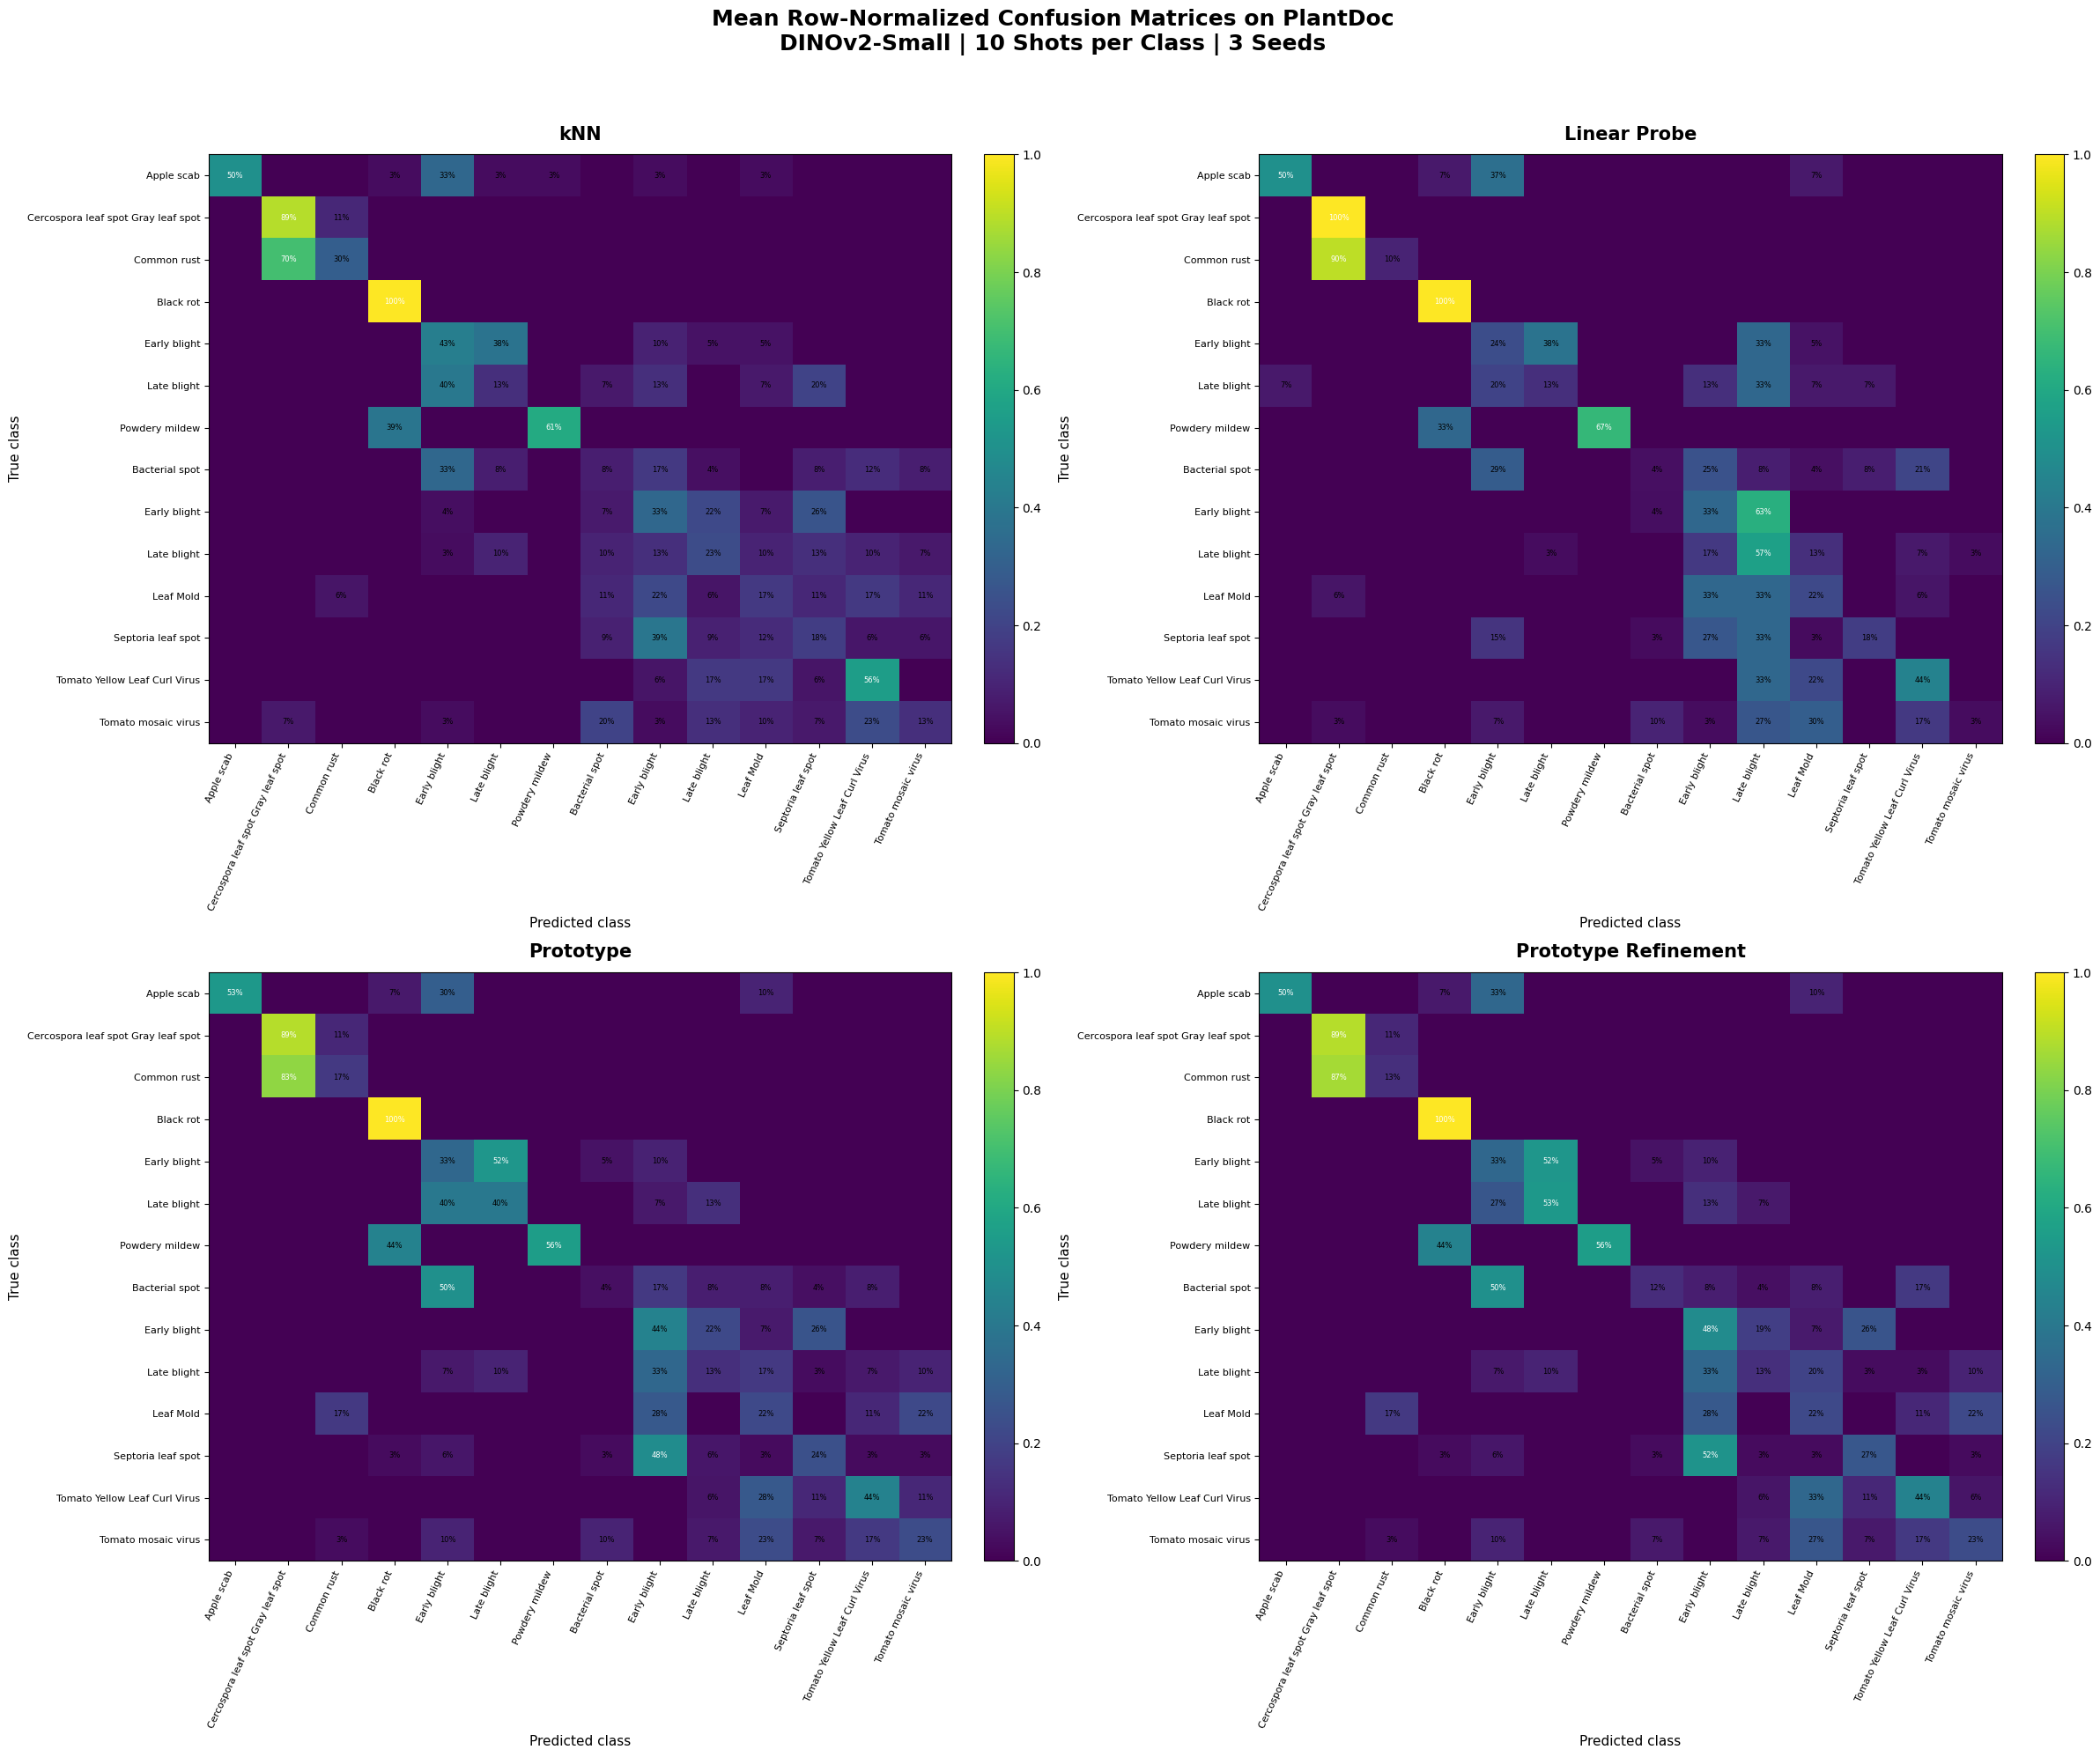


CONFUSION MATRIX VISUALIZATION COMPLETED
Models: 4
Seeds per model: 3
Classes: 14
Saved figure: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/results/final_evaluation/per_class/confusion_matrices/averaged/PlantDoc_all_models_confusion_matrices.png
Saved averaged CSV files: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/results/final_evaluation/per_class/confusion_matrices/averaged


In [ ]:

# ============================================================
# Visualize Mean Confusion Matrices on PlantDoc
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = (
    "/content/drive/MyDrive/"
    "Plant_Disease_Few_Shot_Project/"
    "results/final_evaluation/"
    "per_class"
)

CM_DIR = os.path.join(BASE_DIR, "confusion_matrices")

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "confusion_matrices",
    "averaged"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

models = [
    "kNN",
    "Linear Probe",
    "Prototype",
    "Prototype Refinement"
]

seeds = [42, 123, 2026]
domain = "PlantDoc"

# ------------------------------------------------------------
# 1. Load and average the three confusion matrices per model
# ------------------------------------------------------------

mean_matrices = {}
class_names = None

for model in models:

    matrices = []

    for seed in seeds:

        filename = f"{model}_{domain}_seed_{seed}.csv"
        filepath = os.path.join(CM_DIR, filename)

        df = pd.read_csv(filepath, index_col=0)

        if class_names is None:
            class_names = df.index.tolist()

        assert df.index.tolist() == class_names
        assert df.columns.tolist() == class_names

        matrices.append(df.to_numpy(dtype=float))

    mean_matrix = np.mean(matrices, axis=0)

    mean_matrices[model] = mean_matrix

    # Save average raw confusion matrix
    pd.DataFrame(
        mean_matrix,
        index=class_names,
        columns=class_names
    ).to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{model}_PlantDoc_mean_counts.csv"
        )
    )

# ------------------------------------------------------------
# 2. Normalize each matrix by its true-class row totals
# ------------------------------------------------------------

normalized_matrices = {}

for model, matrix in mean_matrices.items():

    row_totals = matrix.sum(axis=1, keepdims=True)

    normalized = np.divide(
        matrix,
        row_totals,
        out=np.zeros_like(matrix),
        where=row_totals != 0
    )

    normalized_matrices[model] = normalized

    pd.DataFrame(
        normalized,
        index=class_names,
        columns=class_names
    ).to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{model}_PlantDoc_mean_normalized.csv"
        )
    )

# ------------------------------------------------------------
# 3. Create readable class labels
# ------------------------------------------------------------

def shorten_class_name(name):

    name = name.split("___")[-1]

    name = name.replace("_", " ")
    name = name.replace("  ", " ")

    return name.strip()

short_names = [
    shorten_class_name(name)
    for name in class_names
]

# ------------------------------------------------------------
# 4. Plot the four confusion matrices
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(24, 20)
)

axes = axes.flatten()

for ax, model in zip(axes, models):

    matrix = normalized_matrices[model]

    image = ax.imshow(
        matrix,
        interpolation="nearest",
        aspect="auto",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        model,
        fontsize=15,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel(
        "Predicted class",
        fontsize=11
    )

    ax.set_ylabel(
        "True class",
        fontsize=11
    )

    ax.set_xticks(range(len(short_names)))
    ax.set_yticks(range(len(short_names)))

    ax.set_xticklabels(
        short_names,
        rotation=65,
        ha="right",
        fontsize=8
    )

    ax.set_yticklabels(
        short_names,
        fontsize=8
    )

    # Display percentages in cells
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):

            value = matrix[i, j]

            if value >= 0.005:

                text_color = (
                    "white" if value > 0.45 else "black"
                )

                ax.text(
                    j,
                    i,
                    f"{value:.0%}",
                    ha="center",
                    va="center",
                    fontsize=6,
                    color=text_color
                )

    fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

fig.suptitle(
    "Mean Row-Normalized Confusion Matrices on PlantDoc\n"
    "DINOv2-Small | 10 Shots per Class | 3 Seeds",
    fontsize=18,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

figure_path = os.path.join(
    OUTPUT_DIR,
    "PlantDoc_all_models_confusion_matrices.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n" + "=" * 65)
print("CONFUSION MATRIX VISUALIZATION COMPLETED")
print("=" * 65)

print("Models:", len(models))
print("Seeds per model:", len(seeds))
print("Classes:", len(class_names))
print("Saved figure:", figure_path)
print("Saved averaged CSV files:", OUTPUT_DIR)


**Inspect Confusion Matrix CSV Files**

In [ ]:
from pathlib import Path

# Project paths
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

CONFUSION_DIR = (
    PROJECT_DIR
    / "results"
    / "final_evaluation"
    / "per_class"
    / "confusion_matrices"
)

print("=" * 75)
print("CONFUSION MATRIX FILE INVENTORY")
print("=" * 75)

if not CONFUSION_DIR.exists():
    print("ERROR: Confusion matrices folder was not found.")
    print("Expected path:", CONFUSION_DIR)
else:
    csv_files = sorted(CONFUSION_DIR.rglob("*.csv"))

    print("Folder:", CONFUSION_DIR)
    print("Number of CSV files:", len(csv_files))
    print()

    for i, file_path in enumerate(csv_files, 1):
        relative_path = file_path.relative_to(CONFUSION_DIR)
        size_kb = file_path.stat().st_size / 1024

        print(f"{i:02d}. {relative_path} ({size_kb:.2f} KB)")

print("\n" + "=" * 75)

CONFUSION MATRIX FILE INVENTORY
Folder: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/results/final_evaluation/per_class/confusion_matrices
Number of CSV files: 32

01. Linear Probe_PlantDoc_seed_123.csv (1.10 KB)
02. Linear Probe_PlantDoc_seed_2026.csv (1.10 KB)
03. Linear Probe_PlantDoc_seed_42.csv (1.10 KB)
04. Linear Probe_PlantVillage_seed_123.csv (1.14 KB)
05. Linear Probe_PlantVillage_seed_2026.csv (1.14 KB)
06. Linear Probe_PlantVillage_seed_42.csv (1.14 KB)
07. Prototype Refinement_PlantDoc_seed_123.csv (1.10 KB)
08. Prototype Refinement_PlantDoc_seed_2026.csv (1.10 KB)
09. Prototype Refinement_PlantDoc_seed_42.csv (1.10 KB)
10. Prototype Refinement_PlantVillage_seed_123.csv (1.15 KB)
11. Prototype Refinement_PlantVillage_seed_2026.csv (1.14 KB)
12. Prototype Refinement_PlantVillage_seed_42.csv (1.15 KB)
13. Prototype_PlantDoc_seed_123.csv (1.10 KB)
14. Prototype_PlantDoc_seed_2026.csv (1.10 KB)
15. Prototype_PlantDoc_seed_42.csv (1.10 KB)
16. Prototype_PlantVillage_se

**Top-5 Misclassified Disease Pairs on PlantDoc**

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# TOP-5 MISCLASSIFIED DISEASE PAIRS ON PLANTDOC
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

CONFUSION_DIR = (
    PROJECT_DIR
    / "results"
    / "final_evaluation"
    / "per_class"
    / "confusion_matrices"
)

AVERAGED_DIR = CONFUSION_DIR / "averaged"

MODELS = [
    "kNN",
    "Linear Probe",
    "Prototype",
    "Prototype Refinement"
]

# ------------------------------------------------------------
# 1. Load averaged confusion matrices
# ------------------------------------------------------------

matrices = {}

print("=" * 75)
print("LOADING AVERAGED PLANTDOC CONFUSION MATRICES")
print("=" * 75)

for model in MODELS:

    file_path = (
        AVERAGED_DIR
        / f"{model}_PlantDoc_mean_counts.csv"
    )

    if not file_path.exists():
        raise FileNotFoundError(
            f"Missing confusion matrix: {file_path}"
        )

    df = pd.read_csv(file_path, index_col=0)

    if df.shape != (14, 14):
        raise ValueError(
            f"{model}: Expected (14, 14), got {df.shape}"
        )

    df = df.apply(pd.to_numeric, errors="raise")

    if df.isna().any().any():
        raise ValueError(f"{model}: NaN values detected")

    if not np.isfinite(df.to_numpy()).all():
        raise ValueError(f"{model}: Infinite values detected")

    matrices[model] = df

    print(
        f"{model:25s} | Shape: {df.shape} | "
        f"Mean total: {df.to_numpy().sum():.2f}"
    )

print("\nAll four matrices loaded successfully.")


# ------------------------------------------------------------
# 2. Extract the top 5 off-diagonal errors per model
# ------------------------------------------------------------

all_top_errors = []

print("\n" + "=" * 75)
print("TOP 5 MISCLASSIFIED DISEASE PAIRS PER MODEL")
print("=" * 75)

for model, df in matrices.items():

    error_matrix = df.copy()

    # Remove correct predictions (main diagonal)
    np.fill_diagonal(error_matrix.values, 0)

    # Convert matrix cells into individual error pairs
    errors = (
        error_matrix
        .stack()
        .reset_index()
    )

    errors.columns = [
        "True_Disease",
        "Predicted_Disease",
        "Mean_Error_Count"
    ]

    errors = errors.sort_values(
        "Mean_Error_Count",
        ascending=False
    )

    top5 = errors.head(5).copy()
    top5.insert(0, "Model", model)

    all_top_errors.append(top5)

    print(f"\nMODEL: {model}")
    print("-" * 75)

    print(
        top5.to_string(
            index=False,
            formatters={
                "Mean_Error_Count": lambda x: f"{x:.3f}"
            }
        )
    )


# ------------------------------------------------------------
# 3. Compare Prototype Refinement against Prototype
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PROTOTYPE REFINEMENT VS PROTOTYPE")
print("=" * 75)

prototype = matrices["Prototype"].to_numpy().copy()
refinement = matrices["Prototype Refinement"].to_numpy().copy()

# Remove diagonal: only classification errors matter
np.fill_diagonal(prototype, 0)
np.fill_diagonal(refinement, 0)

difference = refinement - prototype

class_names = matrices["Prototype"].index.tolist()

comparison_rows = []

for i in range(14):
    for j in range(14):

        if i == j:
            continue

        comparison_rows.append({
            "True_Disease": class_names[i],
            "Predicted_Disease": class_names[j],
            "Prototype_Errors": prototype[i, j],
            "Refinement_Errors": refinement[i, j],
            "Error_Difference": difference[i, j]
        })

comparison_df = pd.DataFrame(comparison_rows)

# Positive = refinement made more errors
# Negative = refinement reduced errors

comparison_df = comparison_df.sort_values(
    "Error_Difference",
    ascending=True
)

print("\nTOP 5 ERROR REDUCTIONS:")
print("(Negative difference means fewer errors with refinement)")

print(
    comparison_df.head(5).to_string(
        index=False,
        formatters={
            "Prototype_Errors": lambda x: f"{x:.3f}",
            "Refinement_Errors": lambda x: f"{x:.3f}",
            "Error_Difference": lambda x: f"{x:+.3f}"
        }
    )
)

print("\nTOP 5 ERROR INCREASES:")
print("(Positive difference means more errors with refinement)")

print(
    comparison_df.tail(5)
    .sort_values("Error_Difference", ascending=False)
    .to_string(
        index=False,
        formatters={
            "Prototype_Errors": lambda x: f"{x:.3f}",
            "Refinement_Errors": lambda x: f"{x:.3f}",
            "Error_Difference": lambda x: f"{x:+.3f}"
        }
    )
)


# ------------------------------------------------------------
# 4. Save results
# ------------------------------------------------------------

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "final_evaluation"
    / "per_class"
    / "confusion_matrices"
    / "error_analysis"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

top_errors_df = pd.concat(
    all_top_errors,
    ignore_index=True
)

top_errors_path = OUTPUT_DIR / "top5_errors_per_model.csv"
comparison_path = OUTPUT_DIR / "refinement_vs_prototype_error_pairs.csv"

top_errors_df.to_csv(top_errors_path, index=False)
comparison_df.to_csv(comparison_path, index=False)

print("\n" + "=" * 75)
print("ERROR ANALYSIS COMPLETED")
print("=" * 75)

print("Models analyzed:", len(MODELS))
print("Classes:", 14)
print("Top errors per model:", 5)

print("\nSaved files:")
print(top_errors_path)
print(comparison_path)


LOADING AVERAGED PLANTDOC CONFUSION MATRICES
kNN                       | Shape: (14, 14) | Mean total: 109.00
Linear Probe              | Shape: (14, 14) | Mean total: 109.00
Prototype                 | Shape: (14, 14) | Mean total: 109.00
Prototype Refinement      | Shape: (14, 14) | Mean total: 109.00

All four matrices loaded successfully.

TOP 5 MISCLASSIFIED DISEASE PAIRS PER MODEL

MODEL: kNN
---------------------------------------------------------------------------
Model                True_Disease                                  Predicted_Disease Mean_Error_Count
  kNN Corn_(maize)___Common_rust_ Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot            7.000
  kNN Tomato___Septoria_leaf_spot                              Tomato___Early_blight            4.333
  kNN          Apple___Apple_scab                              Potato___Early_blight            3.333
  kNN       Potato___Early_blight                               Potato___Late_blight            2.667
  kNN     To

**Inspect Final Prediction Artifacts**

In [ ]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

SEARCH_DIRS = [
    PROJECT_DIR / "results",
    PROJECT_DIR / "metadata",
    PROJECT_DIR / "features"
]

keywords = [
    "prediction",
    "predictions",
    "y_pred",
    "probabilities",
    "logits",
    "per_image",
    "test_output"
]

print("=" * 75)
print("SEARCHING FOR PER-IMAGE PREDICTION FILES")
print("=" * 75)

found_files = []

for search_dir in SEARCH_DIRS:

    print(f"\nSearching in: {search_dir}")

    if not search_dir.exists():
        print("Directory not found.")
        continue

    for file_path in search_dir.rglob("*"):

        if not file_path.is_file():
            continue

        name = file_path.name.lower()

        if any(keyword in name for keyword in keywords):

            size_kb = file_path.stat().st_size / 1024

            found_files.append(file_path)

            print(
                f"{file_path.relative_to(PROJECT_DIR)} "
                f"| {size_kb:.2f} KB"
            )

print("\n" + "=" * 75)
print("SEARCH SUMMARY")
print("=" * 75)

print("Matching files:", len(found_files))

if not found_files:
    print(
        "No files with prediction-related names were found."
    )


SEARCHING FOR PER-IMAGE PREDICTION FILES

Searching in: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/results

Searching in: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata

Searching in: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/features

SEARCH SUMMARY
Matching files: 0
No files with prediction-related names were found.


**Inspect Locked Evaluation Inputs**

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import json

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

METADATA_DIR = PROJECT_DIR / "metadata"

FEATURES_DIR = (
    PROJECT_DIR
    / "features"
    / "dinov2_small"
)

print("=" * 75)
print("1. FINAL EVALUATION CONFIGURATION")
print("=" * 75)

config_path = PROJECT_DIR / "final_evaluation_config.json"

with open(config_path, "r") as f:
    config = json.load(f)

print(json.dumps(config, indent=2))


print("\n" + "=" * 75)
print("2. PLANTDOC TEST MANIFEST")
print("=" * 75)

plantdoc_manifest_path = (
    METADATA_DIR / "plantdoc_external_test_manifest.csv"
)

plantdoc_df = pd.read_csv(plantdoc_manifest_path)

print("Shape:", plantdoc_df.shape)
print("Columns:", plantdoc_df.columns.tolist())
print("\nFirst 3 rows:")
print(plantdoc_df.head(3).to_string(index=False))


print("\n" + "=" * 75)
print("3. PLANTDOC EMBEDDINGS")
print("=" * 75)

plantdoc_embedding_path = (
    FEATURES_DIR
    / "plantdoc_external_test"
    / "embeddings.npy"
)

plantdoc_labels_path = (
    FEATURES_DIR
    / "plantdoc_external_test"
    / "labels.npy"
)

plantdoc_embeddings = np.load(plantdoc_embedding_path)
plantdoc_labels = np.load(plantdoc_labels_path)

print("Embeddings shape:", plantdoc_embeddings.shape)
print("Labels shape:", plantdoc_labels.shape)
print("Labels dtype:", plantdoc_labels.dtype)


print("\n" + "=" * 75)
print("4. FEW-SHOT SUPPORT SET FILES")
print("=" * 75)

support_dir = (
    METADATA_DIR / "few_shot_support_sets"
)

for shots in [1, 5, 10]:

    support_files = sorted(
        support_dir.glob(f"*{shots}*")
    )

    print(f"\nShots = {shots}")
    print("Matching files:", len(support_files))

    for file_path in support_files[:5]:

        print("\nFile:", file_path.name)

        if file_path.suffix.lower() == ".csv":

            support_df = pd.read_csv(file_path)

            print("Shape:", support_df.shape)
            print("Columns:", support_df.columns.tolist())
            print(support_df.head(2).to_string(index=False))


print("\n" + "=" * 75)
print("5. TRAINING POOL EMBEDDINGS")
print("=" * 75)

train_embeddings_path = (
    FEATURES_DIR / "train_embeddings.npy"
)

train_labels_path = (
    FEATURES_DIR / "train_labels.npy"
)

train_embeddings = np.load(train_embeddings_path)
train_labels = np.load(train_labels_path)

print("Training embeddings:", train_embeddings.shape)
print("Training labels:", train_labels.shape)

print("\nInspection completed.")


1. FINAL EVALUATION CONFIGURATION
{
  "project": {
    "name": "Few-Shot Plant Disease Recognition",
    "encoder": "facebook/dinov2-small",
    "embedding_dimension": 384,
    "input_size": 224,
    "encoder_frozen": true
  },
  "evaluation_protocol": {
    "shots_per_class": [
      1,
      5,
      10
    ],
    "seeds": [
      42,
      123,
      2026
    ],
    "number_of_classes": 14,
    "primary_metric": "Macro F1",
    "secondary_metrics": [
      "Accuracy",
      "Macro Precision",
      "Macro Recall"
    ],
    "validation_used_for_model_selection": true,
    "test_used_for_hyperparameter_tuning": false,
    "plantdoc_used_for_model_selection": false
  },
  "datasets": {
    "plantvillage_test": "metadata/plantvillage_test_manifest_clean.csv",
    "plantdoc_external_test": "metadata/plantdoc_external_test_manifest.csv",
    "plantvillage_training_pool": "metadata/plantvillage_training_pool_manifest.csv",
    "plantvillage_validation": "metadata/plantvillage_validation_m

**Verify Support and Training Pool Index Alignment**

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
import json

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

METADATA_DIR = PROJECT_DIR / "metadata"
FEATURES_DIR = PROJECT_DIR / "features" / "dinov2_small"

# ------------------------------------------------------------
# 1. Load class names and training manifests
# ------------------------------------------------------------

with open(FEATURES_DIR / "class_names.json", "r") as f:
    class_names = json.load(f)

original_train = pd.read_csv(
    METADATA_DIR / "plantvillage_train_manifest.csv"
)

training_pool = pd.read_csv(
    METADATA_DIR / "plantvillage_training_pool_manifest.csv"
)

print("=" * 75)
print("1. CLASS ORDER")
print("=" * 75)

print("Number of classes:", len(class_names))

for i, name in enumerate(class_names):
    print(f"{i:02d}: {name}")

print("\n" + "=" * 75)
print("2. TRAINING MANIFESTS")
print("=" * 75)

print("Original training manifest:", original_train.shape)
print("Training pool manifest:", training_pool.shape)

print("Original columns:", original_train.columns.tolist())
print("Pool columns:", training_pool.columns.tolist())

print("\nTraining pool first rows:")
print(training_pool.head(3).to_string(index=False))


# ------------------------------------------------------------
# 2. Verify embedding index alignment
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("3. EMBEDDING INDEX ALIGNMENT")
print("=" * 75)

train_embeddings = np.load(
    FEATURES_DIR / "train_embeddings.npy",
    mmap_mode="r"
)

train_labels = np.load(
    FEATURES_DIR / "train_labels.npy"
)

print("Embedding rows:", len(train_embeddings))
print("Label rows:", len(train_labels))
print("Original manifest rows:", len(original_train))

if "embedding_index" in training_pool.columns:

    pool_indices = training_pool["embedding_index"].to_numpy()

    print("Training pool embedding_index column: FOUND")
    print("Unique indices:", len(np.unique(pool_indices)))
    print("Minimum index:", pool_indices.min())
    print("Maximum index:", pool_indices.max())
    print(
        "All indices in range:",
        np.all(
            (pool_indices >= 0) &
            (pool_indices < len(train_embeddings))
        )
    )
else:
    print("Training pool embedding_index column: NOT FOUND")


# ------------------------------------------------------------
# 3. Verify support files using exact filenames
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("4. SUPPORT SET INDEX VALIDATION")
print("=" * 75)

support_dir = METADATA_DIR / "few_shot_support_sets"

for shots in [1, 5, 10]:

    for seed in [42, 123, 2026]:

        file_path = (
            support_dir /
            f"support_{shots}shot_seed_{seed}.csv"
        )

        if not file_path.exists():
            print(f"MISSING: {file_path.name}")
            continue

        support_df = pd.read_csv(file_path)

        indices = support_df["embedding_index"].to_numpy()

        valid_range = np.all(
            (indices >= 0) &
            (indices < len(train_embeddings))
        )

        labels_match = False

        if valid_range:
            labels_match = np.array_equal(
                train_labels[indices],
                np.array([
                    class_names.index(name)
                    for name in support_df["class_name"]
                ])
            )

        print(
            f"{shots:2d}-shot | Seed {seed:4d} | "
            f"Rows: {len(support_df):3d} | "
            f"Valid indices: {valid_range} | "
            f"Labels match: {labels_match}"
        )


# ------------------------------------------------------------
# 4. Verify PlantDoc class order
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("5. PLANTDOC CLASS ORDER")
print("=" * 75)

with open(
    FEATURES_DIR / "plantdoc_external_test" / "class_names.json",
    "r"
) as f:
    plantdoc_classes = json.load(f)

print("PlantDoc class order matches canonical order:",
      plantdoc_classes == class_names)

print("PlantDoc classes:", len(plantdoc_classes))


# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("INDEX VERIFICATION FINISHED")
print("=" * 75)


1. CLASS ORDER
Number of classes: 14
00: Apple___Apple_scab
01: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
02: Corn_(maize)___Common_rust_
03: Grape___Black_rot
04: Potato___Early_blight
05: Potato___Late_blight
06: Squash___Powdery_mildew
07: Tomato___Bacterial_spot
08: Tomato___Early_blight
09: Tomato___Late_blight
10: Tomato___Leaf_Mold
11: Tomato___Septoria_leaf_spot
12: Tomato___Tomato_Yellow_Leaf_Curl_Virus
13: Tomato___Tomato_mosaic_virus

2. TRAINING MANIFESTS
Original training manifest: (16765, 3)
Training pool manifest: (13378, 3)
Original columns: ['image_path', 'class_name', 'leaf_id']
Pool columns: ['image_path', 'class_name', 'leaf_id']

Training pool first rows:
                                                                            image_path         class_name                  leaf_id
raw/color/Apple___Apple_scab/4555c009-6c33-4913-accc-fd1a8355646b___FREC_Scab 2929.JPG Apple___Apple_scab Apple___Apple_scab:::5.0
raw/color/Apple___Apple_scab/62c3478f-3ab0-4

**Reconstruct Training Pool Embedding Indices**

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

METADATA_DIR = PROJECT_DIR / "metadata"
FEATURES_DIR = PROJECT_DIR / "features" / "dinov2_small"

# ------------------------------------------------------------
# 1. Load manifests and embeddings
# ------------------------------------------------------------

original_train = pd.read_csv(
    METADATA_DIR / "plantvillage_train_manifest.csv"
)

training_pool = pd.read_csv(
    METADATA_DIR / "plantvillage_training_pool_manifest.csv"
)

train_embeddings = np.load(
    FEATURES_DIR / "train_embeddings.npy",
    mmap_mode="r"
)

train_labels = np.load(
    FEATURES_DIR / "train_labels.npy"
)

with open(FEATURES_DIR / "class_names.json", "r") as f:
    class_names = __import__("json").load(f)

# ------------------------------------------------------------
# 2. Verify original manifest uniqueness
# ------------------------------------------------------------

print("=" * 75)
print("1. ORIGINAL MANIFEST VALIDATION")
print("=" * 75)

print("Original rows:", len(original_train))
print("Unique image paths:", original_train["image_path"].nunique())

if original_train["image_path"].duplicated().any():
    raise ValueError("Duplicate image paths in original training manifest.")

if len(original_train) != len(train_embeddings):
    raise ValueError("Manifest and embedding row counts do not match.")

# ------------------------------------------------------------
# 3. Reconstruct embedding indices
# ------------------------------------------------------------

path_to_index = {
    path: index
    for index, path in enumerate(original_train["image_path"])
}

training_pool = training_pool.copy()

training_pool["embedding_index"] = (
    training_pool["image_path"].map(path_to_index)
)

missing_indices = training_pool["embedding_index"].isna().sum()

if missing_indices:
    raise ValueError(
        f"{missing_indices} training-pool images were not found "
        "in the original training manifest."
    )

training_pool["embedding_index"] = (
    training_pool["embedding_index"].astype(int)
)

pool_indices = training_pool["embedding_index"].to_numpy()

# ------------------------------------------------------------
# 4. Validate reconstructed indices
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("2. RECONSTRUCTED INDEX VALIDATION")
print("=" * 75)

print("Training pool rows:", len(training_pool))
print("Missing indices:", missing_indices)
print("Unique indices:", len(np.unique(pool_indices)))
print("Minimum index:", pool_indices.min())
print("Maximum index:", pool_indices.max())

print(
    "All indices in range:",
    np.all(
        (pool_indices >= 0) &
        (pool_indices < len(train_embeddings))
    )
)

# ------------------------------------------------------------
# 5. Verify labels using embedding indices
# ------------------------------------------------------------

expected_labels = np.array([
    class_names.index(name)
    for name in training_pool["class_name"]
])

actual_labels = train_labels[pool_indices]

labels_match = np.array_equal(
    expected_labels,
    actual_labels
)

print("\n" + "=" * 75)
print("3. LABEL ALIGNMENT")
print("=" * 75)

print("All training-pool labels match:", labels_match)

if not labels_match:
    mismatch_positions = np.where(
        expected_labels != actual_labels
    )[0]

    print("Mismatch count:", len(mismatch_positions))
    print(training_pool.iloc[mismatch_positions[:10]])
    raise ValueError("Training-pool label alignment failed.")

# ------------------------------------------------------------
# 6. Verify support images belong to the pool
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("4. SUPPORT-POOL MEMBERSHIP")
print("=" * 75)

support_dir = METADATA_DIR / "few_shot_support_sets"

pool_paths = set(training_pool["image_path"])

for shots in [1, 5, 10]:
    for seed in [42, 123, 2026]:

        support_path = (
            support_dir /
            f"support_{shots}shot_seed_{seed}.csv"
        )

        support_df = pd.read_csv(support_path)

        missing_support = sum(
            path not in pool_paths
            for path in support_df["image_path"]
        )

        print(
            f"{shots:2d}-shot | Seed {seed:4d} | "
            f"Support images: {len(support_df):3d} | "
            f"Not in pool: {missing_support}"
        )

        if missing_support:
            raise ValueError(
                f"Support images not found in pool: "
                f"{shots}-shot, seed {seed}"
            )

# ------------------------------------------------------------
# 7. Save reconstructed manifest
# ------------------------------------------------------------

output_path = (
    METADATA_DIR / "plantvillage_training_pool_indexed.csv"
)

training_pool.to_csv(output_path, index=False)

print("\n" + "=" * 75)
print("RECONSTRUCTION COMPLETED")
print("=" * 75)

print("Saved:", output_path)
print("Rows:", len(training_pool))
print("Embedding dimension:", train_embeddings.shape[1])


1. ORIGINAL MANIFEST VALIDATION
Original rows: 16765
Unique image paths: 16765

2. RECONSTRUCTED INDEX VALIDATION
Training pool rows: 13378
Missing indices: 0
Unique indices: 13378
Minimum index: 0
Maximum index: 16762
All indices in range: True

3. LABEL ALIGNMENT
All training-pool labels match: True

4. SUPPORT-POOL MEMBERSHIP
 1-shot | Seed   42 | Support images:  14 | Not in pool: 0
 1-shot | Seed  123 | Support images:  14 | Not in pool: 0
 1-shot | Seed 2026 | Support images:  14 | Not in pool: 0
 5-shot | Seed   42 | Support images:  70 | Not in pool: 0
 5-shot | Seed  123 | Support images:  70 | Not in pool: 0
 5-shot | Seed 2026 | Support images:  70 | Not in pool: 0
10-shot | Seed   42 | Support images: 140 | Not in pool: 0
10-shot | Seed  123 | Support images: 140 | Not in pool: 0
10-shot | Seed 2026 | Support images: 140 | Not in pool: 0

RECONSTRUCTION COMPLETED
Saved: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/metadata/plantvillage_training_pool_indexed.csv
Row

**Reproduce 10-Shot Prototype Predictions**

In [ ]:

import json
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.preprocessing import normalize
from sklearn.metrics import confusion_matrix
from sklearn.metrics.pairwise import cosine_similarity

# ============================================================
# 1. PATHS AND CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"
)

METADATA_DIR = PROJECT_DIR / "metadata"
FEATURES_DIR = PROJECT_DIR / "features" / "dinov2_small"

CONFUSION_DIR = (
    PROJECT_DIR
    / "results"
    / "final_evaluation"
    / "per_class"
    / "confusion_matrices"
)

OUTPUT_DIR = (
    PROJECT_DIR
    / "results"
    / "final_evaluation"
    / "reproduced_predictions"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SHOTS = 10
SEEDS = [42, 123, 2026]
NUM_CLASSES = 14

# ------------------------------------------------------------
# Load final configuration
# ------------------------------------------------------------

with open(PROJECT_DIR / "final_evaluation_config.json", "r") as f:
    config = json.load(f)

REF_CONFIG = config["models"]["prototype_refinement"]

THRESHOLD = REF_CONFIG["confidence_threshold"]
MAX_MULTIPLIER = REF_CONFIG[
    "max_pseudo_labels_per_class_multiplier"
]

INITIAL_WEIGHT = REF_CONFIG["initial_prototype_weight"]
PSEUDO_WEIGHT = REF_CONFIG["pseudo_centroid_weight"]

# ------------------------------------------------------------
# Load class names and embeddings
# ------------------------------------------------------------

with open(FEATURES_DIR / "class_names.json", "r") as f:
    class_names = json.load(f)

train_embeddings = np.load(
    FEATURES_DIR / "train_embeddings.npy"
).astype(np.float32)

train_labels = np.load(
    FEATURES_DIR / "train_labels.npy"
)

plantdoc_embeddings = np.load(
    FEATURES_DIR
    / "plantdoc_external_test"
    / "embeddings.npy"
).astype(np.float32)

plantdoc_labels = np.load(
    FEATURES_DIR
    / "plantdoc_external_test"
    / "labels.npy"
)

training_pool = pd.read_csv(
    METADATA_DIR / "plantvillage_training_pool_indexed.csv"
)

plantdoc_manifest = pd.read_csv(
    METADATA_DIR / "plantdoc_external_test_manifest.csv"
)

# Verify dimensions and class order
assert len(class_names) == NUM_CLASSES
assert plantdoc_embeddings.shape == (109, 384)
assert np.array_equal(
    plantdoc_labels,
    np.array([
        class_names.index(name)
        for name in plantdoc_manifest["plantvillage_class"]
    ])
)

print("=" * 75)
print("10-SHOT PREDICTION REPRODUCTION")
print("=" * 75)

print("PlantDoc images:", len(plantdoc_labels))
print("Classes:", NUM_CLASSES)
print("Shots per class:", SHOTS)
print("Seeds:", SEEDS)


# ============================================================
# 2. PREPARE TRAINING POOL GROUP IDENTIFIERS
# ============================================================

training_pool = training_pool.copy()

training_pool["group_id"] = (
    training_pool["class_name"].astype(str)
    + "|||"
    + training_pool["leaf_id"].astype(str)
)

pool_indices = training_pool[
    "embedding_index"
].to_numpy(dtype=int)

pool_groups = training_pool[
    "group_id"
].to_numpy()

pool_embeddings = train_embeddings[pool_indices]


# ============================================================
# 3. REPRODUCE EACH SEED
# ============================================================

all_pseudo_counts = []

for seed in SEEDS:

    print("\n" + "=" * 75)
    print(f"SEED: {seed}")
    print("=" * 75)

    support_path = (
        METADATA_DIR
        / "few_shot_support_sets"
        / f"support_{SHOTS}shot_seed_{seed}.csv"
    )

    support_df = pd.read_csv(support_path)

    support_indices = support_df[
        "embedding_index"
    ].to_numpy(dtype=int)

    support_labels = np.array([
        class_names.index(name)
        for name in support_df["class_name"]
    ])

    # Validate support labels
    assert np.array_equal(
        train_labels[support_indices],
        support_labels
    )

    # --------------------------------------------------------
    # 3A. Standard Prototype Classifier
    # --------------------------------------------------------

    # 10-shot prototype uses normalized support embeddings
    support_features = normalize(
        train_embeddings[support_indices]
    )

    test_features = normalize(
        plantdoc_embeddings
    )

    initial_prototypes = np.vstack([
        support_features[support_labels == class_id].mean(axis=0)
        for class_id in range(NUM_CLASSES)
    ])

    prototype_scores = cosine_similarity(
        test_features,
        initial_prototypes
    )

    prototype_predictions = prototype_scores.argmax(axis=1)

    # --------------------------------------------------------
    # 3B. Prototype Refinement
    # --------------------------------------------------------

    # Exclude all images belonging to support leaf groups
    support_groups = set(
        (
            support_df["class_name"].astype(str)
            + "|||"
            + support_df["leaf_id"].astype(str)
        ).tolist()
    )

    candidate_mask = np.array([
        group not in support_groups
        for group in pool_groups
    ])

    candidate_indices = pool_indices[candidate_mask]
    candidate_features_raw = pool_embeddings[candidate_mask]

    # Normalize candidate and support embeddings
    candidate_features = normalize(
        candidate_features_raw
    )

    refinement_support = normalize(
        train_embeddings[support_indices]
    )

    initial_refinement_prototypes = np.vstack([
        refinement_support[
            support_labels == class_id
        ].mean(axis=0)
        for class_id in range(NUM_CLASSES)
    ])

    # Assign pseudo-labels using initial prototypes
    candidate_scores = cosine_similarity(
        candidate_features,
        initial_refinement_prototypes
    )

    candidate_confidences = candidate_scores.max(axis=1)
    candidate_pseudo_labels = candidate_scores.argmax(axis=1)

    refined_prototypes = initial_refinement_prototypes.copy()

    selected_total = 0

    for class_id in range(NUM_CLASSES):

        class_mask = (
            (candidate_pseudo_labels == class_id)
            &
            (candidate_confidences >= THRESHOLD)
        )

        class_positions = np.where(class_mask)[0]

        # Keep the highest-confidence candidates
        class_positions = class_positions[
            np.argsort(
                candidate_confidences[class_positions]
            )[::-1]
        ]

        max_pseudo = MAX_MULTIPLIER * SHOTS

        selected_positions = class_positions[:max_pseudo]

        selected_count = len(selected_positions)
        selected_total += selected_count

        if selected_count > 0:

            pseudo_centroid = candidate_features[
                selected_positions
            ].mean(axis=0)

            refined_prototypes[class_id] = (
                INITIAL_WEIGHT
                * initial_refinement_prototypes[class_id]
                +
                PSEUDO_WEIGHT
                * pseudo_centroid
            )

        all_pseudo_counts.append({
            "seed": seed,
            "class_id": class_id,
            "class_name": class_names[class_id],
            "selected_pseudo_labels": selected_count
        })

    # Predict PlantDoc using refined prototypes
    refinement_scores = cosine_similarity(
        test_features,
        refined_prototypes
    )

    refinement_predictions = refinement_scores.argmax(axis=1)

    # --------------------------------------------------------
    # 3C. Save per-image predictions
    # --------------------------------------------------------

    prediction_df = pd.DataFrame({
        "image_path": plantdoc_manifest["image_path"],
        "true_label": plantdoc_labels,
        "true_class": [
            class_names[i] for i in plantdoc_labels
        ],
        "prototype_prediction": prototype_predictions,
        "prototype_predicted_class": [
            class_names[i] for i in prototype_predictions
        ],
        "refinement_prediction": refinement_predictions,
        "refinement_predicted_class": [
            class_names[i] for i in refinement_predictions
        ]
    })

    prediction_path = (
        OUTPUT_DIR
        / f"PlantDoc_10shot_seed_{seed}_predictions.csv"
    )

    prediction_df.to_csv(
        prediction_path,
        index=False
    )

    # --------------------------------------------------------
    # 3D. Compare reproduced confusion matrices
    # --------------------------------------------------------

    for model_name, predictions in [
        ("Prototype", prototype_predictions),
        ("Prototype Refinement", refinement_predictions)
    ]:

        reproduced_cm = confusion_matrix(
            plantdoc_labels,
            predictions,
            labels=np.arange(NUM_CLASSES)
        )

        original_path = (
            CONFUSION_DIR
            / f"{model_name}_PlantDoc_seed_{seed}.csv"
        )

        original_df = pd.read_csv(
            original_path,
            index_col=0
        )

        original_cm = original_df.to_numpy(dtype=float)

        exact_match = np.allclose(
            reproduced_cm,
            original_cm,
            atol=1e-8
        )

        print(
            f"{model_name:25s} | "
            f"Pseudo-labels: {selected_total:4d} | "
            f"CM match: {exact_match}"
        )

        if not exact_match:
            difference = np.abs(
                reproduced_cm - original_cm
            )

            print(
                "Maximum CM difference:",
                difference.max()
            )

    print("Saved predictions:", prediction_path.name)
    print("Total pseudo-labels:", selected_total)


# ============================================================
# 4. SAVE PSEUDO-LABEL COUNTS
# ============================================================

pseudo_df = pd.DataFrame(all_pseudo_counts)

pseudo_path = (
    OUTPUT_DIR
    / "PlantDoc_10shot_pseudo_label_counts.csv"
)

pseudo_df.to_csv(
    pseudo_path,
    index=False
)

print("\n" + "=" * 75)
print("REPRODUCTION FINISHED")
print("=" * 75)

print("Prediction files:", len(SEEDS))
print("Pseudo-label audit:", pseudo_path)
print("Output directory:", OUTPUT_DIR)


10-SHOT PREDICTION REPRODUCTION
PlantDoc images: 109
Classes: 14
Shots per class: 10
Seeds: [42, 123, 2026]

SEED: 42
Prototype                 | Pseudo-labels:  260 | CM match: True
Prototype Refinement      | Pseudo-labels:  260 | CM match: True
Saved predictions: PlantDoc_10shot_seed_42_predictions.csv
Total pseudo-labels: 260

SEED: 123
Prototype                 | Pseudo-labels:  255 | CM match: True
Prototype Refinement      | Pseudo-labels:  255 | CM match: True
Saved predictions: PlantDoc_10shot_seed_123_predictions.csv
Total pseudo-labels: 255

SEED: 2026
Prototype                 | Pseudo-labels:  261 | CM match: True
Prototype Refinement      | Pseudo-labels:  261 | CM match: True
Saved predictions: PlantDoc_10shot_seed_2026_predictions.csv
Total pseudo-labels: 261

REPRODUCTION FINISHED
Prediction files: 3
Pseudo-label audit: /content/drive/MyDrive/Plant_Disease_Few_Shot_Project/results/final_evaluation/reproduced_predictions/PlantDoc_10shot_pseudo_label_counts.csv
Output di

**Inspect Reproduced Prediction Files**

In [ ]:

import os
import pandas as pd

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"

PREDICTIONS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "final_evaluation",
    "reproduced_predictions"
)

print("=" * 75)
print("INSPECTING REPRODUCED PREDICTION FILES")
print("=" * 75)

for seed in [42, 123, 2026]:

    file_path = os.path.join(
        PREDICTIONS_DIR,
        f"PlantDoc_10shot_seed_{seed}_predictions.csv"
    )

    df = pd.read_csv(file_path)

    print(f"\nSEED: {seed}")
    print("-" * 75)

    print("Shape:", df.shape)
    print("Columns:")
    for column in df.columns:
        print(" -", column)

    print("\nFirst 3 rows:")
    display(df.head(3))

    print("\nMissing values:")
    print(df.isna().sum())


INSPECTING REPRODUCED PREDICTION FILES

SEED: 42
---------------------------------------------------------------------------
Shape: (109, 7)
Columns:
 - image_path
 - true_label
 - true_class
 - prototype_prediction
 - prototype_predicted_class
 - refinement_prediction
 - refinement_predicted_class

First 3 rows:


,image_path,true_label,true_class,prototype_prediction,prototype_predicted_class,refinement_prediction,refinement_predicted_class
0,test/Apple Scab Leaf/052609%20Hartman%20Crabap...,0,Apple___Apple_scab,0,Apple___Apple_scab,0,Apple___Apple_scab
1,test/Apple Scab Leaf/1b321015-6e33-4f18-aade-8...,0,Apple___Apple_scab,4,Potato___Early_blight,4,Potato___Early_blight
2,test/Apple Scab Leaf/28-500x375.jpg,0,Apple___Apple_scab,10,Tomato___Leaf_Mold,10,Tomato___Leaf_Mold



Missing values:
image_path                    0
true_label                    0
true_class                    0
prototype_prediction          0
prototype_predicted_class     0
refinement_prediction         0
refinement_predicted_class    0
dtype: int64

SEED: 123
---------------------------------------------------------------------------
Shape: (109, 7)
Columns:
 - image_path
 - true_label
 - true_class
 - prototype_prediction
 - prototype_predicted_class
 - refinement_prediction
 - refinement_predicted_class

First 3 rows:


,image_path,true_label,true_class,prototype_prediction,prototype_predicted_class,refinement_prediction,refinement_predicted_class
0,test/Apple Scab Leaf/052609%20Hartman%20Crabap...,0,Apple___Apple_scab,0,Apple___Apple_scab,0,Apple___Apple_scab
1,test/Apple Scab Leaf/1b321015-6e33-4f18-aade-8...,0,Apple___Apple_scab,4,Potato___Early_blight,4,Potato___Early_blight
2,test/Apple Scab Leaf/28-500x375.jpg,0,Apple___Apple_scab,10,Tomato___Leaf_Mold,10,Tomato___Leaf_Mold



Missing values:
image_path                    0
true_label                    0
true_class                    0
prototype_prediction          0
prototype_predicted_class     0
refinement_prediction         0
refinement_predicted_class    0
dtype: int64

SEED: 2026
---------------------------------------------------------------------------
Shape: (109, 7)
Columns:
 - image_path
 - true_label
 - true_class
 - prototype_prediction
 - prototype_predicted_class
 - refinement_prediction
 - refinement_predicted_class

First 3 rows:


,image_path,true_label,true_class,prototype_prediction,prototype_predicted_class,refinement_prediction,refinement_predicted_class
0,test/Apple Scab Leaf/052609%20Hartman%20Crabap...,0,Apple___Apple_scab,0,Apple___Apple_scab,0,Apple___Apple_scab
1,test/Apple Scab Leaf/1b321015-6e33-4f18-aade-8...,0,Apple___Apple_scab,4,Potato___Early_blight,4,Potato___Early_blight
2,test/Apple Scab Leaf/28-500x375.jpg,0,Apple___Apple_scab,10,Tomato___Leaf_Mold,10,Tomato___Leaf_Mold



Missing values:
image_path                    0
true_label                    0
true_class                    0
prototype_prediction          0
prototype_predicted_class     0
refinement_prediction         0
refinement_predicted_class    0
dtype: int64


**Paired Statistical Comparison: Prototype vs Prototype Refinement**

In [ ]:

import os
import pandas as pd
import numpy as np
from scipy.stats import binomtest

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"

PREDICTIONS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "final_evaluation",
    "reproduced_predictions"
)

seeds = [42, 123, 2026]

results = []

print("=" * 80)
print("PAIRED STATISTICAL COMPARISON")
print("Prototype vs Prototype Refinement")
print("=" * 80)

for seed in seeds:

    file_path = os.path.join(
        PREDICTIONS_DIR,
        f"PlantDoc_10shot_seed_{seed}_predictions.csv"
    )

    df = pd.read_csv(file_path)

    # Verify that all predictions refer to the same test images
    assert len(df) == 109
    assert df["image_path"].is_unique
    assert df["true_label"].notna().all()

    y_true = df["true_label"].to_numpy()
    pred_proto = df["prototype_prediction"].to_numpy()
    pred_refine = df["refinement_prediction"].to_numpy()

    # Correctness of each model for every image
    proto_correct = pred_proto == y_true
    refine_correct = pred_refine == y_true

    # Discordant paired outcomes
    # Prototype wrong, Refinement correct
    b = int(np.sum((~proto_correct) & refine_correct))

    # Prototype correct, Refinement wrong
    c = int(np.sum(proto_correct & (~refine_correct)))

    # Exact two-sided McNemar test
    discordant = b + c

    if discordant > 0:
        p_value = binomtest(
            k=b,
            n=discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue
    else:
        p_value = 1.0

    # Accuracy
    proto_accuracy = np.mean(proto_correct)
    refine_accuracy = np.mean(refine_correct)

    accuracy_difference = refine_accuracy - proto_accuracy

    results.append({
        "seed": seed,
        "prototype_accuracy": proto_accuracy,
        "refinement_accuracy": refine_accuracy,
        "accuracy_difference": accuracy_difference,
        "prototype_wrong_refinement_correct": b,
        "prototype_correct_refinement_wrong": c,
        "discordant_pairs": discordant,
        "mcnemar_p_value": p_value
    })

    print(f"\nSEED: {seed}")
    print("-" * 80)
    print(f"Prototype Accuracy:             {proto_accuracy:.4f}")
    print(f"Refinement Accuracy:             {refine_accuracy:.4f}")
    print(f"Accuracy Difference:             {accuracy_difference:+.4f}")
    print(f"Prototype wrong / Refinement correct (b): {b}")
    print(f"Prototype correct / Refinement wrong (c): {c}")
    print(f"Discordant pairs:                {discordant}")
    print(f"Exact McNemar p-value:           {p_value:.6f}")


# ---------------------------------------------------------
# Holm correction for the three statistical tests
# ---------------------------------------------------------

results_df = pd.DataFrame(results)

p_values = results_df["mcnemar_p_value"].to_numpy()
number_of_tests = len(p_values)

order = np.argsort(p_values)
adjusted_p = np.empty(number_of_tests)

running_max = 0.0

for rank, index in enumerate(order):
    adjusted = (number_of_tests - rank) * p_values[index]
    running_max = max(running_max, adjusted)
    adjusted_p[index] = min(running_max, 1.0)

results_df["holm_adjusted_p_value"] = adjusted_p

results_df["significant_at_0.05"] = (
    results_df["holm_adjusted_p_value"] < 0.05
)

print("\n" + "=" * 80)
print("FINAL RESULTS WITH HOLM CORRECTION")
print("=" * 80)

display(
    results_df.round(6)
)

# Save statistical results
output_path = os.path.join(
    PREDICTIONS_DIR,
    "PlantDoc_10shot_paired_statistical_tests.csv"
)

results_df.to_csv(output_path, index=False)

print("\nResults saved to:")
print(output_path)


PAIRED STATISTICAL COMPARISON
Prototype vs Prototype Refinement

SEED: 42
--------------------------------------------------------------------------------
Prototype Accuracy:             0.3670
Refinement Accuracy:             0.3853
Accuracy Difference:             +0.0183
Prototype wrong / Refinement correct (b): 2
Prototype correct / Refinement wrong (c): 0
Discordant pairs:                2
Exact McNemar p-value:           0.500000

SEED: 123
--------------------------------------------------------------------------------
Prototype Accuracy:             0.3670
Refinement Accuracy:             0.3670
Accuracy Difference:             +0.0000
Prototype wrong / Refinement correct (b): 0
Prototype correct / Refinement wrong (c): 0
Discordant pairs:                0
Exact McNemar p-value:           1.000000

SEED: 2026
--------------------------------------------------------------------------------
Prototype Accuracy:             0.3670
Refinement Accuracy:             0.3853
Accuracy Di

,seed,prototype_accuracy,refinement_accuracy,accuracy_difference,prototype_wrong_refinement_correct,prototype_correct_refinement_wrong,discordant_pairs,mcnemar_p_value,holm_adjusted_p_value,significant_at_0.05
0,42,0.366972,0.385321,0.018349,2,0,2,0.5000,1.0,False
1,123,0.366972,0.366972,0.000000,0,0,0,1.0000,1.0,False
2,2026,0.366972,0.385321,0.018349,4,2,6,0.6875,1.0,False



Results saved to:
/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/results/final_evaluation/reproduced_predictions/PlantDoc_10shot_paired_statistical_tests.csv


**Macro F1 Comparison**

In [ ]:

import os
import numpy as np
import pandas as pd

from sklearn.metrics import f1_score

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"

PREDICTIONS_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "final_evaluation",
    "reproduced_predictions"
)

SEEDS = [42, 123, 2026]
N_BOOTSTRAP = 10000
N_CLASSES = 14

results = []

print("=" * 85)
print("PAIRED STRATIFIED BOOTSTRAP: MACRO F1")
print("Prototype vs Prototype Refinement")
print("=" * 85)

for seed in SEEDS:

    file_path = os.path.join(
        PREDICTIONS_DIR,
        f"PlantDoc_10shot_seed_{seed}_predictions.csv"
    )

    df = pd.read_csv(file_path)

    y_true = df["true_label"].to_numpy()
    pred_proto = df["prototype_prediction"].to_numpy()
    pred_refine = df["refinement_prediction"].to_numpy()

    labels = np.arange(N_CLASSES)

    # Verify all 14 classes are represented
    unique_classes = np.unique(y_true)

    assert len(unique_classes) == N_CLASSES, (
        f"Expected {N_CLASSES} classes, found {len(unique_classes)}"
    )

    # Original Macro F1 scores
    original_proto_f1 = f1_score(
        y_true,
        pred_proto,
        labels=labels,
        average="macro",
        zero_division=0
    )

    original_refine_f1 = f1_score(
        y_true,
        pred_refine,
        labels=labels,
        average="macro",
        zero_division=0
    )

    original_difference = original_refine_f1 - original_proto_f1

    # Indices grouped by true class for stratified resampling
    class_indices = {
        class_id: np.where(y_true == class_id)[0]
        for class_id in labels
    }

    rng = np.random.default_rng(seed=seed + 10000)

    bootstrap_differences = np.empty(N_BOOTSTRAP)

    for b in range(N_BOOTSTRAP):

        sampled_indices = []

        # Resample within each class, preserving its original support
        for class_id in labels:

            indices = class_indices[class_id]

            sampled = rng.choice(
                indices,
                size=len(indices),
                replace=True
            )

            sampled_indices.extend(sampled)

        sampled_indices = np.asarray(sampled_indices)

        # Both models use exactly the same sampled images
        y_boot = y_true[sampled_indices]
        proto_boot = pred_proto[sampled_indices]
        refine_boot = pred_refine[sampled_indices]

        proto_f1 = f1_score(
            y_boot,
            proto_boot,
            labels=labels,
            average="macro",
            zero_division=0
        )

        refine_f1 = f1_score(
            y_boot,
            refine_boot,
            labels=labels,
            average="macro",
            zero_division=0
        )

        bootstrap_differences[b] = refine_f1 - proto_f1

    # Percentile confidence interval
    ci_lower, ci_upper = np.percentile(
        bootstrap_differences,
        [2.5, 97.5]
    )

    # Descriptive proportion of bootstrap differences above zero
    bootstrap_positive_fraction = np.mean(
        bootstrap_differences > 0
    )

    results.append({
        "seed": seed,
        "prototype_macro_f1": original_proto_f1,
        "refinement_macro_f1": original_refine_f1,
        "macro_f1_difference": original_difference,
        "ci_95_lower": ci_lower,
        "ci_95_upper": ci_upper,
        "bootstrap_positive_fraction": bootstrap_positive_fraction
    })

    print(f"\nSEED: {seed}")
    print("-" * 85)
    print(f"Prototype Macro F1:          {original_proto_f1:.4f}")
    print(f"Refinement Macro F1:         {original_refine_f1:.4f}")
    print(f"Observed F1 Difference:      {original_difference:+.4f}")
    print(f"95% Bootstrap CI:            [{ci_lower:.4f}, {ci_upper:.4f}]")
    print(f"Bootstrap differences > 0:   {bootstrap_positive_fraction:.4f}")


# ---------------------------------------------------------
# Display and save results
# ---------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n" + "=" * 85)
print("FINAL PAIRED BOOTSTRAP RESULTS")
print("=" * 85)

display(results_df.round(6))

# Descriptive summary across the three seeds
mean_difference = results_df["macro_f1_difference"].mean()
std_difference = results_df["macro_f1_difference"].std(ddof=1)

print("\nAcross-seed descriptive summary:")
print(f"Mean Macro F1 difference: {mean_difference:+.6f}")
print(f"Standard deviation:       {std_difference:.6f}")

output_path = os.path.join(
    PREDICTIONS_DIR,
    "PlantDoc_10shot_paired_macro_f1_bootstrap.csv"
)

results_df.to_csv(output_path, index=False)

print("\nResults saved to:")
print(output_path)


PAIRED STRATIFIED BOOTSTRAP: MACRO F1
Prototype vs Prototype Refinement

SEED: 42
-------------------------------------------------------------------------------------
Prototype Macro F1:          0.3610
Refinement Macro F1:         0.3808
Observed F1 Difference:      +0.0198
95% Bootstrap CI:            [-0.0034, 0.0492]
Bootstrap differences > 0:   0.8993

SEED: 123
-------------------------------------------------------------------------------------
Prototype Macro F1:          0.3484
Refinement Macro F1:         0.3506
Observed F1 Difference:      +0.0022
95% Bootstrap CI:            [-0.0011, 0.0076]
Bootstrap differences > 0:   0.7403

SEED: 2026
-------------------------------------------------------------------------------------
Prototype Macro F1:          0.3650
Refinement Macro F1:         0.3867
Observed F1 Difference:      +0.0216
95% Bootstrap CI:            [-0.0210, 0.0631]
Bootstrap differences > 0:   0.8268

FINAL PAIRED BOOTSTRAP RESULTS


,seed,prototype_macro_f1,refinement_macro_f1,macro_f1_difference,ci_95_lower,ci_95_upper,bootstrap_positive_fraction
0,42,0.361027,0.380819,0.019792,-0.003362,0.049181,0.8993
1,123,0.348354,0.350600,0.002246,-0.001050,0.007643,0.7403
2,2026,0.365023,0.386655,0.021632,-0.021002,0.063135,0.8268



Across-seed descriptive summary:
Mean Macro F1 difference: +0.014557
Standard deviation:       0.010701

Results saved to:
/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/results/final_evaluation/reproduced_predictions/PlantDoc_10shot_paired_macro_f1_bootstrap.csv


**Generate Final Results Tables and Supporting Figures**

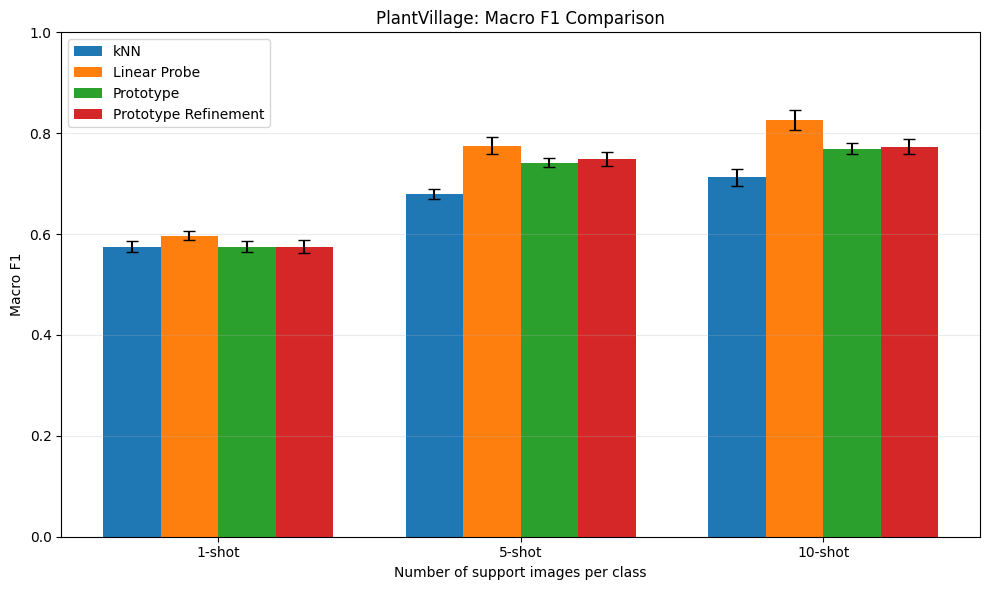

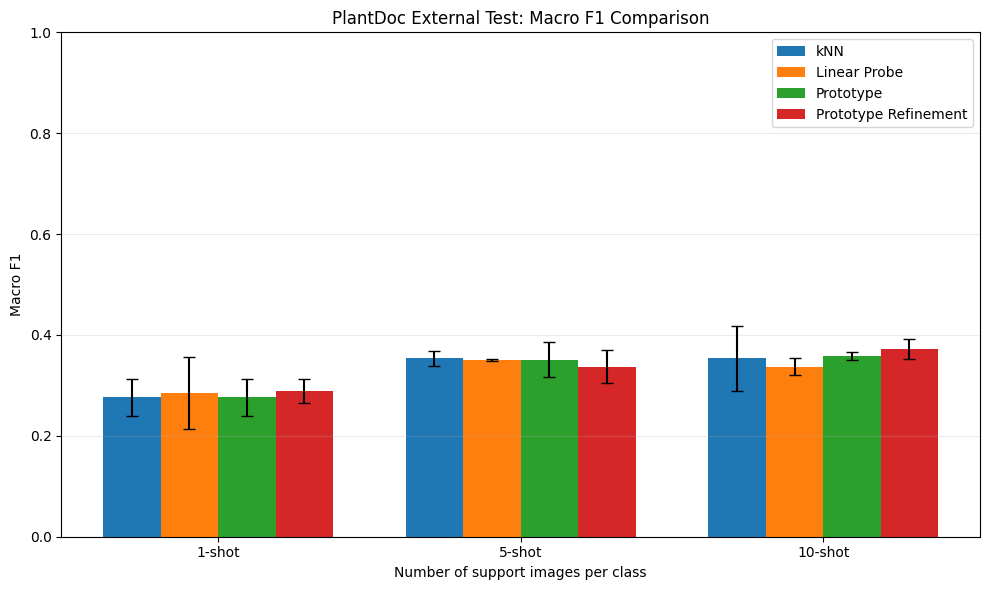

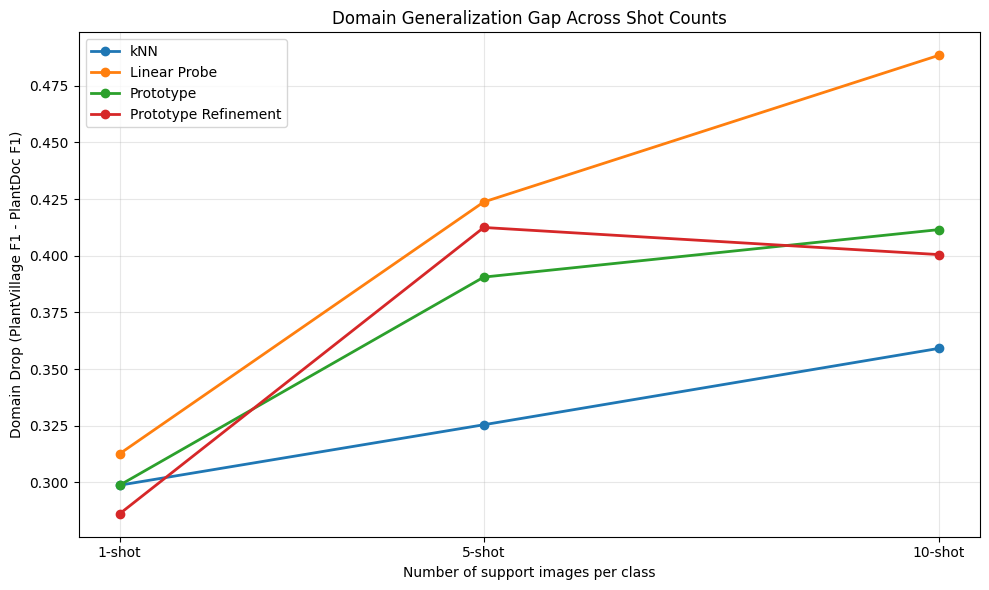

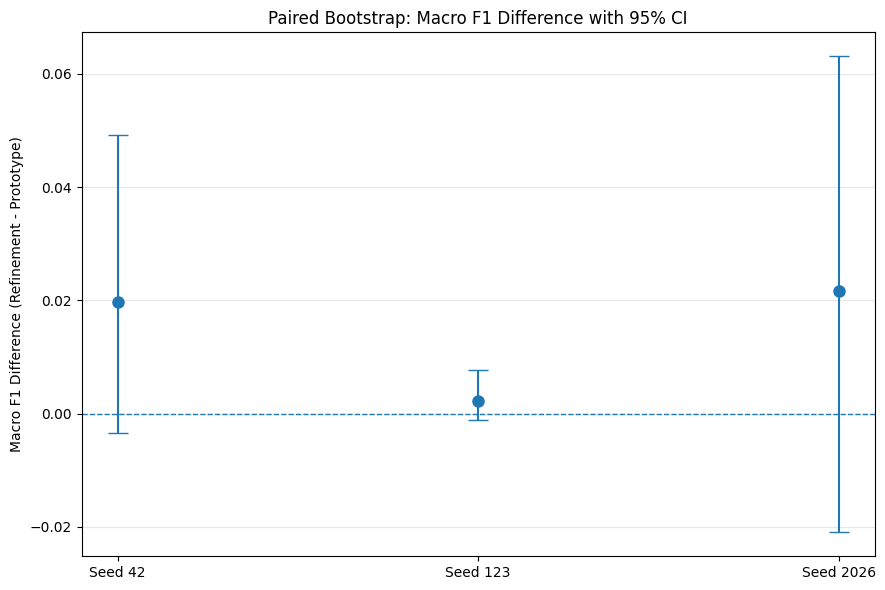


FINAL REPORT ASSETS GENERATED

Output directory:
/content/drive/MyDrive/Plant_Disease_Few_Shot_Project/results/final_report_assets

Files:
 - domain_drop_comparison.csv
 - figure_1_plantvillage_macro_f1.png
 - figure_2_plantdoc_macro_f1.png
 - figure_3_domain_drop.png
 - figure_4_paired_bootstrap_ci.png
 - final_model_comparison.csv
 - mcnemar_statistical_results.csv
 - paired_macro_f1_bootstrap.csv

Number of model comparison records: 24
Number of domain-drop records: 12
Number of statistical test records: 3
Number of bootstrap records: 3

All tables and figures were saved successfully.


In [ ]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1. PROJECT PATHS
# =========================================================

PROJECT_DIR = "/content/drive/MyDrive/Plant_Disease_Few_Shot_Project"

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "final_report_assets"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# =========================================================
# 2. FINAL MODEL COMPARISON DATA
# Mean and standard deviation across 3 seeds
# =========================================================

records = [
    # kNN - PlantDoc
    ["kNN", 1, "PlantDoc", 0.276328, 0.037269, 0.293578],
    ["kNN", 5, "PlantDoc", 0.353514, 0.014224, 0.360856],
    ["kNN", 10, "PlantDoc", 0.353714, 0.064175, 0.363914],

    # kNN - PlantVillage
    ["kNN", 1, "PlantVillage", 0.575061, 0.010587, 0.602982],
    ["kNN", 5, "PlantVillage", 0.678927, 0.009745, 0.684627],
    ["kNN", 10, "PlantVillage", 0.712842, 0.016921, 0.725985],

    # Linear Probe - PlantDoc
    ["Linear Probe", 1, "PlantDoc", 0.284449, 0.071413, 0.308869],
    ["Linear Probe", 5, "PlantDoc", 0.351084, 0.002160, 0.373089],
    ["Linear Probe", 10, "PlantDoc", 0.336810, 0.016878, 0.354740],

    # Linear Probe - PlantVillage
    ["Linear Probe", 1, "PlantVillage", 0.597050, 0.009418, 0.632312],
    ["Linear Probe", 5, "PlantVillage", 0.774832, 0.016851, 0.790163],
    ["Linear Probe", 10, "PlantVillage", 0.825306, 0.019839, 0.833910],

    # Prototype - PlantDoc
    ["Prototype", 1, "PlantDoc", 0.276328, 0.037269, 0.293578],
    ["Prototype", 5, "PlantDoc", 0.350962, 0.035284, 0.360856],
    ["Prototype", 10, "PlantDoc", 0.358135, 0.008703, 0.366972],

    # Prototype - PlantVillage
    ["Prototype", 1, "PlantVillage", 0.575061, 0.010587, 0.602982],
    ["Prototype", 5, "PlantVillage", 0.741546, 0.009110, 0.753996],
    ["Prototype", 10, "PlantVillage", 0.769682, 0.010375, 0.787197],

    # Prototype Refinement - PlantDoc
    ["Prototype Refinement", 1, "PlantDoc", 0.288830, 0.023165, 0.308869],
    ["Prototype Refinement", 5, "PlantDoc", 0.336551, 0.032703, 0.351682],
    ["Prototype Refinement", 10, "PlantDoc", 0.372691, 0.019353, 0.379205],

    # Prototype Refinement - PlantVillage
    ["Prototype Refinement", 1, "PlantVillage", 0.574940, 0.012360, 0.601829],
    ["Prototype Refinement", 5, "PlantVillage", 0.749039, 0.013319, 0.760010],
    ["Prototype Refinement", 10, "PlantVillage", 0.773203, 0.014986, 0.790081],
]

comparison_df = pd.DataFrame(
    records,
    columns=[
        "model",
        "shots",
        "dataset",
        "macro_f1_mean",
        "macro_f1_std",
        "accuracy_mean"
    ]
)

comparison_df["macro_f1_mean_std"] = (
    comparison_df["macro_f1_mean"].map(lambda x: f"{x:.4f}")
    + " ± "
    + comparison_df["macro_f1_std"].map(lambda x: f"{x:.4f}")
)

comparison_df.to_csv(
    os.path.join(OUTPUT_DIR, "final_model_comparison.csv"),
    index=False
)

# =========================================================
# 3. DOMAIN DROP TABLE
# =========================================================

pivot_f1 = comparison_df.pivot(
    index=["model", "shots"],
    columns="dataset",
    values="macro_f1_mean"
).reset_index()

pivot_f1["domain_drop"] = (
    pivot_f1["PlantVillage"] - pivot_f1["PlantDoc"]
)

pivot_f1 = pivot_f1.rename(columns={
    "PlantVillage": "plantvillage_macro_f1",
    "PlantDoc": "plantdoc_macro_f1"
})

pivot_f1.to_csv(
    os.path.join(OUTPUT_DIR, "domain_drop_comparison.csv"),
    index=False
)

# =========================================================
# 4. STATISTICAL RESULTS
# =========================================================

mcnemar_df = pd.DataFrame([
    [42, 0.366972, 0.385321, 0.018349, 2, 0, 2, 0.500000, 1.000000],
    [123, 0.366972, 0.366972, 0.000000, 0, 0, 0, 1.000000, 1.000000],
    [2026, 0.366972, 0.385321, 0.018349, 4, 2, 6, 0.687500, 1.000000],
], columns=[
    "seed",
    "prototype_accuracy",
    "refinement_accuracy",
    "accuracy_difference",
    "prototype_wrong_refinement_correct",
    "prototype_correct_refinement_wrong",
    "discordant_pairs",
    "mcnemar_p_value",
    "holm_adjusted_p_value"
])

mcnemar_df.to_csv(
    os.path.join(OUTPUT_DIR, "mcnemar_statistical_results.csv"),
    index=False
)

bootstrap_df = pd.DataFrame([
    [42, 0.361027, 0.380819, 0.019792, -0.003362, 0.049181, 0.8993],
    [123, 0.348354, 0.350600, 0.002246, -0.001050, 0.007643, 0.7403],
    [2026, 0.365023, 0.386655, 0.021632, -0.021002, 0.063135, 0.8268],
], columns=[
    "seed",
    "prototype_macro_f1",
    "refinement_macro_f1",
    "macro_f1_difference",
    "ci_95_lower",
    "ci_95_upper",
    "bootstrap_positive_fraction"
])

bootstrap_df.to_csv(
    os.path.join(OUTPUT_DIR, "paired_macro_f1_bootstrap.csv"),
    index=False
)

# =========================================================
# 5. FIGURE 1: PLANTVILLAGE MACRO F1
# =========================================================

model_order = [
    "kNN",
    "Linear Probe",
    "Prototype",
    "Prototype Refinement"
]

shots_order = [1, 5, 10]

def plot_domain_macro_f1(dataset_name, filename, title):

    subset = comparison_df[
        comparison_df["dataset"] == dataset_name
    ]

    x = np.arange(len(shots_order))
    width = 0.19

    plt.figure(figsize=(10, 6))

    for i, model in enumerate(model_order):

        model_data = (
            subset[subset["model"] == model]
            .set_index("shots")
            .reindex(shots_order)
        )

        positions = x + (i - 1.5) * width

        plt.bar(
            positions,
            model_data["macro_f1_mean"],
            width,
            yerr=model_data["macro_f1_std"],
            capsize=4,
            label=model
        )

    plt.xticks(x, ["1-shot", "5-shot", "10-shot"])
    plt.ylabel("Macro F1")
    plt.xlabel("Number of support images per class")
    plt.title(title)
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()

    plt.savefig(
        os.path.join(OUTPUT_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


plot_domain_macro_f1(
    "PlantVillage",
    "figure_1_plantvillage_macro_f1.png",
    "PlantVillage: Macro F1 Comparison"
)

# =========================================================
# 6. FIGURE 2: PLANTDOC MACRO F1
# =========================================================

plot_domain_macro_f1(
    "PlantDoc",
    "figure_2_plantdoc_macro_f1.png",
    "PlantDoc External Test: Macro F1 Comparison"
)

# =========================================================
# 7. FIGURE 3: DOMAIN DROP
# =========================================================

plt.figure(figsize=(10, 6))

for model in model_order:

    model_data = (
        pivot_f1[pivot_f1["model"] == model]
        .set_index("shots")
        .reindex(shots_order)
    )

    plt.plot(
        shots_order,
        model_data["domain_drop"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.xticks(shots_order, ["1-shot", "5-shot", "10-shot"])
plt.xlabel("Number of support images per class")
plt.ylabel("Domain Drop (PlantVillage F1 - PlantDoc F1)")
plt.title("Domain Generalization Gap Across Shot Counts")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "figure_3_domain_drop.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =========================================================
# 8. FIGURE 4: PAIRED MACRO F1 DIFFERENCE WITH 95% CI
# =========================================================

x = np.arange(len(bootstrap_df))

lower_error = (
    bootstrap_df["macro_f1_difference"]
    - bootstrap_df["ci_95_lower"]
)

upper_error = (
    bootstrap_df["ci_95_upper"]
    - bootstrap_df["macro_f1_difference"]
)

plt.figure(figsize=(9, 6))

plt.errorbar(
    x,
    bootstrap_df["macro_f1_difference"],
    yerr=np.vstack([lower_error, upper_error]),
    fmt="o",
    capsize=7,
    markersize=8
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xticks(
    x,
    [f"Seed {seed}" for seed in bootstrap_df["seed"]]
)

plt.ylabel("Macro F1 Difference (Refinement - Prototype)")
plt.title("Paired Bootstrap: Macro F1 Difference with 95% CI")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "figure_4_paired_bootstrap_ci.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# =========================================================
# 9. FINAL SUMMARY
# =========================================================

print("\n" + "=" * 80)
print("FINAL REPORT ASSETS GENERATED")
print("=" * 80)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nFiles:")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)

print("\nNumber of model comparison records:", len(comparison_df))
print("Number of domain-drop records:", len(pivot_f1))
print("Number of statistical test records:", len(mcnemar_df))
print("Number of bootstrap records:", len(bootstrap_df))

print("\nAll tables and figures were saved successfully.")
